# 1. 数据加载、审计与清洗

读取原始数据预览后，先检查并删除完整重复记录，再对清洗后的数据依次进行基础有效性和历史计数一致性审计。后续 EDA、切分、特征工程与模型代码沿用原流程，输入改为清洗后的数据。现有已保存输出是旧数据版本的结果，待重新运行后更新。


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

filename = "settles.acl16.learning_traces.13m.csv.gz"
candidates = [Path("data/raw") / filename, Path("../data/raw") / filename]
data_path = next((p.resolve() for p in candidates if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError(f"找不到 {filename}；请把数据放到项目的 data/raw/ 下。")

preview = pd.read_csv(data_path, compression="gzip", nrows=5)
print("原始文件：", data_path)
print("前 5 行：")
display(preview)


原始文件： C:\Users\horace\Documents\Projects\Data_analytics\3544-project\data\raw\settles.acl16.learning_traces.13m.csv.gz
前 5 行：


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
0,1.0,1362076081,27649635,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,6,4,2,2
1,0.5,1362076081,27649635,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,4,4,2,1
2,1.0,1362076081,27649635,u:FO,de,en,35a54c25a2cda8127343f6a82e6f6b7d,mann/mann<n><m><sg><nom>,5,4,1,1
3,0.5,1362076081,27649635,u:FO,de,en,0cf63ffe3dda158bc3dbd55682b355ae,frau/frau<n><f><sg><nom>,6,5,2,1
4,1.0,1362076081,27649635,u:FO,de,en,84920990d78044db53c1b012f5bf9ab5,das/das<det><def><nt><sg><nom>,4,4,1,1


## 1.1 完整重复记录检查与去重

以原始 CSV 的全部字段判断完整重复；保留原始文件中最早出现的一行，删除后续重复行，并保持其余行的原始顺序。先用分桶指纹定位候选，再逐字段确认，以免将哈希碰撞误判为重复。首次运行写出 `data/processed/` 下的清洗文件和清单；之后若原始文件及清单未变，直接复用，不再重做全量审计。


In [ ]:
import csv
import gzip
import hashlib
import os
import tempfile
from contextlib import ExitStack
import json

CP2_FIELDS = (
    "p_recall", "timestamp", "delta", "user_id", "learning_language",
    "ui_language", "lexeme_id", "lexeme_string", "history_seen",
    "history_correct", "session_seen", "session_correct",
)
raw_candidates = [Path("data/raw") / filename, Path("../data/raw") / filename]
raw_data_path = next((path.resolve() for path in raw_candidates if path.is_file()), None)
if raw_data_path is None:
    raise FileNotFoundError(f"Missing raw data: {filename}")
project_data_dir = raw_data_path.parent.parent
processed_dir = project_data_dir / "processed"
interim_dir = project_data_dir / "interim"
reports_dir = project_data_dir.parent / "reports"
for directory in (processed_dir, interim_dir, reports_dir):
    directory.mkdir(parents=True, exist_ok=True)
cleaned_data_path = processed_dir / "settles.acl16.learning_traces.13m.dedup_v1.csv.gz"
clean_manifest_path = processed_dir / "settles.acl16.learning_traces.13m.dedup_v1.json"
duplicate_report_path = reports_dir / "exact_duplicates_v1.json"

def cp2_file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def cp2_raw_rows(path):
    with gzip.open(path, "rt", encoding="utf-8", newline="") as stream:
        reader = csv.reader(stream)
        if tuple(next(reader)) != CP2_FIELDS:
            raise ValueError("Unexpected raw CSV header")
        yield from enumerate(reader)

def cp2_row_digest(row):
    return hashlib.blake2b(repr(tuple(row)).encode("utf-8"), digest_size=16).digest()

def cp2_find_exact_duplicates(path):
    with tempfile.TemporaryDirectory(prefix="cp2_dedup_", dir=interim_dir) as temp:
        bucket_paths = [Path(temp) / f"{i:02x}.bin" for i in range(256)]
        with ExitStack() as stack:
            buckets = [
                stack.enter_context(bucket.open("wb")) for bucket in bucket_paths
            ]
            raw_rows = 0
            for index, row in cp2_raw_rows(path):
                digest = cp2_row_digest(row)
                buckets[digest[0]].write(digest)
                raw_rows += 1
        candidates = set()
        for bucket_path in bucket_paths:
            seen = set()
            with bucket_path.open("rb") as stream:
                for digest in iter(lambda: stream.read(16), b""):
                    if digest in seen:
                        candidates.add(digest)
                    else:
                        seen.add(digest)
    first_rows = {}
    duplicate_indices = []
    examples = []
    if candidates:
        for index, row in cp2_raw_rows(path):
            digest = cp2_row_digest(row)
            if digest not in candidates:
                continue
            complete_row = tuple(row)
            seen = first_rows.setdefault(digest, [])
            first = next(
                (prior_index for previous, prior_index in seen
                 if previous == complete_row),
                None,
            )
            if first is None:
                seen.append((complete_row, index))
            else:
                duplicate_indices.append(index)
                if len(examples) < 10:
                    examples.append({
                        "first_row_index": first,
                        "duplicate_row_index": index,
                    })
    return raw_rows, duplicate_indices, examples

raw_stat = raw_data_path.stat()
clean_manifest = (
    json.loads(clean_manifest_path.read_text(encoding="utf-8"))
    if clean_manifest_path.is_file() else {}
)
clean_valid = (
    cleaned_data_path.is_file()
    and duplicate_report_path.is_file()
    and clean_manifest.get("version") == 1
    and clean_manifest.get("raw_file") == raw_data_path.name
    and clean_manifest.get("raw_size_bytes") == raw_stat.st_size
    and clean_manifest.get("raw_mtime_ns") == raw_stat.st_mtime_ns
    and clean_manifest.get("clean_size_bytes") == cleaned_data_path.stat().st_size
    and clean_manifest.get("clean_mtime_ns") == cleaned_data_path.stat().st_mtime_ns
    and clean_manifest.get("raw_rows", 0) > 0
    and clean_manifest.get("clean_rows", 0) > 0
)
if not clean_valid:
    raw_rows, duplicate_indices, examples = cp2_find_exact_duplicates(raw_data_path)
    duplicate_set = set(duplicate_indices)
    partial_path = cleaned_data_path.with_suffix(".partial")
    kept = 0
    with gzip.open(partial_path, "wt", encoding="utf-8", newline="",
                   compresslevel=6) as output:
        writer = csv.writer(output)
        writer.writerow(CP2_FIELDS)
        for index, row in cp2_raw_rows(raw_data_path):
            if index not in duplicate_set:
                writer.writerow(row)
                kept += 1
    assert kept == raw_rows - len(duplicate_indices)
    os.replace(partial_path, cleaned_data_path)
    clean_manifest = {
        "version": 1,
        "rule": "exact full CSV row; keep first raw occurrence",
        "raw_file": raw_data_path.name,
        "raw_size_bytes": raw_stat.st_size,
        "raw_mtime_ns": raw_stat.st_mtime_ns,
        "raw_sha256": cp2_file_sha256(raw_data_path),
        "raw_rows": raw_rows,
        "duplicate_rows_after_first": len(duplicate_indices),
        "duplicate_raw_row_indices": duplicate_indices,
        "clean_rows": kept,
        "clean_size_bytes": cleaned_data_path.stat().st_size,
        "clean_mtime_ns": cleaned_data_path.stat().st_mtime_ns,
        "clean_sha256": cp2_file_sha256(cleaned_data_path),
    }
    clean_manifest_path.write_text(
        json.dumps(clean_manifest, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    duplicate_report_path.write_text(
        json.dumps({
            "raw_sha256": clean_manifest["raw_sha256"],
            "raw_rows": raw_rows,
            "duplicate_rows_after_first": len(duplicate_indices),
            "duplicate_examples": examples,
            "policy": clean_manifest["rule"],
        }, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    print("Completed full raw-data exact-duplicate check and cleaning.")
else:
    print("Reused saved duplicate check and cleaned dataset.")

data_path = cleaned_data_path
assert clean_manifest["clean_rows"] == (
    clean_manifest["raw_rows"] - clean_manifest["duplicate_rows_after_first"]
)
display(pd.DataFrame([{
    "raw_rows": clean_manifest["raw_rows"],
    "exact_duplicates_removed": clean_manifest["duplicate_rows_after_first"],
    "clean_rows": clean_manifest["clean_rows"],
}]))
print("Model and EDA input:", data_path)


NameError: name 'json' is not defined

## 1.2 基础有效性审计

沿用 CP2 的字段缺失、数值类型和有限值、取值范围、历史及 session 计数关系、`p_recall=session_correct/session_seen`（绝对容差 `1e-8`）等规则。审计对象是已去重文件。只自动删除完整重复记录；若仍发现基础有效性问题，保存报告并停止后续运行，供人工检查。


In [ ]:
# 原有 src/data.py 中的基础有效性与完整重复记录审计代码。
import csv
import gzip
import hashlib
import heapq
import math
import tempfile
from collections import Counter
from contextlib import ExitStack
from typing import Iterator

FIELDS = (
    "p_recall", "timestamp", "delta", "user_id", "learning_language",
    "ui_language", "lexeme_id", "lexeme_string", "history_seen",
    "history_correct", "session_seen", "session_correct",
)


INTEGER_FIELDS = (
    "timestamp", "delta", "history_seen", "history_correct",
    "session_seen", "session_correct",
)


NUMERIC_FIELDS = ("p_recall",) + INTEGER_FIELDS


RATIO_ABS_TOL = 1e-8


READ_BUFFER = 8 * 1024 * 1024


VALIDITY_RULES = (
    ["malformed_csv_row"]
    + [f"missing:{field}" for field in FIELDS]
    + [f"invalid_type:{field}" for field in NUMERIC_FIELDS]
    + [
        "p_recall_out_of_range", "delta_negative", "history_seen_negative",
        "history_correct_negative", "history_correct_gt_seen",
        "session_seen_nonpositive", "session_correct_negative",
        "session_correct_gt_seen", "p_recall_ratio_mismatch",
    ]
)


DIAGNOSTIC_COUNTS = (
    "p_recall_zero", "p_recall_one", "delta_zero", "delta_gt_30_days",
    "delta_gt_365_days", "timestamp_nonpositive",
    "timestamp_backwards_adjacent",
)




def inspect_row(row: dict[str, str | None]) -> tuple[list[str], dict[str, int | float]]:
    """Return all applicable exclusion reasons and successfully parsed numbers.

    Rules are independent, so a row may have more than one reason. A zero or
    one recall target is valid. No session outcome is used as a predictor.
    """
    reasons: list[str] = []
    values: dict[str, int | float] = {}
    if "_extra" in row:
        reasons.append("malformed_csv_row")

    for field in FIELDS:
        raw = row.get(field)
        if raw is None or not raw.strip():
            reasons.append(f"missing:{field}")
            continue
        if field not in NUMERIC_FIELDS:
            continue
        try:
            value = float(raw) if field == "p_recall" else int(raw)
        except (ValueError, TypeError):
            reasons.append(f"invalid_type:{field}")
            continue
        if isinstance(value, float) and not math.isfinite(value):
            reasons.append(f"invalid_type:{field}")
            continue
        values[field] = value

    p = values.get("p_recall")
    delta = values.get("delta")
    h_seen = values.get("history_seen")
    h_correct = values.get("history_correct")
    s_seen = values.get("session_seen")
    s_correct = values.get("session_correct")

    if p is not None and not 0 <= p <= 1:
        reasons.append("p_recall_out_of_range")
    if delta is not None and delta < 0:
        reasons.append("delta_negative")
    if h_seen is not None and h_seen < 0:
        reasons.append("history_seen_negative")
    if h_correct is not None and h_correct < 0:
        reasons.append("history_correct_negative")
    if h_seen is not None and h_correct is not None and h_correct > h_seen:
        reasons.append("history_correct_gt_seen")
    if s_seen is not None and s_seen <= 0:
        reasons.append("session_seen_nonpositive")
    if s_correct is not None and s_correct < 0:
        reasons.append("session_correct_negative")
    if s_seen is not None and s_correct is not None and s_correct > s_seen:
        reasons.append("session_correct_gt_seen")
    if (
        p is not None and 0 <= p <= 1
        and s_seen is not None and s_seen > 0
        and s_correct is not None and 0 <= s_correct <= s_seen
        and not math.isclose(p, s_correct / s_seen, rel_tol=0, abs_tol=RATIO_ABS_TOL)
    ):
        reasons.append("p_recall_ratio_mismatch")
    return reasons, values

quality_report_path = reports_dir / "data_quality_clean_v1.json"
quality_summary = (
    json.loads(quality_report_path.read_text(encoding="utf-8"))
    if quality_report_path.is_file() else {}
)
quality_valid = (
    quality_summary.get("version") == 1
    and quality_summary.get("input_sha256") == clean_manifest["clean_sha256"]
    and quality_summary.get("total_rows") == clean_manifest["clean_rows"]
    and quality_summary.get("scope") == "full_file"
)
if not quality_valid:
    rule_hits = Counter()
    examples = []
    invalid_rows = 0
    total_rows = 0
    with gzip.open(data_path, "rt", encoding="utf-8", newline="") as stream:
        reader = csv.DictReader(stream, restkey="_extra", restval=None)
        if tuple(reader.fieldnames or ()) != FIELDS:
            raise ValueError("Unexpected cleaned CSV header")
        for index, row in enumerate(reader):
            reasons, _ = inspect_row(row)
            total_rows += 1
            if reasons:
                invalid_rows += 1
                rule_hits.update(reasons)
                if len(examples) < 20:
                    examples.append({"row_index": index, "reasons": reasons})
    if total_rows != clean_manifest["clean_rows"]:
        raise ValueError("Cleaned row count differs from its manifest")
    quality_summary = {
        "version": 1,
        "scope": "full_file",
        "input_sha256": clean_manifest["clean_sha256"],
        "total_rows": total_rows,
        "rows_with_any_basic_issue": invalid_rows,
        "ratio_abs_tolerance": RATIO_ABS_TOL,
        "rule_hit_counts": {
            rule: int(rule_hits[rule]) for rule in VALIDITY_RULES
        },
        "examples": examples,
        "policy": "audit only; stop if any basic validity issue remains",
    }
    quality_report_path.write_text(
        json.dumps(quality_summary, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    print("Completed full cleaned-data basic-validity audit.")
else:
    print("Reused saved basic-validity audit.")

rule_hits = quality_summary["rule_hit_counts"]
validity_groups = [
    ("missing numeric", [key for key in rule_hits
                         if key.startswith("missing:") and
                         key.split(":", 1)[1] in NUMERIC_FIELDS]),
    ("missing categorical/text", [key for key in rule_hits
                                  if key.startswith("missing:") and
                                  key.split(":", 1)[1] not in NUMERIC_FIELDS]),
    ("invalid numeric type", [key for key in rule_hits
                              if key.startswith("invalid_type:")]),
    ("numeric range", [
        "p_recall_out_of_range", "delta_negative",
        "history_seen_negative", "history_correct_negative",
        "session_seen_nonpositive", "session_correct_negative",
    ]),
    ("count relationship", [
        "history_correct_gt_seen", "session_correct_gt_seen",
    ]),
    ("p_recall/session ratio", ["p_recall_ratio_mismatch"]),
    ("malformed CSV", ["malformed_csv_row"]),
]
assert {key for _, keys in validity_groups for key in keys} == set(rule_hits)
display(pd.DataFrame([
    {
        "check": group,
        "rule_hits": sum(rule_hits[key] for key in keys),
        "clean_rows": quality_summary["total_rows"],
    }
    for group, keys in validity_groups
]))
if quality_summary["rows_with_any_basic_issue"]:
    raise ValueError(
        "Basic validity issues remain in the cleaned dataset; "
        "only exact duplicates are removed automatically."
    )


Completed full cleaned-data basic-validity audit.


,check,rule_hits,clean_rows
0,missing numeric,0,12854145
1,missing categorical/text,0,12854145
2,invalid numeric type,0,12854145
3,numeric range,0,12854145
4,count relationship,0,12854145
5,p_recall/session ratio,0,12854145
6,malformed CSV,0,12854145


## 1.3 历史计数一致性审计

按 `(user_id, learning_language, lexeme_id)` 分组，按时间检查历史练习和正确次数是否回退、是否小于先前历史加 session 次数。相同时间戳内不判定先后。异常写入 `data/interim/` 并汇总到 `reports/`，**不删除或修改这些行**。


In [ ]:
# 原有 src/audit_history_counts.py 中的全量历史计数审计代码。
import itertools

BUCKETS = 256


HISTORY_FIELDS = (
    "user_id", "learning_language", "lexeme_id", "timestamp",
    "history_seen", "history_correct", "session_seen", "session_correct",
)


HISTORY_OUTPUT_FIELDS = (
    "raw_row_index", "user_id", "learning_language", "lexeme_id", "timestamp",
    "history_seen", "history_correct", "session_seen", "session_correct",
    "seen_rollback", "correct_rollback", "seen_cumulative_shortfall",
    "correct_cumulative_shortfall", "prior_max_seen", "prior_max_correct",
    "prior_max_seen_plus_session", "prior_max_correct_plus_session",
)


def bucket_id(key: tuple[str, str, str]) -> int:
    return hashlib.blake2b(repr(key).encode("utf-8"), digest_size=1).digest()[0]


def cp2_audit_history(source: Path, output: Path, *, max_rows: int | None = None) -> dict:
    source = source.resolve()
    output.parent.mkdir(parents=True, exist_ok=True)
    counts = {name: 0 for name in (
        "rows_scanned", "groups", "timestamp_groups", "same_timestamp_groups_with_different_counts",
        "rows_with_any_anomaly", "rows_with_seen_rollback", "rows_with_correct_rollback",
        "rows_with_seen_cumulative_shortfall", "rows_with_correct_cumulative_shortfall",
        "rows_with_cumulative_shortfall_without_rollback", "groups_with_any_anomaly",
    )}
    examples: list[dict] = []

    with tempfile.TemporaryDirectory(prefix="hlr_count_audit_", dir=interim_dir) as temporary:
        paths = [Path(temporary) / f"{i:02x}.csv" for i in range(BUCKETS)]
        with ExitStack() as stack:
            writers = [csv.writer(stack.enter_context(p.open("w", encoding="utf-8", newline="")))
                       for p in paths]
            with gzip.open(source, "rt", encoding="utf-8", newline="") as stream:
                reader = csv.DictReader(stream)
                if not set(HISTORY_FIELDS).issubset(reader.fieldnames or []):
                    raise ValueError("Required history fields are missing")
                for index, row in enumerate(reader):
                    if max_rows is not None and index >= max_rows:
                        break
                    key = tuple(row[field] for field in HISTORY_FIELDS[:3])
                    writers[bucket_id(key)].writerow((index, *(row[field] for field in HISTORY_FIELDS)))
                    counts["rows_scanned"] += 1

        with gzip.open(output, "wt", encoding="utf-8", newline="") as stream:
            writer = csv.DictWriter(stream, fieldnames=HISTORY_OUTPUT_FIELDS)
            writer.writeheader()
            for path in paths:
                with path.open("r", encoding="utf-8", newline="") as stream_in:
                    records = [
                        (int(r[0]), r[1], r[2], r[3], int(r[4]), int(r[5]),
                         int(r[6]), int(r[7]), int(r[8]))
                        for r in csv.reader(stream_in)
                    ]
                records.sort(key=lambda r: (r[1], r[2], r[3], r[4], r[0]))
                for _, pair_iter in itertools.groupby(records, key=lambda r: r[1:4]):
                    counts["groups"] += 1
                    prior_seen = prior_correct = None
                    prior_seen_after = prior_correct_after = None
                    group_has_anomaly = False
                    for _, time_iter in itertools.groupby(pair_iter, key=lambda r: r[4]):
                        same_time = list(time_iter)
                        counts["timestamp_groups"] += 1
                        if len({(r[5], r[6], r[7], r[8]) for r in same_time}) > 1:
                            counts["same_timestamp_groups_with_different_counts"] += 1
                        for r in same_time:
                            seen_rollback = prior_seen is not None and r[5] < prior_seen
                            correct_rollback = prior_correct is not None and r[6] < prior_correct
                            seen_short = prior_seen_after is not None and r[5] < prior_seen_after
                            correct_short = prior_correct_after is not None and r[6] < prior_correct_after
                            flags = (seen_rollback, correct_rollback, seen_short, correct_short)
                            if not any(flags):
                                continue
                            group_has_anomaly = True
                            counts["rows_with_any_anomaly"] += 1
                            for flag, name in zip(flags, (
                                "rows_with_seen_rollback", "rows_with_correct_rollback",
                                "rows_with_seen_cumulative_shortfall",
                                "rows_with_correct_cumulative_shortfall",
                            )):
                                counts[name] += int(flag)
                            if (seen_short or correct_short) and not (seen_rollback or correct_rollback):
                                counts["rows_with_cumulative_shortfall_without_rollback"] += 1
                            record = dict(zip(HISTORY_OUTPUT_FIELDS, (
                                r[0], r[1], r[2], r[3], r[4], r[5], r[6], r[7], r[8],
                                *flags, prior_seen, prior_correct,
                                prior_seen_after, prior_correct_after,
                            )))
                            writer.writerow(record)
                            if len(examples) < 20:
                                examples.append(record)
                        prior_seen = max(prior_seen or 0, *(r[5] for r in same_time))
                        prior_correct = max(prior_correct or 0, *(r[6] for r in same_time))
                        prior_seen_after = max(prior_seen_after or 0, *(r[5] + r[7] for r in same_time))
                        prior_correct_after = max(prior_correct_after or 0, *(r[6] + r[8] for r in same_time))
                    counts["groups_with_any_anomaly"] += int(group_has_anomaly)

    digest = hashlib.sha256()
    with source.open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return {
        "source": str(source), "source_sha256": digest.hexdigest(),
        "scope": "full_file" if max_rows is None else f"first_{max_rows}_rows",
        "group_key": list(HISTORY_FIELDS[:3]),
        "rule": "Strictly later timestamps only; rollback compares prior maximum history count; cumulative shortfall compares prior maximum history + session count.",
        "same_timestamp_policy": "No ordering or anomaly comparison within a timestamp.",
        "anomaly_rows_file": str(output.resolve()), **counts, "examples": examples,
    }


history_report_path = reports_dir / "history_count_audit_clean_v1.json"
history_anomaly_path = interim_dir / "history_count_anomalies_clean_v1.csv.gz"
history_summary = (
    json.loads(history_report_path.read_text(encoding="utf-8"))
    if history_report_path.is_file() else {}
)
history_valid = (
    history_anomaly_path.is_file()
    and history_summary.get("version") == 1
    and history_summary.get("scope") == "full_file"
    and history_summary.get("source_sha256") == clean_manifest["clean_sha256"]
    and history_summary.get("rows_scanned") == clean_manifest["clean_rows"]
)
if not history_valid:
    history_summary = cp2_audit_history(data_path, history_anomaly_path)
    if history_summary["rows_scanned"] != clean_manifest["clean_rows"]:
        raise ValueError("History audit row count differs from cleaned dataset")
    if history_summary["source_sha256"] != clean_manifest["clean_sha256"]:
        raise ValueError("History audit source hash differs from cleaned dataset")
    history_summary["version"] = 1
    history_summary["policy"] = "report only; retain all history anomalies"
    history_report_path.write_text(
        json.dumps(history_summary, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    print("Completed full cleaned-data history-consistency audit.")
else:
    print("Reused saved history-consistency audit.")

any_history = int(history_summary["rows_with_any_anomaly"])
shortfall_only = int(
    history_summary["rows_with_cumulative_shortfall_without_rollback"]
)
any_rollback = any_history - shortfall_only
display(pd.DataFrame([
    {
        "check": "history rollback",
        "rows": any_rollback,
        "clean_rows": history_summary["rows_scanned"],
    },
    {
        "check": "cumulative shortfall (includes rollback)",
        "rows": any_history,
        "clean_rows": history_summary["rows_scanned"],
    },
    {
        "check": "same timestamp with differing counts",
        "rows": history_summary["same_timestamp_groups_with_different_counts"],
        "clean_rows": history_summary["rows_scanned"],
    },
]))
print("History anomalies are reported and retained in the cleaned dataset.")


Completed full cleaned-data history-consistency audit.


,check,rows,clean_rows
0,history rollback,47124,12854145
1,cumulative shortfall (includes rollback),101466,12854145
2,same timestamp with differing counts,41,12854145


History anomalies are reported and retained in the cleaned dataset.


原始 CSV 的每一行是一条练习记录；下面的 EDA 只用于观察分布，不参与训练词表或模型参数的拟合。

# 2. EDA 图

沿用原 Notebook 的七张图：对全文件逐块扫描，同时按固定种子抽取约 2% 的记录用于较重的绘图。图 6 和图 7 的频数统计使用全量数据。


In [ ]:
from collections import Counter
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

SAMPLE_FRAC = 0.02
CHUNK_SIZE = 200_000
SAMPLE_SEED = 42
EDA_COLUMNS = [
    "p_recall", "timestamp", "delta", "history_seen", "history_correct",
    "user_id", "lexeme_id", "learning_language", "ui_language",
]
text_dtypes = {
    "user_id": "string", "lexeme_id": "string",
    "learning_language": "string", "ui_language": "string",
}
parts = []
user_counts = Counter()
lexeme_counts = Counter()
pair_counts = Counter()
pair_recall_sums = Counter()
full_p_zero = full_p_one = 0
full_row_count = 0
chunk_count = 0

for chunk_index, chunk in enumerate(pd.read_csv(
    data_path, compression="gzip", chunksize=CHUNK_SIZE,
    usecols=EDA_COLUMNS, dtype=text_dtypes,
)):
    chunk_count += 1
    full_row_count += len(chunk)
    full_p_zero += int(chunk["p_recall"].eq(0).sum())
    full_p_one += int(chunk["p_recall"].eq(1).sum())

    user_counts.update(chunk["user_id"].value_counts().to_dict())
    lexeme_key = chunk["learning_language"].str.cat(chunk["lexeme_id"], sep=":")
    lexeme_counts.update(lexeme_key.value_counts().to_dict())

    pair_chunk = chunk.groupby(
        ["ui_language", "learning_language"], dropna=False
    )["p_recall"].agg(["size", "sum"])
    for pair, stats in pair_chunk.iterrows():
        pair_counts[pair] += int(stats["size"])
        pair_recall_sums[pair] += float(stats["sum"])

    parts.append(chunk.sample(frac=SAMPLE_FRAC, random_state=SAMPLE_SEED + chunk_index))

eda = pd.concat(parts, ignore_index=True)
eda["delta_days"] = eda["delta"] / 86_400
assert sum(user_counts.values()) == full_row_count
assert sum(lexeme_counts.values()) == full_row_count
assert sum(pair_counts.values()) == full_row_count
print(f"全文件：{full_row_count:,} 行，{chunk_count} 个分块")
print(f"EDA 抽样：{len(eda):,} 行，约 {len(eda)/full_row_count:.2%}；seed={SAMPLE_SEED}")
print(f"全量用户：{len(user_counts):,}；全量语言:词项键：{len(lexeme_counts):,}")
display(eda.head())

全文件：12,854,145 行，65 个分块
EDA 抽样：257,083 行，约 2.00%；seed=42
全量用户：115,222；全量语言:词项键：19,279


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,history_seen,history_correct,delta_days
0,1.0,1362088381,228,u:iH0P,es,en,86584daef5933b284384453795bbf0ed,52,47,0.002639
1,1.0,1362086102,613268,u:g47e,it,en,5e27bc0ec9851a23ed650915fc7f50bb,3,2,7.098009
2,1.0,1362090391,270,u:innr,en,pt,a617ed646a251e339738ce62b84e61ce,23,21,0.003125
3,1.0,1362085783,189283,u:iDjx,de,en,5ac6336de0f683c21074570627e9410b,8,6,2.190775
4,1.0,1362084081,2815915,u:gvUe,es,en,edf5a0ef6c836c4df4f3b3de76ca63ba,2,2,32.591609


固定 `seed=42`，所以同一份数据每次抽到相同记录。`delta_days` 是原始秒数除以 86,400。

## 2.1 回忆比例


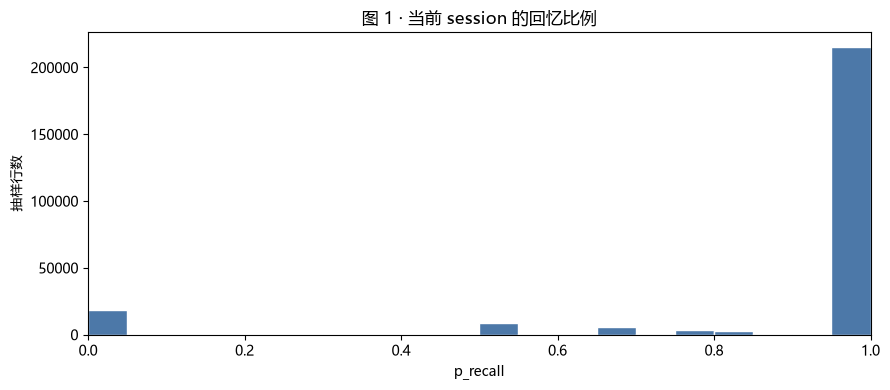

全量 p_recall=0：906,318（7.05%）
全量 p_recall=1：10,782,890（83.89%）
全量中间值：1,164,937（9.06%）


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(eda["p_recall"], bins=np.linspace(0, 1, 21), color="#4C78A8", edgecolor="white")
ax.set(xlabel="p_recall", ylabel="抽样行数", title="图 1 · 当前 session 的回忆比例")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()
print(f"全量 p_recall=0：{full_p_zero:,}（{full_p_zero/full_row_count:.2%}）")
print(f"全量 p_recall=1：{full_p_one:,}（{full_p_one/full_row_count:.2%}）")
print(f"全量中间值：{full_row_count-full_p_zero-full_p_one:,}（{1-(full_p_zero+full_p_one)/full_row_count:.2%}）")

`p_recall` 大量集中在 1；模型评估不能只凭多数类的高正确率判断效果。

## 2.2 复习间隔


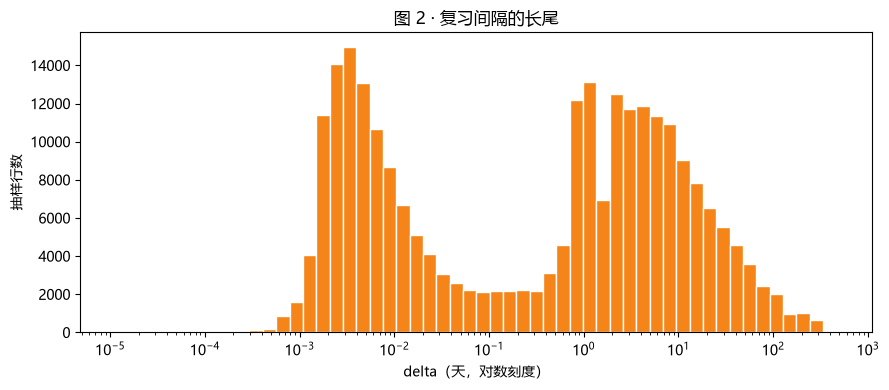

抽样中 delta=0： 0


0.00      0.000012
0.25      0.006088
0.50      0.892743
0.75      5.125822
0.90     19.899676
0.99    131.834011
1.00    464.945625
Name: delta_days, dtype: float64

In [ ]:
positive_days = eda.loc[eda["delta_days"] > 0, "delta_days"]
fig, ax = plt.subplots(figsize=(9, 4))
if len(positive_days):
    log_bins = np.logspace(
        np.log10(positive_days.min()), np.log10(positive_days.max()), 55
    )
    ax.hist(positive_days, bins=log_bins, color="#F58518", edgecolor="white")
    ax.set_xscale("log")
ax.set(xlabel="delta（天，对数刻度）", ylabel="抽样行数", title="图 2 · 复习间隔的长尾")
plt.tight_layout()
plt.show()
print("抽样中 delta=0：", int(eda["delta"].eq(0).sum()))
display(eda["delta_days"].quantile([0, .25, .5, .75, .9, .99, 1]).rename("delta_days"))

复习间隔有长尾；对数横轴便于同时看到短间隔和长间隔。

## 2.3 历史练习次数


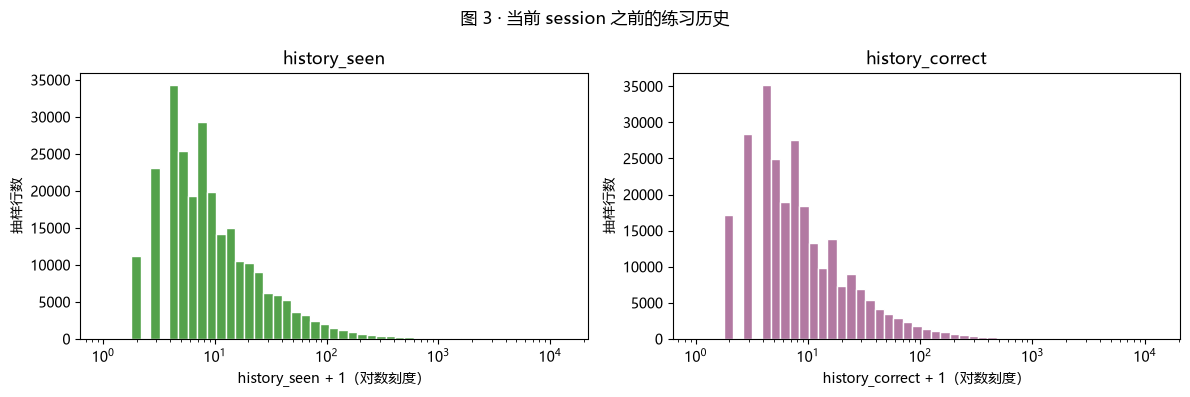

,history_seen,history_correct
0.00,1.0,1.0
0.50,6.0,6.0
0.90,36.0,32.0
0.99,234.0,206.0
1.00,13463.0,12835.0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, field, color in zip(
    axes, ["history_seen", "history_correct"], ["#54A24B", "#B279A2"]
):
    values = eda[field].to_numpy() + 1
    bins = np.logspace(0, np.log10(values.max() + 1), 50)
    ax.hist(values, bins=bins, color=color, edgecolor="white")
    ax.set_xscale("log")
    ax.set(xlabel=f"{field} + 1（对数刻度）", ylabel="抽样行数", title=field)
plt.suptitle("图 3 · 当前 session 之前的练习历史")
plt.tight_layout()
plt.show()
display(eda[["history_seen", "history_correct"]].quantile([0, .5, .9, .99, 1]))

历史计数也有长尾，后续两个 HLR 模型对计数使用平方根变换。

## 2.4 间隔与回忆比例


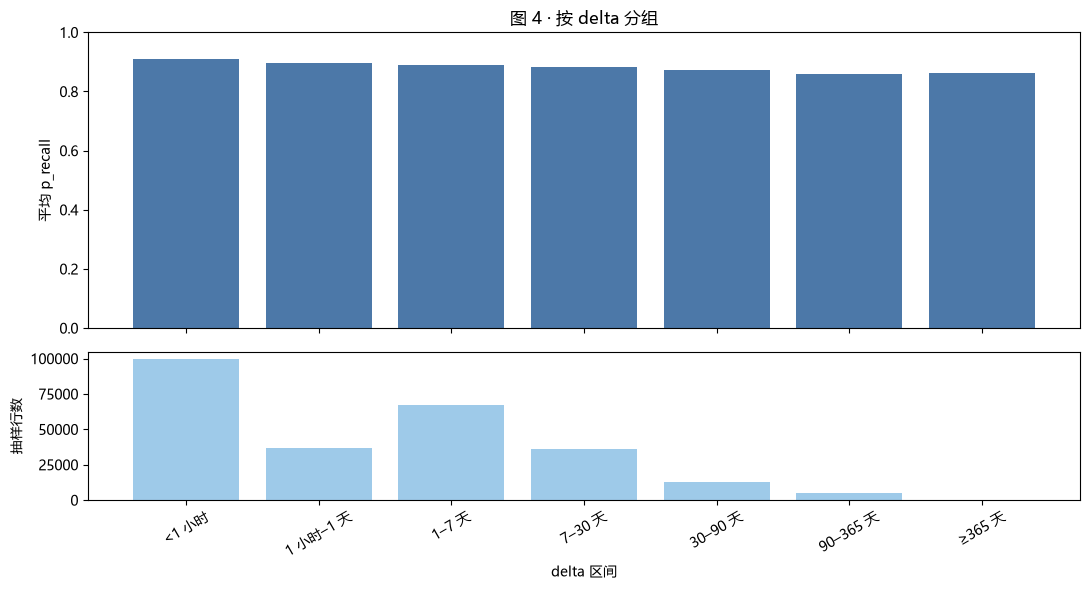

,mean_recall,n
delta_bin,,
<1 小时,0.909624,99494
1 小时–1 天,0.896490,36803
1–7 天,0.888860,67146
7–30 天,0.882713,35953
30–90 天,0.871382,12830
90–365 天,0.858637,4827
≥365 天,0.861111,30


In [ ]:
delta_edges = [-np.inf, 1/24, 1, 7, 30, 90, 365, np.inf]
delta_labels = ["<1 小时", "1 小时–1 天", "1–7 天", "7–30 天",
                "30–90 天", "90–365 天", "≥365 天"]
eda["delta_bin"] = pd.cut(
    eda["delta_days"], bins=delta_edges, labels=delta_labels, right=False
)
delta_summary = eda.groupby("delta_bin", observed=False)["p_recall"].agg(
    mean_recall="mean", n="size"
)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].bar(delta_labels, delta_summary["mean_recall"], color="#4C78A8")
axes[0].set(ylabel="平均 p_recall", ylim=(0, 1), title="图 4 · 按 delta 分组")
axes[1].bar(delta_labels, delta_summary["n"], color="#9ECAE9")
axes[1].set(ylabel="抽样行数", xlabel="delta 区间")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
display(delta_summary)

间隔分组均值是观察性关联，不能直接当成遗忘的因果效应；同时看每组样本数。

## 2.5 历史次数与回忆比例


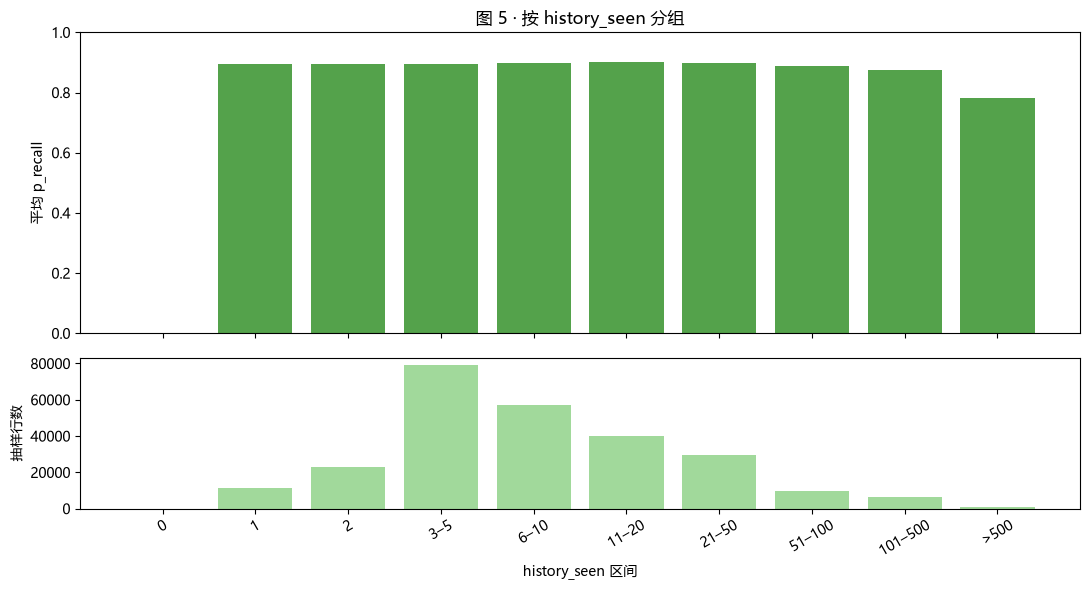

,mean_recall,n
seen_bin,,
0,NaN,0
1,0.895135,11289
2,0.896172,22969
3–5,0.894886,78981
6–10,0.897797,57002
11–20,0.901240,40040
21–50,0.899123,29407
51–100,0.887947,9800
101–500,0.875830,6577


In [ ]:
seen_edges = [-1, 0, 1, 2, 5, 10, 20, 50, 100, 500, np.inf]
seen_labels = ["0", "1", "2", "3–5", "6–10", "11–20",
               "21–50", "51–100", "101–500", ">500"]
eda["seen_bin"] = pd.cut(
    eda["history_seen"], bins=seen_edges, labels=seen_labels
)
seen_summary = eda.groupby("seen_bin", observed=False)["p_recall"].agg(
    mean_recall="mean", n="size"
)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].bar(seen_labels, seen_summary["mean_recall"], color="#54A24B")
axes[0].set(ylabel="平均 p_recall", ylim=(0, 1), title="图 5 · 按 history_seen 分组")
axes[1].bar(seen_labels, seen_summary["n"], color="#A1D99B")
axes[1].set(ylabel="抽样行数", xlabel="history_seen 区间")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
display(seen_summary)

不同历史次数的回忆比例受用户、词项难度等因素影响；同时看每组样本数。

## 2.6 语言组合


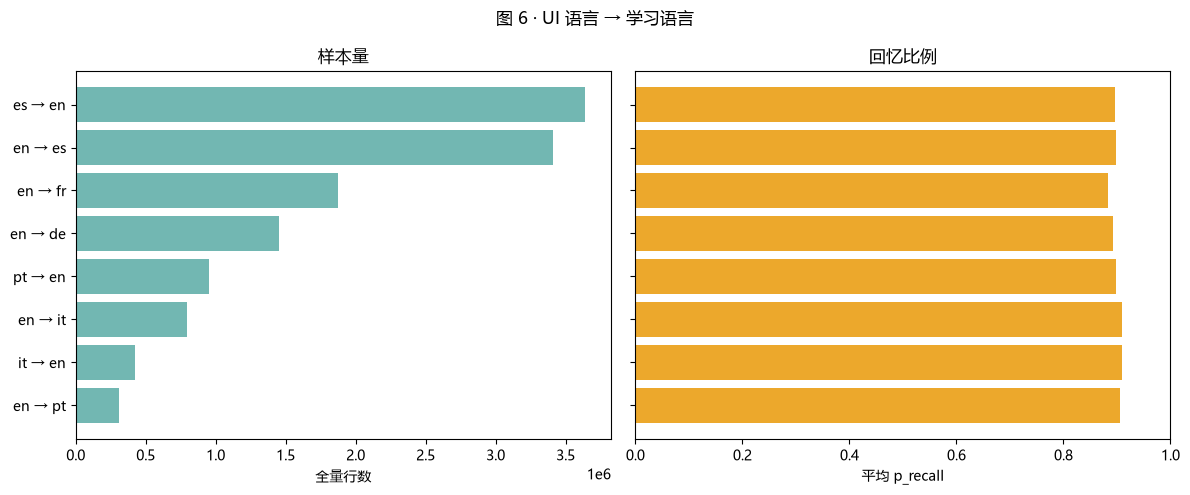

,pair,n,mean_recall
0,en → pt,311480,0.905512
1,it → en,424152,0.909596
2,en → it,793935,0.908592
3,pt → en,949460,0.898728
4,en → de,1452597,0.892786
5,en → fr,1873734,0.882750
6,en → es,3407689,0.898489
7,es → en,3641179,0.896289


In [ ]:
pair_summary = pd.DataFrame([
    {
        "ui_language": ui, "learning_language": learning,
        "n": count, "mean_recall": pair_recall_sums[(ui, learning)] / count,
    }
    for (ui, learning), count in pair_counts.items()
]).sort_values("n", ascending=True).reset_index(drop=True)
pair_summary["pair"] = (
    pair_summary["ui_language"] + " → " + pair_summary["learning_language"]
)
positions = np.arange(len(pair_summary))
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].barh(positions, pair_summary["n"], color="#72B7B2")
axes[0].set(yticks=positions, yticklabels=pair_summary["pair"],
            xlabel="全量行数", title="样本量")
axes[1].barh(positions, pair_summary["mean_recall"], color="#ECA82C")
axes[1].set(xlabel="平均 p_recall", xlim=(0, 1), title="回忆比例")
fig.suptitle("图 6 · UI 语言 → 学习语言")
plt.tight_layout()
plt.show()
display(pair_summary[["pair", "n", "mean_recall"]])

语言组合的样本量差异较大，比较组均值时应一起查看行数。

## 2.7 用户与词项频次


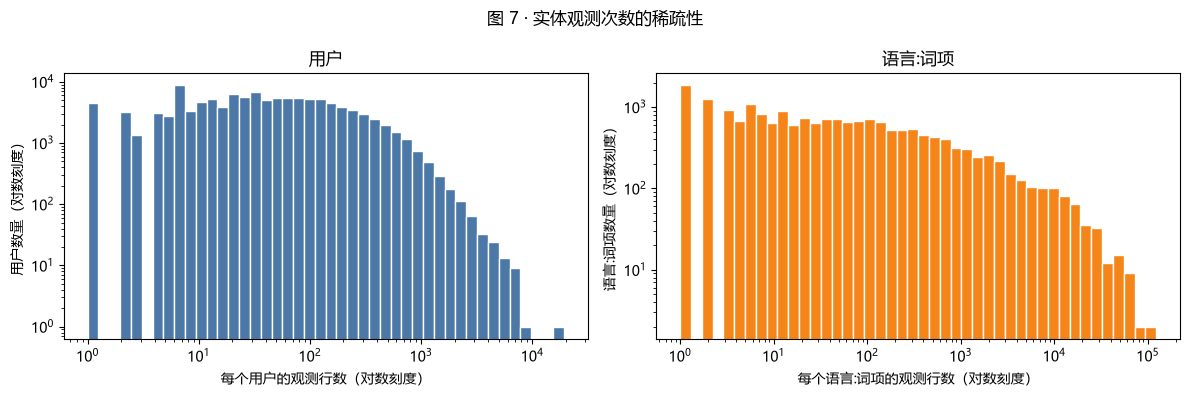

用户：115,222 个；≤5 行：11.43%
语言:词项：19,279 个；≤5 行：27.69%


,user_rows,lexeme_rows
0.00,1.00,1.00
0.50,34.00,26.00
0.90,280.00,963.00
0.99,1065.79,13757.08
1.00,19194.00,123099.00


In [ ]:
user_frequency = np.fromiter(user_counts.values(), dtype=np.int64)
lexeme_frequency = np.fromiter(lexeme_counts.values(), dtype=np.int64)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, color, label in zip(
    axes,
    [user_frequency, lexeme_frequency],
    ["#4C78A8", "#F58518"],
    ["用户", "语言:词项"],
):
    bins = np.logspace(0, np.log10(values.max() + 1), 45)
    ax.hist(values, bins=bins, color=color, edgecolor="white")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set(xlabel=f"每个{label}的观测行数（对数刻度）",
           ylabel=f"{label}数量（对数刻度）", title=label)
plt.suptitle("图 7 · 实体观测次数的稀疏性")
plt.tight_layout()
plt.show()
print(f"用户：{len(user_frequency):,} 个；≤5 行：{np.mean(user_frequency <= 5):.2%}")
print(f"语言:词项：{len(lexeme_frequency):,} 个；≤5 行：{np.mean(lexeme_frequency <= 5):.2%}")
display(pd.DataFrame({
    "user_rows": pd.Series(user_frequency).quantile([0, .5, .9, .99, 1]),
    "lexeme_rows": pd.Series(lexeme_frequency).quantile([0, .5, .9, .99, 1]),
}))

少见用户和词项较多；完整 HLR 对训练集中未见过的词项只使用三个基础特征。

# 3. 数据切分、特征工程与 Baseline

按**原始文件行顺序**固定 Train / Validation / Test = 72% / 18% / 10%。两个模型都只在 Train 上学习参数；Validation 和 Test 不参与拟合。本节直接在 72% 的 Train 上训练后评估三个集合，因此 Test 结果与原 Notebook 用前 90% 重新训练所得的论文对照结果**不是同一训练协议**。

两个模型共用以下定义：

- 基础输入为 `sqrt(1+history_correct)`、`sqrt(1+history_seen-history_correct)`、常数 1；完整 HLR 额外加入 **Train 内出现的** `learning_language:lexeme_string` one-hot。未见词项不增加特征。
- 预测半衰期 `ĥ = clip(2^(θ·x), 15/1440, 274)` 天；预测回忆比例 `p̂ = clip(2^(-delta_days/ĥ), 0.0001, 0.9999)`。
- 目标 `p` 先裁剪到 `[0.0001, 0.9999]`，观察半衰期 `h = clip(-delta_days/log2(p), 15/1440, 274)` 天。`p` 与 `h` 都用于 loss；它们以及 `session_seen/session_correct` 都**不是输入特征**。
- 两模型使用同一个目标函数：`L = Σ[(p−p̂)² + 0.01(h−ĥ)²] + 0.1||θ||²`。按原实现的一轮逐样本更新，初始学习率 `0.001`，特征出现次数衰减，固定 `seed=42`。
- MAE 使用裁剪后的 `p`；AUC 把 `round(p)` 作为二分类标签，**预测越大表示越可能答对**，并列分数取平均秩；半衰期 Spearman 是 `h` 与 `ĥ` 的秩相关。三个集合全部按相同口径计算。


## 3.1 固定切分与共用特征

In [ ]:
import hashlib
import json
import math
import os
import time

# 计数与缓存校验都直接读原始 gzip；不依赖旧目录中的报告、词表或模型文件。
source_sha256 = hashlib.sha256()
with data_path.open("rb") as source:
    for block in iter(lambda: source.read(8 * 1024 * 1024), b""):
        source_sha256.update(block)
source_sha256 = source_sha256.hexdigest()

n_rows = sum(len(chunk) for chunk in pd.read_csv(
    data_path, compression="gzip", usecols=["p_recall"], chunksize=500_000
))
train_end = int(0.72 * n_rows)
test_start = int(0.90 * n_rows)
splits = {
    "Train": (0, train_end),
    "Validation": (train_end, test_start),
    "Test": (test_start, n_rows),
}
display(pd.DataFrame([
    {"split": name, "start": start, "stop_exclusive": stop, "rows": stop - start}
    for name, (start, stop) in splits.items()
]))
print("切分依据：原始 CSV 文件行顺序；随机打乱仅发生在 Train 内的训练阶段。")

MIN_H, MAX_H = 15.0 / 1440.0, 274.0
MIN_P, MAX_P = 0.0001, 0.9999
ALPHA, L2, LEARNING_RATE, SEED, EPOCHS = 0.01, 0.1, 0.001, 42, 1
LOG_MIN_H, LOG_MAX_H = math.log2(MIN_H), math.log2(MAX_H)
BASE_FEATURES = [
    "sqrt(1+history_correct)",
    "sqrt(1+history_seen-history_correct)",
    "bias",
]
RECORD_DTYPE = np.dtype([
    ("x_correct", "<f8"), ("x_wrong", "<f8"), ("lexeme_column", "<i4"),
    ("p_target", "<f8"), ("delta_days", "<f8"), ("h_observed", "<f8"),
])

cache_dir = data_path.parent.parent / "interim"
cache_dir.mkdir(parents=True, exist_ok=True)
cache_path = cache_dir / "takeaway_hlr_features_v1.dat"
manifest_path = cache_dir / "takeaway_hlr_features_v1.json"
cache_identity = {
    "version": 1,
    "source_sha256": source_sha256,
    "n_rows": n_rows,
    "train_end": train_end,
    "dtype": repr(RECORD_DTYPE.descr),
}
manifest = json.loads(manifest_path.read_text(encoding="utf-8")) if manifest_path.is_file() else {}
cache_valid = (
    cache_path.is_file()
    and all(manifest.get(key) == value for key, value in cache_identity.items())
    and cache_path.stat().st_size == n_rows * RECORD_DTYPE.itemsize
)

if not cache_valid:
    vocabulary = {}  # 只能从 Train 学到词项列号；从第 3 列开始。
    unseen_validation = unseen_test = 0
    partial_path = cache_path.with_suffix(".partial")
    records_out = np.memmap(partial_path, dtype=RECORD_DTYPE, mode="w+", shape=(n_rows,))
    written = 0
    needed = [
        "p_recall", "delta", "history_seen", "history_correct",
        "learning_language", "lexeme_string",
    ]
    for chunk in pd.read_csv(data_path, compression="gzip", usecols=needed,
                             chunksize=200_000):
        start, stop = written, written + len(chunk)
        if stop > n_rows:
            raise ValueError("实际行数超过已计数的行数")
        keys = chunk["learning_language"].astype(str).str.cat(
            chunk["lexeme_string"].astype(str), sep=":"
        )
        train_count = max(0, min(stop, train_end) - start)
        for key in pd.unique(keys.iloc[:train_count]):
            vocabulary.setdefault(key, 3 + len(vocabulary))
        columns = keys.map(vocabulary).fillna(-1).to_numpy(dtype=np.int32)

        correct = chunk["history_correct"].to_numpy(dtype=np.float64)
        wrong = chunk["history_seen"].to_numpy(dtype=np.float64) - correct
        if np.any(correct < 0) or np.any(wrong < 0):
            raise ValueError("发现 history_seen < history_correct 或负数")
        p = np.clip(chunk["p_recall"].to_numpy(dtype=np.float64), MIN_P, MAX_P)
        days = chunk["delta"].to_numpy(dtype=np.float64) / 86_400.0
        h = np.clip(-days / np.log2(p), MIN_H, MAX_H)
        if not (np.isfinite(p).all() and np.isfinite(h).all()):
            raise ValueError("目标值包含非有限数")

        records_out["x_correct"][start:stop] = np.sqrt(1.0 + correct)
        records_out["x_wrong"][start:stop] = np.sqrt(1.0 + wrong)
        records_out["lexeme_column"][start:stop] = columns
        records_out["p_target"][start:stop] = p
        records_out["delta_days"][start:stop] = days
        records_out["h_observed"][start:stop] = h

        val_left, val_right = max(start, train_end), min(stop, test_start)
        if val_left < val_right:
            unseen_validation += int(np.sum(columns[val_left-start:val_right-start] < 0))
        test_left = max(start, test_start)
        if test_left < stop:
            unseen_test += int(np.sum(columns[test_left-start:] < 0))
        written = stop

    if written != n_rows:
        raise ValueError(f"缓存行数 {written:,} 与原始文件 {n_rows:,} 不一致")
    records_out.flush()
    del records_out
    os.replace(partial_path, cache_path)
    manifest = {
        **cache_identity,
        "vocab_size": len(vocabulary),
        "unseen_validation": unseen_validation,
        "unseen_test": unseen_test,
    }
    manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2),
                             encoding="utf-8")
    print("已建立新目录所需的特征缓存。")
else:
    print("已复用与当前原始数据、切分一致的特征缓存。")

records = np.memmap(cache_path, dtype=RECORD_DTYPE, mode="r", shape=(n_rows,))
vocab_size = int(manifest["vocab_size"])
print(f"缓存：{cache_path}；{cache_path.stat().st_size / 2**20:.1f} MiB")
print("基础特征：", BASE_FEATURES)
print(f"Train 词项数：{vocab_size:,}；Validation 未见词项行数："
      f"{manifest['unseen_validation']:,}；Test 未见词项行数：{manifest['unseen_test']:,}")

def train_hlr(dimension):
    """沿用原论文风格：一次打乱 Train，逐行、逐活跃特征更新。"""
    weights = [0.0] * dimension
    feature_counts = [0] * dimension
    order = np.arange(train_end, dtype=np.int32)
    np.random.default_rng(SEED).shuffle(order)
    started = time.perf_counter()
    x0_all, x1_all = records["x_correct"], records["x_wrong"]
    lex_all, p_all = records["lexeme_column"], records["p_target"]
    days_all, h_all = records["delta_days"], records["h_observed"]
    for step, row_index in enumerate(order, start=1):
        x0, x1 = float(x0_all[row_index]), float(x1_all[row_index])
        column = int(lex_all[row_index])
        p, days, h_true = float(p_all[row_index]), float(days_all[row_index]), float(h_all[row_index])
        score = weights[0] * x0 + weights[1] * x1 + weights[2]
        if dimension > 3 and 3 <= column < dimension:
            score += weights[column]
        h_pred = math.exp2(min(max(score, LOG_MIN_H), LOG_MAX_H))
        p_pred = min(max(math.exp2(-days / h_pred), MIN_P), MAX_P)
        grad_p = 2.0 * (p_pred - p) * math.log(2.0)**2 * p_pred * (days / h_pred)
        grad_h = 2.0 * (h_pred - h_true) * math.log(2.0) * h_pred
        active = ((0, x0), (1, x1), (2, 1.0))
        if dimension > 3 and 3 <= column < dimension:
            active += ((column, 1.0),)
        for k, value in active:
            rate = LEARNING_RATE / ((1.0 + p) * math.sqrt(1 + feature_counts[k]))
            weights[k] -= rate * grad_p * value
            weights[k] -= rate * ALPHA * grad_h * value
            weights[k] -= rate * L2 * weights[k]
            feature_counts[k] += 1
        if step % 1_000_000 == 0 or step == train_end:
            print(f"  {step:,}/{train_end:,} 行；耗时 {time.perf_counter()-started:.1f} 秒")
    return np.asarray(weights, dtype=np.float64)

def auc_fixed(labels, scores):
    labels = np.asarray(labels, dtype=np.int8)
    n_pos = int(labels.sum())
    n_neg = len(labels) - n_pos
    if not n_pos or not n_neg:
        return np.nan
    ranks = pd.Series(scores).rank(method="average").to_numpy(dtype=np.float64)
    rank_sum = float(ranks[labels == 1].sum())
    return (rank_sum - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def spearman_with_ties(observed, predicted):
    x_rank = pd.Series(observed).rank(method="average").to_numpy(dtype=np.float64)
    y_rank = pd.Series(predicted).rank(method="average").to_numpy(dtype=np.float64)
    if np.std(x_rank) == 0 or np.std(y_rank) == 0:
        return np.nan
    return float(np.corrcoef(x_rank, y_rank)[0, 1])

def evaluate_hlr(weights, split_name, batch_size=200_000):
    start, stop = splits[split_name]
    count = stop - start
    p_true = records["p_target"][start:stop]
    h_true = records["h_observed"][start:stop]
    p_pred = np.empty(count, dtype=np.float64)
    h_pred = np.empty(count, dtype=np.float64)
    for left in range(start, stop, batch_size):
        right = min(left + batch_size, stop)
        batch = records[left:right]
        score = (weights[0] * batch["x_correct"]
                 + weights[1] * batch["x_wrong"] + weights[2])
        if len(weights) > 3:
            columns = batch["lexeme_column"]
            known = (columns >= 3) & (columns < len(weights))
            score[known] += weights[columns[known]]
        h_batch = np.exp2(np.clip(score, LOG_MIN_H, LOG_MAX_H))
        p_batch = np.clip(np.exp2(-batch["delta_days"] / h_batch), MIN_P, MAX_P)
        h_pred[left-start:right-start] = h_batch
        p_pred[left-start:right-start] = p_batch

    p_error = p_pred - p_true
    mae_p = float(np.abs(p_error).mean())
    p_sq = float(np.dot(p_error, p_error))
    del p_error
    h_error = h_pred - h_true
    h_sq = float(np.dot(h_error, h_error))
    del h_error
    loss_sum = p_sq + ALPHA * h_sq + L2 * float(np.dot(weights, weights))
    auc = auc_fixed(np.rint(p_true), p_pred)
    spearman = spearman_with_ties(h_true, h_pred)
    return {
        "split": split_name, "rows": count, "loss_total": loss_sum,
        "loss_per_row": loss_sum / count, "MAE(p)": mae_p,
        "AUC": auc, "Spearman(h)": spearman,
    }

def show_model_result(name, weights):
    print(f"{name}；输入特征维度：{len(weights):,}")
    print("超参数：", {"alpha": ALPHA, "L2": L2, "learning_rate": LEARNING_RATE,
                       "epochs": EPOCHS, "seed": SEED})
    print("Loss = Σ[(p−p̂)² + 0.01(h−ĥ)²] + 0.1||θ||²")
    print("训练已完成；下表分别是完整 Train、Validation 和 Test 的效果：")
    result = pd.DataFrame([evaluate_hlr(weights, name) for name in splits])
    display(result.round({"loss_total": 3, "loss_per_row": 5,
                          "MAE(p)": 6, "AUC": 6, "Spearman(h)": 6}))
    return result


,split,start,stop_exclusive,rows
0,Train,0,9255042,9255042
1,Validation,9255042,11568803,2313761
2,Test,11568803,12854226,1285423


切分依据：原始 CSV 文件行顺序；随机打乱仅发生在 Train 内的训练阶段。
已复用与当前原始数据、切分一致的特征缓存。
缓存：C:\Users\horace\Documents\Projects\Data_analytics\3544-project\data\interim\takeaway_hlr_features_v1.dat；539.4 MiB
基础特征： ['sqrt(1+history_correct)', 'sqrt(1+history_seen-history_correct)', 'bias']
Train 词项数：18,353；Validation 未见词项行数：1,150；Test 未见词项行数：560


切分 cell 只用 Train 建立完整 HLR 的词项词表；两种模型随后共用这份缓存与评估函数。缓存约 539 MiB，重新运行时会核对原始文件指纹与切分。`loss_total` 是该集合的平方误差和加一次 L2 惩罚，`loss_per_row` 便于比较不同大小的集合。

## 3.2 类别特征工程：用户与两列语言

在现有 HLR 缓存之外，按原始 CSV 行顺序建立 `user_id`、`learning_language`、`ui_language` 的类别索引。词表只从 Train 学习；Validation/Test 未见类别记为 `-1`，对应 one-hot 全零。缓存记录三个整数索引，不生成稠密特征矩阵，也不改变原有基础特征缓存。首次运行需完整扫描原始 gzip；之后核对数据指纹和切分后复用。


In [ ]:
import csv
import gzip

CATEGORY_DTYPE = np.dtype([
    ("user_index", "<i4"),
    ("learning_index", "i1"),
    ("ui_index", "i1"),
])
category_path = cache_dir / "takeaway_hlr_categories_v1.dat"
category_manifest_path = cache_dir / "takeaway_hlr_categories_v1.json"
category_identity = {
    "version": 1,
    "source_sha256": source_sha256,
    "n_rows": n_rows,
    "train_end": train_end,
    "dtype": repr(CATEGORY_DTYPE.descr),
}
category_manifest = (
    json.loads(category_manifest_path.read_text(encoding="utf-8"))
    if category_manifest_path.is_file() else {}
)
category_valid = (
    category_path.is_file()
    and category_path.stat().st_size == n_rows * CATEGORY_DTYPE.itemsize
    and all(category_manifest.get(k) == v for k, v in category_identity.items())
    and category_manifest.get("user_count", 0) > 0
    and len(category_manifest.get("learning_values", [])) > 0
    and len(category_manifest.get("ui_values", [])) > 0
)
if not category_valid:
    category_vocab = {
        "user_id": {},
        "learning_language": {},
        "ui_language": {},
    }
    partial_path = category_path.with_suffix(".partial")
    category_out = np.memmap(
        partial_path, dtype=CATEGORY_DTYPE, mode="w+", shape=(n_rows,)
    )
    count = 0
    with gzip.open(data_path, "rt", encoding="utf-8", newline="") as stream:
        reader = csv.reader(stream)
        header = next(reader)
        columns = [header.index(name) for name in category_vocab]
        for row_index, row in enumerate(reader):
            if row_index >= n_rows:
                raise ValueError("Raw file has more rows than the base cache")
            values = [row[column] for column in columns]
            if row_index < train_end:
                encoded = [
                    category_vocab[name].setdefault(value, len(category_vocab[name]))
                    for name, value in zip(category_vocab, values)
                ]
            else:
                encoded = [
                    category_vocab[name].get(value, -1)
                    for name, value in zip(category_vocab, values)
                ]
            if encoded[1] > 127 or encoded[2] > 127:
                raise ValueError("Language category count exceeds int8 range")
            category_out[row_index] = tuple(encoded)
            count += 1
    if count != n_rows:
        raise ValueError(f"Category rows {count:,} != base rows {n_rows:,}")
    category_out.flush()
    del category_out
    os.replace(partial_path, category_path)
    category_manifest = {
        **category_identity,
        "user_count": len(category_vocab["user_id"]),
        "learning_values": list(category_vocab["learning_language"]),
        "ui_values": list(category_vocab["ui_language"]),
    }
    category_manifest_path.write_text(
        json.dumps(category_manifest, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    print("Created Train-only categorical index cache.")
else:
    print("Reused Train-only categorical index cache.")

categorical_records = np.memmap(
    category_path, dtype=CATEGORY_DTYPE, mode="r", shape=(n_rows,)
)
n_users = int(category_manifest["user_count"])
n_learning_languages = len(category_manifest["learning_values"])
n_ui_languages = len(category_manifest["ui_values"])
assert np.all(categorical_records["user_index"][:train_end] >= 0)
assert np.all(categorical_records["learning_index"][:train_end] >= 0)
assert np.all(categorical_records["ui_index"][:train_end] >= 0)
assert n_users == 92_392 and n_learning_languages == 6 and n_ui_languages == 4
print(
    f"Train categories: {n_users:,} users, {n_learning_languages} learning "
    f"languages, {n_ui_languages} UI languages."
)
print(
    f"Validation unseen users: "
    f"{np.count_nonzero(categorical_records['user_index'][train_end:test_start] < 0):,}"
)


Created Train-only categorical index cache.
Train categories: 92,392 users, 6 learning languages, 4 UI languages.
Validation unseen users: 590,955


## 3.3 Baseline 1：完整 HLR

In [ ]:
hlr_weights = train_hlr(dimension=3 + vocab_size)
hlr_results = show_model_result("Baseline 1 · HLR", hlr_weights)


  1,000,000/9,255,042 行；耗时 39.4 秒
  2,000,000/9,255,042 行；耗时 45.5 秒
  3,000,000/9,255,042 行；耗时 51.7 秒
  4,000,000/9,255,042 行；耗时 58.1 秒
  5,000,000/9,255,042 行；耗时 64.1 秒
  6,000,000/9,255,042 行；耗时 70.2 秒
  7,000,000/9,255,042 行；耗时 76.3 秒
  8,000,000/9,255,042 行；耗时 82.3 秒
  9,000,000/9,255,042 行；耗时 88.4 秒
  9,255,042/9,255,042 行；耗时 89.9 秒
Baseline 1 · HLR；输入特征维度：18,356
超参数： {'alpha': 0.01, 'L2': 0.1, 'learning_rate': 0.001, 'epochs': 1, 'seed': 42}
Loss = Σ[(p−p̂)² + 0.01(h−ĥ)²] + 0.1||θ||²
训练已完成；下表分别是完整 Train、Validation 和 Test 的效果：


,split,rows,loss_total,loss_per_row,MAE(p),AUC,Spearman(h)
0,Train,9255042,1.375090e+09,148.57738,0.123859,0.537428,0.200816
1,Validation,2313761,3.435182e+08,148.46746,0.126227,0.535283,0.195566
2,Test,1285423,1.909562e+08,148.55515,0.128375,0.537865,0.198478


完整 HLR 的输入维度为 `3 + Train 中的语言:词项数`。Validation 和 Test 中未见过的词项没有独立权重，只使用三个基础特征。

## 3.4 Baseline 2：HLR -lex

In [ ]:
hlr_lexless_weights = train_hlr(dimension=3)
hlr_lexless_results = show_model_result("Baseline 2 · HLR -lex", hlr_lexless_weights)


  1,000,000/9,255,042 行；耗时 6.1 秒
  2,000,000/9,255,042 行；耗时 11.8 秒
  3,000,000/9,255,042 行；耗时 17.5 秒
  4,000,000/9,255,042 行；耗时 23.3 秒
  5,000,000/9,255,042 行；耗时 28.9 秒
  6,000,000/9,255,042 行；耗时 34.5 秒
  7,000,000/9,255,042 行；耗时 40.3 秒
  8,000,000/9,255,042 行；耗时 46.1 秒
  9,000,000/9,255,042 行；耗时 51.7 秒
  9,255,042/9,255,042 行；耗时 53.2 秒
Baseline 2 · HLR -lex；输入特征维度：3
超参数： {'alpha': 0.01, 'L2': 0.1, 'learning_rate': 0.001, 'epochs': 1, 'seed': 42}
Loss = Σ[(p−p̂)² + 0.01(h−ĥ)²] + 0.1||θ||²
训练已完成；下表分别是完整 Train、Validation 和 Test 的效果：


,split,rows,loss_total,loss_per_row,MAE(p),AUC,Spearman(h)
0,Train,9255042,1.410288e+09,152.38053,0.124180,0.536955,0.158803
1,Validation,2313761,3.515967e+08,151.95893,0.126565,0.535559,0.162231
2,Test,1285423,1.955988e+08,152.16686,0.128654,0.537520,0.160564


HLR -lex 只有三个输入维度；它与完整 HLR 使用同一批行、同一 loss、同一训练超参数和相同的评估口径，因此表中的指标可以直接比较。

## 3.5 Baseline 3：Train mean 常数预测

只使用 Train 的裁剪后 `p_target` 均值作为所有记录的预测概率。均值最小化 Train 的 MSE；此基线不预测半衰期。这里报告 Train 和 Validation，Test 统一在第 8 节展示。


In [40]:
mean_constant_p = float(np.mean(records["p_target"][:train_end]))
assert MIN_P <= mean_constant_p <= MAX_P

def mean_constant_split_row(split_name):
    start, stop = splits[split_name]
    p_true = records["p_target"][start:stop]
    error = mean_constant_p - p_true
    sse = float(np.dot(error, error))
    centered = p_true - float(np.mean(p_true))
    sst = float(np.dot(centered, centered))
    return {
        "model": "Train mean",
        "split": split_name,
        "n_rows": stop - start,
        "MAE(p)": float(np.abs(error).mean()),
        "RMSE(p)": float(np.sqrt(sse / (stop - start))),
        "R²": 1.0 - sse / sst if sst > 0 else np.nan,
    }

mean_constant_baseline = pd.DataFrame([
    mean_constant_split_row("Train"),
    mean_constant_split_row("Validation"),
])
print(f"Train p_target mean = {mean_constant_p:.6f}; constant input X has 0 features.")
print("Selection loss: MSE(p); the prediction is the Train mean.")
display(mean_constant_baseline.round(6))


Train p_target mean = 0.896182; constant input X has 0 features.
Selection loss: MSE(p); the prediction is the Train mean.


,model,split,n_rows,MAE(p),RMSE(p),R²
0,Train mean,Train,9254984,0.174141,0.271249,0.000000
1,Train mean,Validation,2313746,0.174389,0.271857,-0.000002


# 4. HLR 类别特征扩展

三个模型都保留完整 HLR 的历史特征、常数项和 lexeme 权重，并分别增加用户、两列语言或两者的 one-hot 权重。各模型从零开始，在全部 Train 上用第 3 节相同的随机种子、单轮 SGD、损失和裁剪规则训练；各训练单元统一报告输入形状、超参数、Loss、资源及 Train/Validation 指标。Test 留到第 8 节统一评估。以下单元只训练三个新模型，不调用已有八个模型的拟合代码。


In [ ]:
def hlr_extended_layout(use_user, use_languages):
    offset = 3 + vocab_size
    layout = {
        "lex_end": offset,
        "user_start": None,
        "learning_start": None,
        "ui_start": None,
    }
    if use_user:
        layout["user_start"] = offset
        offset += n_users
    if use_languages:
        layout["learning_start"] = offset
        offset += n_learning_languages
        layout["ui_start"] = offset
        offset += n_ui_languages
    layout["dimension"] = offset
    return layout


def train_hlr_extended(name, layout):
    weights = [0.0] * layout["dimension"]
    feature_counts = [0] * layout["dimension"]
    order = np.arange(train_end, dtype=np.int32)
    np.random.default_rng(SEED).shuffle(order)
    x0_all, x1_all = records["x_correct"], records["x_wrong"]
    lex_all, p_all = records["lexeme_column"], records["p_target"]
    days_all, h_all = records["delta_days"], records["h_observed"]
    user_all = categorical_records["user_index"]
    learning_all = categorical_records["learning_index"]
    ui_all = categorical_records["ui_index"]
    started = time.perf_counter()
    for step, row_index in enumerate(order, start=1):
        x0, x1 = float(x0_all[row_index]), float(x1_all[row_index])
        lex_col = int(lex_all[row_index])
        p = float(p_all[row_index])
        days = float(days_all[row_index])
        h_true = float(h_all[row_index])
        score = weights[0] * x0 + weights[1] * x1 + weights[2]
        active = ((0, x0), (1, x1), (2, 1.0))
        if 3 <= lex_col < layout["lex_end"]:
            score += weights[lex_col]
            active += ((lex_col, 1.0),)
        if layout["user_start"] is not None:
            user_index = int(user_all[row_index])
            if user_index >= 0:
                column = layout["user_start"] + user_index
                score += weights[column]
                active += ((column, 1.0),)
        if layout["learning_start"] is not None:
            learning_index = int(learning_all[row_index])
            ui_index = int(ui_all[row_index])
            if learning_index >= 0:
                column = layout["learning_start"] + learning_index
                score += weights[column]
                active += ((column, 1.0),)
            if ui_index >= 0:
                column = layout["ui_start"] + ui_index
                score += weights[column]
                active += ((column, 1.0),)
        h_pred = math.exp2(min(max(score, LOG_MIN_H), LOG_MAX_H))
        p_pred = min(max(math.exp2(-days / h_pred), MIN_P), MAX_P)
        grad_p = (
            2.0 * (p_pred - p) * math.log(2.0)**2
            * p_pred * (days / h_pred)
        )
        grad_h = 2.0 * (h_pred - h_true) * math.log(2.0) * h_pred
        for column, value in active:
            rate = LEARNING_RATE / (
                (1.0 + p) * math.sqrt(1 + feature_counts[column])
            )
            weights[column] -= rate * grad_p * value
            weights[column] -= rate * ALPHA * grad_h * value
            weights[column] -= rate * L2 * weights[column]
            feature_counts[column] += 1
        if step % 1_000_000 == 0 or step == train_end:
            print(
                f"{name}: {step:,}/{train_end:,} Train rows; "
                f"elapsed={time.perf_counter() - started:.1f}s",
                flush=True,
            )
    return np.asarray(weights, dtype=np.float64), time.perf_counter() - started


def predict_hlr_extended_batch(weights, layout, batch, categories):
    assert len(batch) == len(categories)
    score = (
        weights[0] * batch["x_correct"]
        + weights[1] * batch["x_wrong"] + weights[2]
    )
    lexeme = batch["lexeme_column"]
    known_lexeme = (lexeme >= 3) & (lexeme < layout["lex_end"])
    score[known_lexeme] += weights[lexeme[known_lexeme]]
    if layout["user_start"] is not None:
        user_index = categories["user_index"]
        known_user = user_index >= 0
        score[known_user] += weights[
            layout["user_start"] + user_index[known_user]
        ]
    if layout["learning_start"] is not None:
        for field, start in (
            ("learning_index", layout["learning_start"]),
            ("ui_index", layout["ui_start"]),
        ):
            index = categories[field]
            known = index >= 0
            score[known] += weights[start + index[known].astype(np.int32)]
    h_pred = np.exp2(np.clip(score, LOG_MIN_H, LOG_MAX_H))
    p_pred = np.clip(
        np.exp2(-batch["delta_days"] / h_pred), MIN_P, MAX_P
    )
    return p_pred, h_pred


def evaluate_hlr_extended_validation(name, weights, layout):
    start, stop = splits["Validation"]
    count = stop - start
    p_true = records["p_target"][start:stop]
    h_true = records["h_observed"][start:stop]
    days = records["delta_days"][start:stop]
    p_pred = np.empty(count, dtype=np.float64)
    h_pred = np.empty(count, dtype=np.float64)
    for left in range(start, stop, 200_000):
        right = min(left + 200_000, stop)
        p_batch, h_batch = predict_hlr_extended_batch(
            weights, layout, records[left:right], categorical_records[left:right]
        )
        p_pred[left-start:right-start] = p_batch
        h_pred[left-start:right-start] = h_batch
    error = p_pred - p_true
    sse = float(np.dot(error, error))
    centered = p_true - float(np.mean(p_true))
    sst = float(np.dot(centered, centered))
    interior = (
        (h_true > MIN_H) & (h_true < MAX_H) & (days > 0)
    )
    n_interior = int(interior.sum())
    row = {
        "model": name,
        "split": "Validation",
        "n_train": train_end,
        "n_eval": count,
        "MAE(p)": float(np.abs(error).mean()),
        "RMSE": float(np.sqrt(sse / count)),
        "R²": 1.0 - sse / sst if sst > 0 else np.nan,
        "AUC": auc_fixed(np.rint(p_true), p_pred),
        "Spearman(h)": spearman_with_ties(h_true, h_pred),
        "n_spearman_h": count,
        "n_h_interior": n_interior,
        "h_interior_share": n_interior / count,
        "Spearman(h)_interior": (
            spearman_with_ties(h_true[interior], h_pred[interior])
            if n_interior > 1 else np.nan
        ),
    }
    abs_error = np.abs(error)
    language_index = categorical_records["learning_index"][start:stop]
    language_rows = []
    for index, language in enumerate(category_manifest["learning_values"]):
        mask = language_index == index
        count_in_group = int(mask.sum())
        language_rows.append({
            "learning_language": language,
            "rows": count_in_group,
            "MAE(p)": (
                float(abs_error[mask].mean()) if count_in_group else np.nan
            ),
        })
    unknown_language = language_index < 0
    if unknown_language.any():
        language_rows.append({
            "learning_language": "unseen",
            "rows": int(unknown_language.sum()),
            "MAE(p)": float(abs_error[unknown_language].mean()),
        })
    by_language = pd.DataFrame(language_rows)
    assert int(by_language["rows"].sum()) == count
    user_index = categorical_records["user_index"][start:stop]
    by_user = pd.DataFrame([
        {
            "user_status": status,
            "rows": int(np.count_nonzero(mask)),
            "MAE(p)": float(abs_error[mask].mean()) if mask.any() else np.nan,
        }
        for status, mask in (
            ("known", user_index >= 0),
            ("unseen", user_index < 0),
        )
    ])
    return pd.DataFrame([row]), by_language, by_user


def run_hlr_extended(name, use_user, use_languages):
    layout = hlr_extended_layout(use_user, use_languages)
    weights, fit_seconds = train_hlr_extended(name, layout)
    validation, by_language, by_user = evaluate_hlr_extended_validation(
        name, weights, layout
    )
    resources = pd.DataFrame([{
        "model": name,
        "n_train": train_end,
        "dimension": layout["dimension"],
        "fit_seconds": fit_seconds,
        "user_features": n_users if use_user else 0,
        "language_features": (
            n_learning_languages + n_ui_languages if use_languages else 0
        ),
    }])
    def predict_and_loss(batch, left, right):
        p_pred, h_pred = predict_hlr_extended_batch(
            weights, layout, batch, categorical_records[left:right]
        )
        p_error = p_pred - batch["p_target"]
        h_error = h_pred - batch["h_observed"]
        loss_sum = float(
            np.dot(p_error, p_error) + ALPHA * np.dot(h_error, h_error)
        )
        return p_pred, loss_sum

    report_model_fit(
        name, layout["dimension"], "sparse HLR base + lexeme + selected category one-hot",
        "p_target and h_observed",
        {"alpha": ALPHA, "L2": L2, "learning_rate": LEARNING_RATE,
         "epochs": EPOCHS, "seed": SEED},
        "sum[(p-p_hat)^2 + alpha*(h-h_hat)^2] + L2*||weights||^2; shown per row",
        resources, predict_and_loss,
        regularization_per_row=lambda n: L2 * float(np.dot(weights, weights)) / n,
    )
    return weights, layout, resources, validation, by_language, by_user


def report_model_fit(name, input_dim, input_description, target_description,
                     hyperparameters, loss_description, resource,
                     predict_and_loss_batch, regularization_per_row=None):
    """Report the same Train/Validation fields without touching Test."""
    print(f"Model: {name}")
    print(f"Input X shape: Train ({train_end}, {input_dim}); "
          f"Validation ({splits['Validation'][1]-splits['Validation'][0]}, {input_dim})")
    print(f"Input representation: {input_description}")
    print(f"Target: {target_description}")
    print(f"Hyperparameters: {hyperparameters}")
    print(f"Loss: {loss_description}")
    rows = []
    for split_name in ("Train", "Validation"):
        start, stop = splits[split_name]
        n = stop - start
        abs_sum = sq_sum = target_sum = target_sq_sum = loss_sum = 0.0
        for left in range(start, stop, 200_000):
            right = min(left + 200_000, stop)
            batch = records[left:right]
            p_pred, batch_loss = predict_and_loss_batch(batch, left, right)
            p_true = batch["p_target"]
            error = p_pred - p_true
            abs_sum += float(np.abs(error).sum())
            sq_sum += float(np.dot(error, error))
            target_sum += float(p_true.sum())
            target_sq_sum += float(np.dot(p_true, p_true))
            loss_sum += float(batch_loss)
        sst = target_sq_sum - target_sum ** 2 / n
        penalty = (
            float(regularization_per_row(n))
            if regularization_per_row is not None else 0.0
        )
        rows.append({
            "model": name, "split": split_name, "n_rows": n,
            "Loss/row": loss_sum / n + penalty,
            "MAE(p)": abs_sum / n,
            "RMSE(p)": math.sqrt(sq_sum / n),
            "R²": 1.0 - sq_sum / sst if sst > 0 else np.nan,
        })
    report = pd.DataFrame(rows)
    print("Fit resources:")
    display(resource.round(3))
    print("Train and Validation (Test is reported in Section 8):")
    display(report.round(6))
    return report


## 4.1 HLR-User

在完整 HLR 后加入 Train 用户 one-hot；Validation/Test 中未见用户不激活用户权重。原始数据下的参考值，去重后需重新计算；来源 notebook 的 Validation MAE(p) 约为 `0.125200`，可作为移植后的核对值。


In [ ]:
hlr_user_weights, hlr_user_layout, hlr_user_resource, hlr_user_validation, hlr_user_by_language, hlr_user_by_user = run_hlr_extended(
    "HLR-User", use_user=True, use_languages=False
)


HLR-User: 1,000,000/9,255,042 Train rows; elapsed=25.3s
HLR-User: 2,000,000/9,255,042 Train rows; elapsed=33.2s
HLR-User: 3,000,000/9,255,042 Train rows; elapsed=41.4s
HLR-User: 4,000,000/9,255,042 Train rows; elapsed=49.5s
HLR-User: 5,000,000/9,255,042 Train rows; elapsed=58.1s
HLR-User: 6,000,000/9,255,042 Train rows; elapsed=67.6s
HLR-User: 7,000,000/9,255,042 Train rows; elapsed=76.1s
HLR-User: 8,000,000/9,255,042 Train rows; elapsed=84.0s
HLR-User: 9,000,000/9,255,042 Train rows; elapsed=91.4s
HLR-User: 9,255,042/9,255,042 Train rows; elapsed=93.4s


,model,n_train,dimension,fit_seconds,user_features,language_features
0,HLR-User,9255042,110748,93.404,92392,0


,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
0,HLR-User,Validation,9255042,2313761,0.1252,0.29024,-0.139805,0.538544,0.248209,2313761,1025828,0.44336,0.03726


,learning_language,rows,MAE(p)
0,de,273394,0.131182
1,es,632672,0.125005
2,pt,59489,0.109935
3,en,855403,0.124359
4,fr,347538,0.136270
5,it,145265,0.099516


,user_status,rows,MAE(p)
0,known,1722806,0.120463
1,unseen,590955,0.139011


## 4.2 HLR-Lang

在完整 HLR 后分别加入 `learning_language` 的 6 个位置和 `ui_language` 的 4 个位置。每行各激活一个已知语言位置；未见类别全零。原始数据下的参考值，去重后需重新计算；来源 notebook 的 Validation MAE(p) 约为 `0.126131`。


In [ ]:
hlr_lang_weights, hlr_lang_layout, hlr_lang_resource, hlr_lang_validation, hlr_lang_by_language, hlr_lang_by_user = run_hlr_extended(
    "HLR-Lang", use_user=False, use_languages=True
)


HLR-Lang: 1,000,000/9,255,042 Train rows; elapsed=8.7s
HLR-Lang: 2,000,000/9,255,042 Train rows; elapsed=17.2s
HLR-Lang: 3,000,000/9,255,042 Train rows; elapsed=26.3s
HLR-Lang: 4,000,000/9,255,042 Train rows; elapsed=35.2s
HLR-Lang: 5,000,000/9,255,042 Train rows; elapsed=44.1s
HLR-Lang: 6,000,000/9,255,042 Train rows; elapsed=55.7s
HLR-Lang: 7,000,000/9,255,042 Train rows; elapsed=65.6s
HLR-Lang: 8,000,000/9,255,042 Train rows; elapsed=74.5s
HLR-Lang: 9,000,000/9,255,042 Train rows; elapsed=84.1s
HLR-Lang: 9,255,042/9,255,042 Train rows; elapsed=86.4s


,model,n_train,dimension,fit_seconds,user_features,language_features
0,HLR-Lang,9255042,18366,86.392,0,10


,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
0,HLR-Lang,Validation,9255042,2313761,0.126131,0.290788,-0.144119,0.535532,0.196651,2313761,1025828,0.44336,0.04672


,learning_language,rows,MAE(p)
0,de,273394,0.132058
1,es,632672,0.125743
2,pt,59489,0.110231
3,en,855403,0.125580
4,fr,347538,0.137066
5,it,145265,0.100254


,user_status,rows,MAE(p)
0,known,1722806,0.121760
1,unseen,590955,0.138873


## 4.3 HLR-User+Lang

完整 HLR 同时加入用户与两列语言 one-hot。模型独立从零训练，不从前两个扩展模型继续训练。原始数据下的参考值，去重后需重新计算；来源 notebook 的 Validation MAE(p) 约为 `0.124987`。


In [ ]:
hlr_both_weights, hlr_both_layout, hlr_both_resource, hlr_both_validation, hlr_both_by_language, hlr_both_by_user = run_hlr_extended(
    "HLR-User+Lang", use_user=True, use_languages=True
)


HLR-User+Lang: 1,000,000/9,255,042 Train rows; elapsed=10.4s
HLR-User+Lang: 2,000,000/9,255,042 Train rows; elapsed=20.8s
HLR-User+Lang: 3,000,000/9,255,042 Train rows; elapsed=31.0s
HLR-User+Lang: 4,000,000/9,255,042 Train rows; elapsed=40.6s
HLR-User+Lang: 5,000,000/9,255,042 Train rows; elapsed=50.8s
HLR-User+Lang: 6,000,000/9,255,042 Train rows; elapsed=61.3s
HLR-User+Lang: 7,000,000/9,255,042 Train rows; elapsed=71.7s
HLR-User+Lang: 8,000,000/9,255,042 Train rows; elapsed=81.7s
HLR-User+Lang: 9,000,000/9,255,042 Train rows; elapsed=91.7s
HLR-User+Lang: 9,255,042/9,255,042 Train rows; elapsed=94.3s


,model,n_train,dimension,fit_seconds,user_features,language_features
0,HLR-User+Lang,9255042,110758,94.304,92392,10


,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
0,HLR-User+Lang,Validation,9255042,2313761,0.124987,0.290142,-0.139035,0.537602,0.245052,2313761,1025828,0.44336,0.034184


,learning_language,rows,MAE(p)
0,de,273394,0.130902
1,es,632672,0.124583
2,pt,59489,0.109670
3,en,855403,0.124347
4,fr,347538,0.135915
5,it,145265,0.099514


,user_status,rows,MAE(p)
0,known,1722806,0.120357
1,unseen,590955,0.138486


# 5. 随机森林实验

## 5.1 E1：RF-logh 的超参数选择与全量训练

使用 HLR -lex 的三个 `x` 特征预测 `log2(h_observed)`。六组候选仍在固定的 20 万条 Train 样本上训练，并在完整 Validation 上按 `MAE(p)` 选参；选出的配置在全部 Train 上重新训练。Test 统一在第 8 节评估。

In [ ]:
from itertools import product
from sklearn.ensemble import RandomForestRegressor

RF_TUNE_N, RF_FINAL_N, RF_BATCH = 200_000, train_end, 200_000
# Keep the original 200k tuning rows fixed; final fits use the full Train split.
rf_tune_pool = np.sort(
    np.random.default_rng(SEED).choice(train_end, 1_000_000, replace=False)
)
rf_tune_indices = np.sort(
    np.random.default_rng(SEED + 1).choice(rf_tune_pool, RF_TUNE_N, replace=False)
)
del rf_tune_pool
assert len(rf_tune_indices) == RF_TUNE_N and rf_tune_indices[-1] < train_end
assert RF_FINAL_N == splits['Train'][1]

def rf_x_from_records(batch):
    x = np.empty((len(batch), 3), dtype=np.float32)
    x[:, 0] = batch['x_correct']
    x[:, 1] = batch['x_wrong']
    x[:, 2] = 1.0
    return x

def rf_logh_predictions(model, batch):
    score = model.predict(rf_x_from_records(batch))
    h_pred = np.exp2(np.clip(score, LOG_MIN_H, LOG_MAX_H))
    p_pred = np.clip(np.exp2(-batch["delta_days"] / h_pred), MIN_P, MAX_P)
    return p_pred, h_pred

rf_tune_records = records[rf_tune_indices]
rf_tune_x = rf_x_from_records(rf_tune_records)
rf_tune_y = np.log2(rf_tune_records["h_observed"])
val_start, val_stop = splits["Validation"]
rf_candidate_rows = []
for depth, leaf in product((8, 12, 16), (50, 100)):
    candidate = RandomForestRegressor(
        criterion="squared_error", n_estimators=100, max_depth=depth,
        min_samples_leaf=leaf, max_features=1.0, n_jobs=-1, random_state=SEED,
    )
    fit_started = time.perf_counter()
    candidate.fit(rf_tune_x, rf_tune_y)
    fit_seconds = time.perf_counter() - fit_started
    predict_started = time.perf_counter()
    absolute_error_sum = 0.0
    for left in range(val_start, val_stop, RF_BATCH):
        right = min(left + RF_BATCH, val_stop)
        p_pred, _ = rf_logh_predictions(candidate, records[left:right])
        absolute_error_sum += float(np.abs(
            p_pred - records["p_target"][left:right]
        ).sum())
    predict_seconds = time.perf_counter() - predict_started
    rf_candidate_rows.append({
        "max_depth": depth,
        "min_samples_leaf": leaf,
        "n_train": RF_TUNE_N,
        "n_validation": val_stop - val_start,
        "fit_seconds": fit_seconds,
        "predict_seconds": predict_seconds,
        "MAE(p)": absolute_error_sum / (val_stop - val_start),
    })
    del candidate

rf_candidate_results = pd.DataFrame(rf_candidate_rows).sort_values(
    ["MAE(p)", "max_depth", "min_samples_leaf"],
    ascending=[True, True, False],
).reset_index(drop=True)
rf_selected_depth = int(rf_candidate_results.loc[0, "max_depth"])
rf_selected_leaf = int(rf_candidate_results.loc[0, "min_samples_leaf"])
display(rf_candidate_results.round({"fit_seconds": 2, "predict_seconds": 2, "MAE(p)": 6}))


,max_depth,min_samples_leaf,n_train,n_validation,fit_seconds,predict_seconds,MAE(p)
0,8,50,200000,2313761,1.63,2.69,0.160132
1,8,100,200000,2313761,1.68,3.03,0.160181
2,12,50,200000,2313761,1.50,3.22,0.160206
3,12,100,200000,2313761,1.56,3.16,0.160237
4,16,50,200000,2313761,1.63,3.46,0.160243
5,16,100,200000,2313761,1.57,3.32,0.160251


候选表按完整 Validation 的 `MAE(p)` 升序排列，首行配置用于全量训练。表中的训练耗时只对应 20 万条候选样本。

In [ ]:
import threading
import psutil

rf_process = psutil.Process()
rf_rss_before = rf_process.memory_info().rss
rf_peak_rss = [rf_rss_before]
rf_monitor_stop = threading.Event()

def rf_watch_rss():
    while not rf_monitor_stop.wait(0.1):
        rf_peak_rss[0] = max(rf_peak_rss[0], rf_process.memory_info().rss)

rf_monitor = threading.Thread(target=rf_watch_rss, daemon=True)
rf_monitor.start()
try:
    rf_final_records = records[:train_end]
    rf_final_x = rf_x_from_records(rf_final_records)
    rf_final_y = np.log2(rf_final_records["h_observed"])
    rf_e1_model = RandomForestRegressor(
        criterion="squared_error", n_estimators=100,
        max_depth=rf_selected_depth, min_samples_leaf=rf_selected_leaf,
        max_features=1.0, n_jobs=-1, random_state=SEED,
    )
    fit_started = time.perf_counter()
    rf_e1_model.fit(rf_final_x, rf_final_y)
    rf_final_fit_seconds = time.perf_counter() - fit_started
    del rf_final_records, rf_final_x, rf_final_y, rf_tune_records, rf_tune_x, rf_tune_y

    n_val = val_stop - val_start
    p_true = records["p_target"][val_start:val_stop]
    h_true = records["h_observed"][val_start:val_stop]
    days = records["delta_days"][val_start:val_stop]
    rf_e1_p_pred = np.empty(n_val, dtype=np.float64)
    rf_e1_h_pred = np.empty(n_val, dtype=np.float64)
    predict_started = time.perf_counter()
    for left in range(val_start, val_stop, RF_BATCH):
        right = min(left + RF_BATCH, val_stop)
        batch = records[left:right]
        offset_left, offset_right = left - val_start, right - val_start
        p_batch, h_batch = rf_logh_predictions(rf_e1_model, batch)
        rf_e1_p_pred[offset_left:offset_right] = p_batch
        rf_e1_h_pred[offset_left:offset_right] = h_batch
    rf_final_predict_seconds = time.perf_counter() - predict_started
finally:
    rf_monitor_stop.set()
    rf_monitor.join()
    rf_peak_rss[0] = max(rf_peak_rss[0], rf_process.memory_info().rss)

assert np.isfinite(rf_e1_p_pred).all() and np.isfinite(rf_e1_h_pred).all()
assert np.all((MIN_P <= rf_e1_p_pred) & (rf_e1_p_pred <= MAX_P))
assert np.all((MIN_H <= rf_e1_h_pred) & (rf_e1_h_pred <= MAX_H))

interior = (h_true > MIN_H) & (h_true < MAX_H) & (days > 0)
n_interior = int(interior.sum())

def rf_e1_metric_row(name, n_train, p_pred, h_pred):
    error = p_pred - p_true
    return {
        "model": name, "n_train": n_train, "n_validation": n_val,
        "MAE(p)": float(np.abs(error).mean()),
        "RMSE(p)": float(np.sqrt(np.mean(error ** 2))),
        "AUC": auc_fixed(np.rint(p_true), p_pred),
        "Spearman(h)": spearman_with_ties(h_true, h_pred),
        "n_spearman_h": n_val,
        "n_h_interior": n_interior,
        "h_interior_share": n_interior / n_val,
        "Spearman(h)_interior": spearman_with_ties(
            h_true[interior], h_pred[interior]
        ),
        "p_hat_at_bounds": float(np.mean((p_pred == MIN_P) | (p_pred == MAX_P))),
        "h_hat_at_bounds": float(np.mean((h_pred == MIN_H) | (h_pred == MAX_H))),
    }

rf_e1_validation = pd.DataFrame([
    rf_e1_metric_row("RF-logh (E1)", RF_FINAL_N, rf_e1_p_pred, rf_e1_h_pred),
])
rf_e1_resource = pd.DataFrame([{
    "n_train": RF_FINAL_N, "max_depth": rf_selected_depth,
    "min_samples_leaf": rf_selected_leaf,
    "fit_seconds": rf_final_fit_seconds,
    "predict_seconds": rf_final_predict_seconds,
    "rss_before_GiB": rf_rss_before / 2**30,
    "peak_rss_GiB": rf_peak_rss[0] / 2**30,
}])


def rf_e1_report_batch(batch, left, right):
    raw_logh = rf_e1_model.predict(rf_x_from_records(batch))
    h_pred = np.exp2(np.clip(raw_logh, LOG_MIN_H, LOG_MAX_H))
    p_pred = np.clip(
        np.exp2(-batch["delta_days"] / h_pred), MIN_P, MAX_P
    )
    error = raw_logh - np.log2(batch["h_observed"])
    return p_pred, float(np.dot(error, error))

rf_e1_fit_report = report_model_fit(
    "RF-logh (E1)", 3, "dense [x_correct, x_wrong, bias]",
    "log2(h_observed)",
    {"criterion": "squared_error", "n_estimators": 100,
     "max_depth": rf_selected_depth, "min_samples_leaf": rf_selected_leaf,
     "max_features": 1.0, "random_state": SEED},
    "MSE(raw log2(h) prediction, log2(h_observed))",
    rf_e1_resource, rf_e1_report_batch,
)


,n_train,max_depth,min_samples_leaf,fit_seconds,predict_seconds,rss_before_GiB,peak_rss_GiB
0,9255042,8,50,127.974,3.162,0.872,2.444


,model,n_train,n_validation,MAE(p),RMSE(p),AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior,p_hat_at_bounds,h_hat_at_bounds
0,RF-logh (E1),9255042,2313761,0.160431,0.314657,0.548252,0.163715,2313761,1025828,0.44336,0.043395,0.240257,0.0


**读表说明。**正式训练单元统一报告 E1 的输入形状、超参数、Loss、资源及 Train/Validation 指标。跨模型 Test 比较见第 8 节，按 delta 的 Test 比较见第 10.2 节。


## 5.2 E2：RF-p 直接预测回忆率

E2 与 E1 共用 20 万条候选训练行，正式拟合使用全部 Train。输入为 `[x_correct, x_wrong, bias, delta_days]`，目标为 `p_target`。模型预测 `p_hat`；`h_hat` 由 `p_hat` 与 `delta_days` 反推，只用于诊断。

In [ ]:
def rf_p_x_from_records(batch):
    x = np.empty((len(batch), 4), dtype=np.float32)
    x[:, 0] = batch['x_correct']
    x[:, 1] = batch['x_wrong']
    x[:, 2] = 1.0
    x[:, 3] = batch['delta_days']
    return x

def rf_p_predictions(model, batch):
    p_pred = np.clip(model.predict(rf_p_x_from_records(batch)), MIN_P, MAX_P)
    h_pred = np.clip(-batch["delta_days"] / np.log2(p_pred), MIN_H, MAX_H)
    return p_pred, h_pred

rf_p_tune_x = rf_p_x_from_records(records[rf_tune_indices])
rf_p_tune_y = records["p_target"][rf_tune_indices].copy()
rf_p_candidate_rows = []
for depth, leaf in product((8, 12, 16), (50, 100)):
    candidate = RandomForestRegressor(
        criterion="squared_error", n_estimators=100, max_depth=depth,
        min_samples_leaf=leaf, max_features=1.0, n_jobs=-1, random_state=SEED,
    )
    fit_started = time.perf_counter()
    candidate.fit(rf_p_tune_x, rf_p_tune_y)
    fit_seconds = time.perf_counter() - fit_started
    predict_started = time.perf_counter()
    absolute_error_sum = 0.0
    for left in range(val_start, val_stop, RF_BATCH):
        right = min(left + RF_BATCH, val_stop)
        p_pred, _ = rf_p_predictions(candidate, records[left:right])
        absolute_error_sum += float(np.abs(
            p_pred - records["p_target"][left:right]
        ).sum())
    predict_seconds = time.perf_counter() - predict_started
    rf_p_candidate_rows.append({
        "max_depth": depth, "min_samples_leaf": leaf,
        "n_train": RF_TUNE_N, "n_validation": val_stop - val_start,
        "fit_seconds": fit_seconds, "predict_seconds": predict_seconds,
        "MAE(p)": absolute_error_sum / (val_stop - val_start),
    })
    del candidate

rf_p_candidate_results = pd.DataFrame(rf_p_candidate_rows).sort_values(
    ["MAE(p)", "max_depth", "min_samples_leaf"],
    ascending=[True, True, False],
).reset_index(drop=True)
rf_p_selected_depth = int(rf_p_candidate_results.loc[0, "max_depth"])
rf_p_selected_leaf = int(rf_p_candidate_results.loc[0, "min_samples_leaf"])
display(rf_p_candidate_results.round({"fit_seconds": 2, "predict_seconds": 2, "MAE(p)": 6}))


,max_depth,min_samples_leaf,n_train,n_validation,fit_seconds,predict_seconds,MAE(p)
0,16,50,200000,2313761,6.42,5.09,0.169306
1,12,50,200000,2313761,5.37,3.90,0.169316
2,16,100,200000,2313761,6.12,4.84,0.169462
3,12,100,200000,2313761,5.49,4.06,0.169470
4,8,50,200000,2313761,4.19,2.46,0.169555
5,8,100,200000,2313761,4.60,2.71,0.169677


候选表按完整 Validation 的 `MAE(p)` 升序排列。首行参数用于全部 Train 重训；E2 独立选参，参数不必与 E1 相同。

In [ ]:
rf_p_process = psutil.Process()
rf_p_rss_before = rf_p_process.memory_info().rss
rf_p_peak_rss = [rf_p_rss_before]
rf_p_monitor_stop = threading.Event()

def rf_p_watch_rss():
    while not rf_p_monitor_stop.wait(0.1):
        rf_p_peak_rss[0] = max(rf_p_peak_rss[0], rf_p_process.memory_info().rss)

rf_p_monitor = threading.Thread(target=rf_p_watch_rss, daemon=True)
rf_p_monitor.start()
try:
    rf_p_final_x = rf_p_x_from_records(records[:train_end])
    rf_p_final_y = records["p_target"][:train_end]
    rf_e2_model = RandomForestRegressor(
        criterion="squared_error", n_estimators=100,
        max_depth=rf_p_selected_depth, min_samples_leaf=rf_p_selected_leaf,
        max_features=1.0, n_jobs=-1, random_state=SEED,
    )
    fit_started = time.perf_counter()
    rf_e2_model.fit(rf_p_final_x, rf_p_final_y)
    rf_e2_fit_seconds = time.perf_counter() - fit_started
    del rf_p_final_x, rf_p_final_y, rf_p_tune_x, rf_p_tune_y

    rf_e2_p_pred = np.empty(n_val, dtype=np.float64)
    rf_e2_h_pred = np.empty(n_val, dtype=np.float64)
    predict_started = time.perf_counter()
    for left in range(val_start, val_stop, RF_BATCH):
        right = min(left + RF_BATCH, val_stop)
        p_batch, h_batch = rf_p_predictions(rf_e2_model, records[left:right])
        offset_left, offset_right = left - val_start, right - val_start
        rf_e2_p_pred[offset_left:offset_right] = p_batch
        rf_e2_h_pred[offset_left:offset_right] = h_batch
    rf_e2_predict_seconds = time.perf_counter() - predict_started
finally:
    rf_p_monitor_stop.set()
    rf_p_monitor.join()
    rf_p_peak_rss[0] = max(rf_p_peak_rss[0], rf_p_process.memory_info().rss)

assert np.isfinite(rf_e2_p_pred).all() and np.isfinite(rf_e2_h_pred).all()
assert np.all((MIN_P <= rf_e2_p_pred) & (rf_e2_p_pred <= MAX_P))
assert np.all((MIN_H <= rf_e2_h_pred) & (rf_e2_h_pred <= MAX_H))
rf_e2_validation = pd.DataFrame([
    rf_e1_metric_row("RF-p (E2)", RF_FINAL_N, rf_e2_p_pred, rf_e2_h_pred),
])
rf_e2_resource = pd.DataFrame([{
    "n_train": RF_FINAL_N, "max_depth": rf_p_selected_depth,
    "min_samples_leaf": rf_p_selected_leaf,
    "fit_seconds": rf_e2_fit_seconds,
    "predict_seconds": rf_e2_predict_seconds,
    "rss_before_GiB": rf_p_rss_before / 2**30,
    "peak_rss_GiB": rf_p_peak_rss[0] / 2**30,
}])


def rf_e2_report_batch(batch, left, right):
    raw_p = rf_e2_model.predict(rf_p_x_from_records(batch))
    p_pred = np.clip(raw_p, MIN_P, MAX_P)
    error = raw_p - batch["p_target"]
    return p_pred, float(np.dot(error, error))

rf_e2_fit_report = report_model_fit(
    "RF-p (E2)", 4, "dense [x_correct, x_wrong, bias, delta_days]",
    "p_target",
    {"criterion": "squared_error", "n_estimators": 100,
     "max_depth": rf_p_selected_depth, "min_samples_leaf": rf_p_selected_leaf,
     "max_features": 1.0, "random_state": SEED},
    "MSE(raw p prediction, p_target)",
    rf_e2_resource, rf_e2_report_batch,
)


,n_train,max_depth,min_samples_leaf,fit_seconds,predict_seconds,rss_before_GiB,peak_rss_GiB
0,9255042,16,50,503.259,6.086,0.585,2.726


,model,n_train,n_validation,MAE(p),RMSE(p),AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior,p_hat_at_bounds,h_hat_at_bounds
0,RF-p (E2),9255042,2313761,0.169863,0.267708,0.606881,0.624011,2313761,1025828,0.44336,0.019821,0.000013,0.068935


**读表说明。**正式训练单元统一报告 E2 的输入形状、超参数、Loss、资源及 Train/Validation 指标。`h_hat` 仅用于诊断；跨模型 Test 比较见第 8 节，按 delta 的 Test 比较见第 10.2 节。


# 6. LightGBM 实验

## 6.1 E3：LGBM-logh 预测半衰期

E3 使用与 E1 相同的输入和 `log2(h_observed)` 标签。六组候选在相同的 20 万条 Train 上训练，使用完整 Validation 的目标均方误差提前停止，再按 Validation `MAE(p)` 选参。选定后在全部 Train 上重训；Test 留到第 8 节。

In [ ]:
import gc
import lightgbm as lgb
from lightgbm import LGBMRegressor

lgbm_tune_x = rf_x_from_records(records[rf_tune_indices])
lgbm_tune_y = np.log2(records["h_observed"][rf_tune_indices])
lgbm_val_x = rf_x_from_records(records[val_start:val_stop])
lgbm_val_y = np.log2(records["h_observed"][val_start:val_stop])
lgbm_val_days = records["delta_days"][val_start:val_stop]
lgbm_val_p = records["p_target"][val_start:val_stop]

def lgbm_logh_predictions(model, x, delta_days):
    score = model.predict(x, num_iteration=model.best_iteration_)
    h_pred = np.exp2(np.clip(score, LOG_MIN_H, LOG_MAX_H))
    p_pred = np.clip(np.exp2(-delta_days / h_pred), MIN_P, MAX_P)
    return p_pred, h_pred

lgbm_e3_candidate_rows = []
for leaves, min_child in product((15, 31, 63), (50, 200)):
    candidate = LGBMRegressor(
        objective="regression", n_estimators=1000, learning_rate=0.05,
        num_leaves=leaves, min_child_samples=min_child,
        random_state=SEED, n_jobs=-1, verbosity=-1,
    )
    fit_started = time.perf_counter()
    candidate.fit(
        lgbm_tune_x, lgbm_tune_y,
        eval_set=[(lgbm_val_x, lgbm_val_y)], eval_metric="l2",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    fit_seconds = time.perf_counter() - fit_started
    predict_started = time.perf_counter()
    p_pred, _ = lgbm_logh_predictions(candidate, lgbm_val_x, lgbm_val_days)
    predict_seconds = time.perf_counter() - predict_started
    lgbm_e3_candidate_rows.append({
        "num_leaves": leaves, "min_child_samples": min_child,
        "best_iteration": int(candidate.best_iteration_),
        "n_train": RF_TUNE_N, "n_validation": len(lgbm_val_p),
        "fit_seconds": fit_seconds, "predict_seconds": predict_seconds,
        "MAE(p)": float(np.abs(p_pred - lgbm_val_p).mean()),
    })
    del candidate, p_pred
    gc.collect()

lgbm_e3_candidate_results = pd.DataFrame(lgbm_e3_candidate_rows).sort_values(
    ["MAE(p)", "num_leaves", "min_child_samples"],
    ascending=[True, True, False],
).reset_index(drop=True)
lgbm_e3_selected_leaves = int(lgbm_e3_candidate_results.loc[0, "num_leaves"])
lgbm_e3_selected_min_child = int(lgbm_e3_candidate_results.loc[0, "min_child_samples"])
display(lgbm_e3_candidate_results.round({"fit_seconds": 2, "predict_seconds": 2, "MAE(p)": 6}))


c:\Users\horace\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\horace\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\horace\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\horace\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.


,num_leaves,min_child_samples,best_iteration,n_train,n_validation,fit_seconds,predict_seconds,MAE(p)
0,15,50,89,200000,2313761,7.86,1.77,0.160130
1,15,200,88,200000,2313761,2.85,1.85,0.160163
2,31,50,63,200000,2313761,3.69,1.57,0.160177
3,31,200,72,200000,2313761,4.52,1.99,0.160205
4,63,50,52,200000,2313761,3.84,1.60,0.160262
5,63,200,61,200000,2313761,5.46,2.35,0.160273


候选表按完整 Validation 的 `MAE(p)` 升序排列；`best_iteration` 是提前停止选出的轮数。首行参数进入全量训练。

In [ ]:
lgbm_e3_process = psutil.Process()
lgbm_e3_rss_before = lgbm_e3_process.memory_info().rss
lgbm_e3_peak_rss = [lgbm_e3_rss_before]
lgbm_e3_monitor_stop = threading.Event()

def lgbm_e3_watch_rss():
    while not lgbm_e3_monitor_stop.wait(0.1):
        lgbm_e3_peak_rss[0] = max(
            lgbm_e3_peak_rss[0], lgbm_e3_process.memory_info().rss
        )

lgbm_e3_monitor = threading.Thread(target=lgbm_e3_watch_rss, daemon=True)
lgbm_e3_monitor.start()
try:
    lgbm_e3_train_x = rf_x_from_records(records[:train_end])
    lgbm_e3_train_y = np.log2(records["h_observed"][:train_end])
    lgbm_e3_model = LGBMRegressor(
        objective="regression", n_estimators=1000, learning_rate=0.05,
        num_leaves=lgbm_e3_selected_leaves,
        min_child_samples=lgbm_e3_selected_min_child,
        random_state=SEED, n_jobs=-1, verbosity=-1,
    )
    fit_started = time.perf_counter()
    lgbm_e3_model.fit(
        lgbm_e3_train_x, lgbm_e3_train_y,
        eval_set=[(lgbm_val_x, lgbm_val_y)], eval_metric="l2",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    lgbm_e3_fit_seconds = time.perf_counter() - fit_started
    del lgbm_e3_train_x, lgbm_e3_train_y, lgbm_tune_x, lgbm_tune_y
    predict_started = time.perf_counter()
    lgbm_e3_p_pred, lgbm_e3_h_pred = lgbm_logh_predictions(
        lgbm_e3_model, lgbm_val_x, lgbm_val_days
    )
    lgbm_e3_predict_seconds = time.perf_counter() - predict_started
finally:
    lgbm_e3_monitor_stop.set()
    lgbm_e3_monitor.join()
    lgbm_e3_peak_rss[0] = max(
        lgbm_e3_peak_rss[0], lgbm_e3_process.memory_info().rss
    )

assert np.isfinite(lgbm_e3_p_pred).all() and np.isfinite(lgbm_e3_h_pred).all()
assert np.all((MIN_P <= lgbm_e3_p_pred) & (lgbm_e3_p_pred <= MAX_P))
assert np.all((MIN_H <= lgbm_e3_h_pred) & (lgbm_e3_h_pred <= MAX_H))
lgbm_e3_validation = pd.DataFrame([
    rf_e1_metric_row("LGBM-logh (E3)", RF_FINAL_N,
                     lgbm_e3_p_pred, lgbm_e3_h_pred),
])
lgbm_e3_resource = pd.DataFrame([{
    "n_train": RF_FINAL_N,
    "num_leaves": lgbm_e3_selected_leaves,
    "min_child_samples": lgbm_e3_selected_min_child,
    "best_iteration": int(lgbm_e3_model.best_iteration_),
    "fit_seconds": lgbm_e3_fit_seconds,
    "predict_seconds": lgbm_e3_predict_seconds,
    "rss_before_GiB": lgbm_e3_rss_before / 2**30,
    "peak_rss_GiB": lgbm_e3_peak_rss[0] / 2**30,
}])


def lgbm_e3_report_batch(batch, left, right):
    raw_logh = lgbm_e3_model.predict(
        rf_x_from_records(batch), num_iteration=lgbm_e3_model.best_iteration_
    )
    h_pred = np.exp2(np.clip(raw_logh, LOG_MIN_H, LOG_MAX_H))
    p_pred = np.clip(
        np.exp2(-batch["delta_days"] / h_pred), MIN_P, MAX_P
    )
    error = raw_logh - np.log2(batch["h_observed"])
    return p_pred, float(np.dot(error, error))

lgbm_e3_fit_report = report_model_fit(
    "LGBM-logh (E3)", 3, "dense [x_correct, x_wrong, bias]",
    "log2(h_observed)",
    {"objective": "regression", "n_estimators": 1000,
     "learning_rate": 0.05, "num_leaves": lgbm_e3_selected_leaves,
     "min_child_samples": lgbm_e3_selected_min_child,
     "best_iteration": int(lgbm_e3_model.best_iteration_),
     "early_stopping_rounds": 50, "random_state": SEED},
    "MSE(raw log2(h) prediction, log2(h_observed))",
    lgbm_e3_resource, lgbm_e3_report_batch,
)


c:\Users\horace\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,n_train,num_leaves,min_child_samples,best_iteration,fit_seconds,predict_seconds,rss_before_GiB,peak_rss_GiB
0,9255042,15,50,263,27.017,5.295,0.848,1.503


,model,n_train,n_validation,MAE(p),RMSE(p),AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior,p_hat_at_bounds,h_hat_at_bounds
0,LGBM-logh (E3),9255042,2313761,0.16043,0.314647,0.548419,0.163014,2313761,1025828,0.44336,0.045188,0.240422,0.0


**读表说明。**正式训练单元统一报告 E3 的输入形状、超参数、Loss、资源及 Train/Validation 指标。跨模型 Test 比较见第 8 节，按 delta 的 Test 比较见第 10.2 节。


## 6.2 E4：LGBM-p 直接预测回忆率

E4 使用与 E2 相同的四项输入 `[x_correct, x_wrong, bias, delta_days]` 和 `p_target` 标签。六组候选在相同的 20 万条 Train 上拟合，按完整 Validation 的目标均方误差提前停止，再按 Validation `MAE(p)` 选参。选定后在全部 Train 上重训；`h_hat` 由 `p_hat` 和 `delta_days` 反推。

In [ ]:
lgbm_p_tune_x = rf_p_x_from_records(records[rf_tune_indices])
lgbm_p_tune_y = records["p_target"][rf_tune_indices].copy()
lgbm_p_val_x = rf_p_x_from_records(records[val_start:val_stop])

def lgbm_p_predictions(model, x, delta_days):
    p_pred = np.clip(
        model.predict(x, num_iteration=model.best_iteration_), MIN_P, MAX_P
    )
    h_pred = np.clip(-delta_days / np.log2(p_pred), MIN_H, MAX_H)
    return p_pred, h_pred

lgbm_e4_candidate_rows = []
for leaves, min_child in product((15, 31, 63), (50, 200)):
    candidate = LGBMRegressor(
        objective="regression", n_estimators=1000, learning_rate=0.05,
        num_leaves=leaves, min_child_samples=min_child,
        random_state=SEED, n_jobs=-1, verbosity=-1,
    )
    fit_started = time.perf_counter()
    candidate.fit(
        lgbm_p_tune_x, lgbm_p_tune_y,
        eval_set=[(lgbm_p_val_x, lgbm_val_p)], eval_metric="l2",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    fit_seconds = time.perf_counter() - fit_started
    predict_started = time.perf_counter()
    p_pred, _ = lgbm_p_predictions(candidate, lgbm_p_val_x, lgbm_val_days)
    predict_seconds = time.perf_counter() - predict_started
    lgbm_e4_candidate_rows.append({
        "num_leaves": leaves, "min_child_samples": min_child,
        "best_iteration": int(candidate.best_iteration_),
        "n_train": RF_TUNE_N, "n_validation": len(lgbm_val_p),
        "fit_seconds": fit_seconds, "predict_seconds": predict_seconds,
        "MAE(p)": float(np.abs(p_pred - lgbm_val_p).mean()),
    })
    del candidate, p_pred
    gc.collect()

lgbm_e4_candidate_results = pd.DataFrame(lgbm_e4_candidate_rows).sort_values(
    ["MAE(p)", "num_leaves", "min_child_samples"],
    ascending=[True, True, False],
).reset_index(drop=True)
lgbm_e4_selected_leaves = int(lgbm_e4_candidate_results.loc[0, "num_leaves"])
lgbm_e4_selected_min_child = int(lgbm_e4_candidate_results.loc[0, "min_child_samples"])
display(lgbm_e4_candidate_results.round({"fit_seconds": 2, "predict_seconds": 2, "MAE(p)": 6}))


c:\Users\horace\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\horace\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\horace\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\horace\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.


,num_leaves,min_child_samples,best_iteration,n_train,n_validation,fit_seconds,predict_seconds,MAE(p)
0,15,200,116,200000,2313761,4.21,3.19,0.169532
1,15,50,116,200000,2313761,3.42,2.94,0.169537
2,31,200,80,200000,2313761,3.67,2.99,0.169542
3,63,200,66,200000,2313761,5.97,2.76,0.169587
4,31,50,69,200000,2313761,3.32,1.98,0.169609
5,63,50,55,200000,2313761,4.55,2.37,0.169648


候选表按完整 Validation 的 `MAE(p)` 升序排列。`best_iteration` 是提前停止选出的轮数；首行参数进入全量训练。

In [ ]:
lgbm_e4_process = psutil.Process()
lgbm_e4_rss_before = lgbm_e4_process.memory_info().rss
lgbm_e4_peak_rss = [lgbm_e4_rss_before]
lgbm_e4_monitor_stop = threading.Event()

def lgbm_e4_watch_rss():
    while not lgbm_e4_monitor_stop.wait(0.1):
        lgbm_e4_peak_rss[0] = max(
            lgbm_e4_peak_rss[0], lgbm_e4_process.memory_info().rss
        )

lgbm_e4_monitor = threading.Thread(target=lgbm_e4_watch_rss, daemon=True)
lgbm_e4_monitor.start()
try:
    lgbm_e4_train_x = rf_p_x_from_records(records[:train_end])
    lgbm_e4_train_y = records["p_target"][:train_end]
    lgbm_e4_model = LGBMRegressor(
        objective="regression", n_estimators=1000, learning_rate=0.05,
        num_leaves=lgbm_e4_selected_leaves,
        min_child_samples=lgbm_e4_selected_min_child,
        random_state=SEED, n_jobs=-1, verbosity=-1,
    )
    fit_started = time.perf_counter()
    lgbm_e4_model.fit(
        lgbm_e4_train_x, lgbm_e4_train_y,
        eval_set=[(lgbm_p_val_x, lgbm_val_p)], eval_metric="l2",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    lgbm_e4_fit_seconds = time.perf_counter() - fit_started
    del lgbm_e4_train_x, lgbm_e4_train_y, lgbm_p_tune_x, lgbm_p_tune_y
    predict_started = time.perf_counter()
    lgbm_e4_p_pred, lgbm_e4_h_pred = lgbm_p_predictions(
        lgbm_e4_model, lgbm_p_val_x, lgbm_val_days
    )
    lgbm_e4_predict_seconds = time.perf_counter() - predict_started
finally:
    lgbm_e4_monitor_stop.set()
    lgbm_e4_monitor.join()
    lgbm_e4_peak_rss[0] = max(
        lgbm_e4_peak_rss[0], lgbm_e4_process.memory_info().rss
    )

assert np.isfinite(lgbm_e4_p_pred).all() and np.isfinite(lgbm_e4_h_pred).all()
assert np.all((MIN_P <= lgbm_e4_p_pred) & (lgbm_e4_p_pred <= MAX_P))
assert np.all((MIN_H <= lgbm_e4_h_pred) & (lgbm_e4_h_pred <= MAX_H))
lgbm_e4_validation = pd.DataFrame([
    rf_e1_metric_row("LGBM-p (E4)", RF_FINAL_N,
                     lgbm_e4_p_pred, lgbm_e4_h_pred),
])
lgbm_e4_resource = pd.DataFrame([{
    "n_train": RF_FINAL_N,
    "num_leaves": lgbm_e4_selected_leaves,
    "min_child_samples": lgbm_e4_selected_min_child,
    "best_iteration": int(lgbm_e4_model.best_iteration_),
    "fit_seconds": lgbm_e4_fit_seconds,
    "predict_seconds": lgbm_e4_predict_seconds,
    "rss_before_GiB": lgbm_e4_rss_before / 2**30,
    "peak_rss_GiB": lgbm_e4_peak_rss[0] / 2**30,
}])


def lgbm_e4_report_batch(batch, left, right):
    raw_p = lgbm_e4_model.predict(
        rf_p_x_from_records(batch), num_iteration=lgbm_e4_model.best_iteration_
    )
    p_pred = np.clip(raw_p, MIN_P, MAX_P)
    error = raw_p - batch["p_target"]
    return p_pred, float(np.dot(error, error))

lgbm_e4_fit_report = report_model_fit(
    "LGBM-p (E4)", 4, "dense [x_correct, x_wrong, bias, delta_days]",
    "p_target",
    {"objective": "regression", "n_estimators": 1000,
     "learning_rate": 0.05, "num_leaves": lgbm_e4_selected_leaves,
     "min_child_samples": lgbm_e4_selected_min_child,
     "best_iteration": int(lgbm_e4_model.best_iteration_),
     "early_stopping_rounds": 50, "random_state": SEED},
    "MSE(raw p prediction, p_target)",
    lgbm_e4_resource, lgbm_e4_report_batch,
)


c:\Users\horace\miniconda3\envs\data-science\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,n_train,num_leaves,min_child_samples,best_iteration,fit_seconds,predict_seconds,rss_before_GiB,peak_rss_GiB
0,9255042,15,200,362,32.578,7.515,0.936,1.615


,model,n_train,n_validation,MAE(p),RMSE(p),AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior,p_hat_at_bounds,h_hat_at_bounds
0,LGBM-p (E4),9255042,2313761,0.169971,0.267658,0.608153,0.624372,2313761,1025828,0.44336,0.0234,0.000014,0.068351


**读表说明。**正式训练单元统一报告 E4 的输入形状、超参数、Loss、资源及 Train/Validation 指标。`h_hat` 仅用于诊断；跨模型 Test 比较见第 8 节，按 delta 的 Test 比较见第 10.2 节.


# 7. 神经半衰期模型：含 lexeme 与不含 lexeme

两个模型都使用 HLR 的半衰期曲线：4 个 ReLU 隐藏单元先预测 `log2(h)`，裁剪并指数化得到 `h_hat`，再由 `delta_days` 得到 `p_hat`。输入历史答题特征保持不变；含 lexeme 版本使用词项列的稀疏查表权重，不含版本只用三个基础维度。两个 ReLU 单元精确复现对应线性 HLR 的初始 score，另两个学习非线性。训练使用 Adam、5 轮、batch 8192，目标为 `MSE(p)+0.0001·MSE(log2 h)+10⁻⁶·L2`；`h_observed` 仍是由 `p_target` 和 `delta_days` 推导的伪标签。按完整 Validation 的 MAE 选轮次，Test 留到第 8 节统一评估。

In [ ]:
import gc
import threading
import psutil

NN_HIDDEN = 4
NN_BATCH = 8192
NN_EPOCHS = 5
NN_LR = 1e-4
NN_H_WEIGHT = 1e-4
NN_L2 = 1e-6
NN_CLIP_NORM = 10.0
NN_EVAL_BATCH = 200_000

class NeuralHLR:
    """Four-ReLU HLR curve; lexeme rows are looked up rather than one-hot-expanded."""
    def __init__(self, linear_weights, seed=SEED):
        linear_weights = np.asarray(linear_weights, dtype=np.float64)
        self.with_lexeme = len(linear_weights) > 3
        self.w1 = np.zeros((len(linear_weights), NN_HIDDEN), dtype=np.float64)
        self.w1[:, 0] = linear_weights
        self.w1[:, 1] = -linear_weights
        self.w1[:, 2:] = np.random.default_rng(seed).normal(
            0.0, 0.01, size=(len(linear_weights), 2)
        )
        self.w1[2, 2:] = 0.1
        self.w2 = np.array([1.0, -1.0, 0.0, 0.0], dtype=np.float64)
        self.b2 = np.zeros(1, dtype=np.float64)

    def state(self):
        return self.w1.copy(), self.w2.copy(), self.b2.copy()

    def restore(self, state):
        self.w1[:], self.w2[:], self.b2[:] = state

    def forward(self, batch):
        base = np.column_stack((
            batch["x_correct"], batch["x_wrong"],
            np.ones(len(batch), dtype=np.float64),
        ))
        pre = base @ self.w1[:3]
        if self.with_lexeme:
            lex = batch["lexeme_column"]
            known = (lex >= 3) & (lex < len(self.w1))
            pre[known] += self.w1[lex[known]]
        hidden = np.maximum(pre, 0.0)
        score = np.clip(hidden @ self.w2 + self.b2[0], LOG_MIN_H, LOG_MAX_H)
        h_pred = np.clip(np.exp2(score), MIN_H, MAX_H)
        p_pred = np.clip(np.exp2(-batch["delta_days"] / h_pred), MIN_P, MAX_P)
        return base, pre, hidden, score, h_pred, p_pred

    def predict(self, batch):
        _, _, _, _, h_pred, p_pred = self.forward(batch)
        return p_pred, h_pred


def nn_adam_update(param, grad, state, step):
    m, v = state
    m *= 0.9
    m += 0.1 * grad
    v *= 0.999
    v += 0.001 * np.square(grad)
    param -= NN_LR * (m / (1.0 - 0.9 ** step)) / (
        np.sqrt(v / (1.0 - 0.999 ** step)) + 1e-8
    )


def nn_train_step(model, batch, states, step):
    base, pre, hidden, score, h_pred, p_pred = model.forward(batch)
    days = batch["delta_days"]
    grad_score = (2.0 / len(batch)) * (
        (p_pred - batch["p_target"]) * p_pred
        * (np.log(2.0) ** 2) * (days / h_pred)
        + NN_H_WEIGHT * (score - np.log2(batch["h_observed"]))
    )
    grad_w2 = hidden.T @ grad_score + 2.0 * NN_L2 * model.w2
    grad_b2 = np.array([grad_score.sum()], dtype=np.float64)
    grad_hidden = grad_score[:, None] * model.w2[None, :] * (pre > 0)
    grad_w1 = np.zeros_like(model.w1)
    grad_w1[:3] = base.T @ grad_hidden
    if model.with_lexeme:
        lex = batch["lexeme_column"]
        known = (lex >= 3) & (lex < len(model.w1))
        lex_rows = lex[known] - 3
        for j in range(NN_HIDDEN):
            grad_w1[3:, j] = np.bincount(
                lex_rows, weights=grad_hidden[known, j],
                minlength=len(model.w1) - 3,
            )
    grad_w1 += 2.0 * NN_L2 * model.w1
    norm = np.sqrt(np.sum(grad_w1 ** 2) + np.sum(grad_w2 ** 2)
                   + np.sum(grad_b2 ** 2))
    if norm > NN_CLIP_NORM:
        factor = NN_CLIP_NORM / norm
        grad_w1 *= factor
        grad_w2 *= factor
        grad_b2 *= factor
    nn_adam_update(model.w1, grad_w1, states[0], step)
    nn_adam_update(model.w2, grad_w2, states[1], step)
    nn_adam_update(model.b2, grad_b2, states[2], step)


def nn_validation_metrics(model):
    start, stop = splits["Validation"]
    abs_sum = sq_sum = h_abs_sum = 0.0
    for left in range(start, stop, NN_EVAL_BATCH):
        right = min(left + NN_EVAL_BATCH, stop)
        batch = records[left:right]
        p_pred, h_pred = model.predict(batch)
        error = p_pred - batch["p_target"]
        abs_sum += float(np.abs(error).sum())
        sq_sum += float(np.dot(error, error))
        h_abs_sum += float(np.abs(h_pred - batch["h_observed"]).sum())
    n = stop - start
    return {"n_validation": n, "MAE(p)": abs_sum / n,
            "RMSE(p)": np.sqrt(sq_sum / n), "MAE(h)_days": h_abs_sum / n}


def nn_validation_predictions(model):
    start, stop = splits["Validation"]
    p_pred = np.empty(stop-start, dtype=np.float64)
    h_pred = np.empty(stop-start, dtype=np.float64)
    for left in range(start, stop, NN_EVAL_BATCH):
        right = min(left + NN_EVAL_BATCH, stop)
        p_batch, h_batch = model.predict(records[left:right])
        p_pred[left-start:right-start] = p_batch
        h_pred[left-start:right-start] = h_batch
    return p_pred, h_pred


def train_neural_hlr(linear_weights, baseline_results, name):
    model = NeuralHLR(linear_weights)
    initial = nn_validation_metrics(model)
    baseline_mae = float(baseline_results.loc[
        baseline_results["split"] == "Validation", "MAE(p)"
    ].iloc[0])
    assert abs(initial["MAE(p)"] - baseline_mae) < 1e-10
    trace = [{"epoch": 0, **initial}]
    best_mae, best_epoch, best_state = initial["MAE(p)"], 0, model.state()
    states = [(np.zeros_like(p), np.zeros_like(p))
              for p in (model.w1, model.w2, model.b2)]
    order = np.arange(train_end, dtype=np.int32)
    rng = np.random.default_rng(SEED + 10)
    process = psutil.Process()
    rss_before = process.memory_info().rss
    peak_rss = [rss_before]
    stop_monitor = threading.Event()

    def watch_rss():
        while not stop_monitor.wait(0.1):
            peak_rss[0] = max(peak_rss[0], process.memory_info().rss)

    monitor = threading.Thread(target=watch_rss, daemon=True)
    monitor.start()
    started = time.perf_counter()
    step = 0
    try:
        for epoch in range(1, NN_EPOCHS + 1):
            rng.shuffle(order)
            for left in range(0, train_end, NN_BATCH):
                rows = order[left:min(left + NN_BATCH, train_end)]
                step += 1
                nn_train_step(model, records[rows], states, step)
            metrics = nn_validation_metrics(model)
            trace.append({"epoch": epoch, **metrics})
            if metrics["MAE(p)"] < best_mae:
                best_mae, best_epoch, best_state = (
                    metrics["MAE(p)"], epoch, model.state()
                )
    finally:
        stop_monitor.set()
        monitor.join()
        peak_rss[0] = max(peak_rss[0], process.memory_info().rss)
    fit_seconds = time.perf_counter() - started
    model.restore(best_state)
    final = nn_validation_metrics(model)
    assert np.isclose(final["MAE(p)"], best_mae)
    resource = pd.DataFrame([{
        "model": name, "n_train": train_end, "input_dim": len(model.w1),
        "hidden": NN_HIDDEN, "epochs": NN_EPOCHS,
        "selected_epoch": best_epoch, "batch_size": NN_BATCH,
        "fit_seconds": fit_seconds,
        "rss_before_GiB": rss_before / 2**30,
        "peak_rss_GiB": peak_rss[0] / 2**30,
    }])
    del states, order
    gc.collect()
    return model, pd.DataFrame(trace), resource, pd.DataFrame([{
        "model": name, "n_train": train_end, **final,
    }])


def nn_report_batch(model, batch):
    _, _, _, score, h_pred, p_pred = model.forward(batch)
    p_error = p_pred - batch["p_target"]
    logh_error = score - np.log2(batch["h_observed"])
    loss_sum = (
        np.dot(p_error, p_error)
        + NN_H_WEIGHT * np.dot(logh_error, logh_error)
    )
    return p_pred, float(loss_sum)

def report_neural_hlr_fit(model, name, resource):
    penalty = NN_L2 * (
        float(np.sum(model.w1 ** 2)) + float(np.sum(model.w2 ** 2))
    )
    return report_model_fit(
        name, len(model.w1),
        "sparse HLR inputs; W1 shape " + str(model.w1.shape),
        "p_target and log2(h_observed)",
        {"hidden_units": NN_HIDDEN, "epochs": NN_EPOCHS,
         "selected_epoch": int(resource["selected_epoch"].iloc[0]),
         "batch_size": NN_BATCH, "learning_rate": NN_LR,
         "h_weight": NN_H_WEIGHT, "L2": NN_L2,
         "clip_norm": NN_CLIP_NORM, "seed": SEED},
        "MSE(p) + h_weight*MSE(log2(h)) + L2*(||W1||^2+||W2||^2)",
        resource,
        lambda batch, left, right: nn_report_batch(model, batch),
        regularization_per_row=lambda n: penalty,
    )


## 7.1 N-HLR：包含 lexeme

使用完整 HLR 的权重初始化前两个隐藏单元；词项 ID 通过权重查表进入网络。epoch 0 应与完整 HLR 的 Validation MAE 一致。下面依次显示逐轮 Validation、训练资源和选定轮次的 Validation 指标。

In [ ]:
nn_hlr_model, nn_hlr_trace, nn_hlr_resource, nn_hlr_validation = train_neural_hlr(
    hlr_weights, hlr_results, "N-HLR"
)
nn_hlr_val_p_pred, nn_hlr_val_h_pred = nn_validation_predictions(nn_hlr_model)
nn_hlr_fit_report = report_neural_hlr_fit(nn_hlr_model, 'N-HLR', nn_hlr_resource)
display(nn_hlr_trace.round(6))


,epoch,n_validation,MAE(p),RMSE(p),MAE(h)_days
0,0,2313761,0.126227,0.290831,117.277286
1,1,2313761,0.118021,0.288234,113.387874
2,2,2313761,0.117603,0.288122,112.346294
3,3,2313761,0.117521,0.288026,111.635193
4,4,2313761,0.117549,0.287963,111.466980
5,5,2313761,0.117400,0.287879,112.116555


,model,n_train,input_dim,hidden,epochs,selected_epoch,batch_size,fit_seconds,rss_before_GiB,peak_rss_GiB
0,N-HLR,9255042,18356,4,5,5,8192,38.363,1.02,1.05


,model,n_train,n_validation,MAE(p),RMSE(p),MAE(h)_days
0,N-HLR,9255042,2313761,0.1174,0.287879,112.116555


## 7.2 N-HLR -lex：不包含 lexeme

架构、loss 与训练行数保持相同，输入只保留 `x_correct`、`x_wrong` 和常数项。前两个隐藏单元从 HLR -lex 初始化；epoch 0 应与该基线的 Validation MAE 一致。

In [ ]:
nn_hlr_lexless_model, nn_hlr_lexless_trace, nn_hlr_lexless_resource, nn_hlr_lexless_validation = train_neural_hlr(
    hlr_lexless_weights, hlr_lexless_results, "N-HLR -lex"
)
nn_hlr_lexless_val_p_pred, nn_hlr_lexless_val_h_pred = nn_validation_predictions(
    nn_hlr_lexless_model
)
nn_hlr_lexless_fit_report = report_neural_hlr_fit(nn_hlr_lexless_model, 'N-HLR -lex', nn_hlr_lexless_resource)
display(nn_hlr_lexless_trace.round(6))


,epoch,n_validation,MAE(p),RMSE(p),MAE(h)_days
0,0,2313761,0.126565,0.290896,119.839973
1,1,2313761,0.118040,0.288239,115.531583
2,2,2313761,0.117519,0.288050,113.318077
3,3,2313761,0.117358,0.287970,113.278103
4,4,2313761,0.117345,0.287908,113.210476
5,5,2313761,0.117254,0.287826,113.404571


,model,n_train,input_dim,hidden,epochs,selected_epoch,batch_size,fit_seconds,rss_before_GiB,peak_rss_GiB
0,N-HLR -lex,9255042,3,4,5,5,8192,26.205,0.948,0.975


,model,n_train,n_validation,MAE(p),RMSE(p),MAE(h)_days
0,N-HLR -lex,9255042,2313761,0.117254,0.287826,113.404571


**读表说明。**统一报告先给出输入形状、超参数、Loss、资源及 Train/Validation 指标，随后展示逐轮 Validation；epoch 0 与对应线性 HLR 对齐。训练时将裁剪后的预测值代入手写梯度，边界处相当于近似梯度；Test 仅在第 8 节统一比较。


# 8. 十二个模型的 Validation 与 Test 汇总

十二个模型的正式拟合均使用全部 Train，并在相同的 Validation / Test 行上评估。下方分别显示 Validation 表与 Test 表。只有树模型从固定的 20 万条 Train 样本选择超参数；本节只调用已有模型预测并计算指标，不重新训练。`RMSE` 和 `R²` 针对裁剪后的 `p_target` 计算；训练行数对齐后，模型特征、目标函数和结构仍有差异。

Train mean 是只预测 `p` 的常数基线，不提供半衰期预测，因此 `Spearman(h)` 留空。Loss 由各模型自己的训练目标定义，不适合跨模型直接比较；跨模型请看 MAE、RMSE、R² 等共同指标。


In [41]:
def predict_hlr_baseline_batch(weights, batch):
    score = (weights[0] * batch["x_correct"]
             + weights[1] * batch["x_wrong"] + weights[2])
    if len(weights) > 3:
        columns = batch["lexeme_column"]
        known = (columns >= 3) & (columns < len(weights))
        score[known] += weights[columns[known]]
    h_pred = np.exp2(np.clip(score, LOG_MIN_H, LOG_MAX_H))
    p_pred = np.clip(np.exp2(-batch["delta_days"] / h_pred), MIN_P, MAX_P)
    return p_pred, h_pred

def final_metric_row(name, n_train, split, p_true_split, h_true_split,
                     days_split, p_pred, h_pred):
    error = p_pred - p_true_split
    centered = p_true_split - float(np.mean(p_true_split))
    sse = float(np.dot(error, error))
    sst = float(np.dot(centered, centered))
    interior = ((h_true_split > MIN_H) & (h_true_split < MAX_H)
                & (days_split > 0))
    n_interior = int(interior.sum())
    return {
        "model": name, "split": split, "n_train": n_train,
        "n_eval": len(p_true_split),
        "MAE(p)": float(np.abs(error).mean()),
        "RMSE": float(np.sqrt(sse / len(error))),
        "R²": 1.0 - sse / sst if sst > 0 else np.nan,
        "AUC": auc_fixed(np.rint(p_true_split), p_pred),
        "Spearman(h)": spearman_with_ties(h_true_split, h_pred),
        "n_spearman_h": len(p_true_split),
        "n_h_interior": n_interior,
        "h_interior_share": n_interior / len(p_true_split),
        "Spearman(h)_interior": spearman_with_ties(
            h_true_split[interior], h_pred[interior]
        ) if n_interior > 1 else np.nan,
    }

def mean_final_metric_row(split_name, p_true_split):
    count = len(p_true_split)
    error = mean_constant_p - p_true_split
    sse = float(np.dot(error, error))
    centered = p_true_split - float(np.mean(p_true_split))
    sst = float(np.dot(centered, centered))
    binary = np.rint(p_true_split)
    auc = 0.5 if np.any(binary == 0) and np.any(binary == 1) else np.nan
    return {
        "model": "Train mean", "split": split_name,
        "n_train": train_end, "n_eval": count,
        "MAE(p)": float(np.abs(error).mean()),
        "RMSE": float(np.sqrt(sse / count)),
        "R²": 1.0 - sse / sst if sst > 0 else np.nan,
        "AUC": auc, "Spearman(h)": np.nan,
        "n_spearman_h": 0, "n_h_interior": 0,
        "h_interior_share": np.nan,
        "Spearman(h)_interior": np.nan,
    }

model_order = [
    "HLR", "HLR -lex", "Train mean", "HLR-User", "HLR-Lang", "HLR-User+Lang",
    "N-HLR", "N-HLR -lex", "RF-logh (E1)", "RF-p (E2)",
    "LGBM-logh (E3)", "LGBM-p (E4)",
]
n_train_by_model = {name: train_end for name in model_order}

# Summarize all twelve models on the same Validation split.
val_start, val_stop = splits["Validation"]
n_val = val_stop - val_start
p_true = records["p_target"][val_start:val_stop]
h_true = records["h_observed"][val_start:val_stop]
days = records["delta_days"][val_start:val_stop]
val_p_variance = float(np.var(p_true))
validation_rows = []
for name, weights, prior in (
    ("HLR", hlr_weights, hlr_results),
    ("HLR -lex", hlr_lexless_weights, hlr_lexless_results),
):
    p_pred = np.empty(n_val, dtype=np.float64)
    h_pred = np.empty(n_val, dtype=np.float64)
    for left in range(val_start, val_stop, RF_BATCH):
        right = min(left + RF_BATCH, val_stop)
        p_batch, h_batch = predict_hlr_baseline_batch(weights, records[left:right])
        p_pred[left-val_start:right-val_start] = p_batch
        h_pred[left-val_start:right-val_start] = h_batch
    assert np.isclose(np.abs(p_pred - p_true).mean(), float(prior.loc[
        prior["split"] == "Validation", "MAE(p)"
    ].iloc[0]))
    validation_rows.append(final_metric_row(
        name, train_end, "Validation", p_true, h_true, days, p_pred, h_pred
    ))

validation_rows.append(mean_final_metric_row("Validation", p_true))

for frame in (hlr_user_validation, hlr_lang_validation, hlr_both_validation):
    validation_rows.append(frame.iloc[0].to_dict())

for name, p_pred, h_pred in (
    ("N-HLR", nn_hlr_val_p_pred, nn_hlr_val_h_pred),
    ("N-HLR -lex", nn_hlr_lexless_val_p_pred, nn_hlr_lexless_val_h_pred),
):
    validation_rows.append(final_metric_row(
        name, train_end, "Validation", p_true, h_true, days, p_pred, h_pred
    ))

for frame in (rf_e1_validation, rf_e2_validation,
              lgbm_e3_validation, lgbm_e4_validation):
    row = frame.iloc[0]
    validation_rows.append({
        "model": row["model"], "split": "Validation",
        "n_train": int(row["n_train"]), "n_eval": int(row["n_validation"]),
        "MAE(p)": row["MAE(p)"],
        "RMSE": row["RMSE(p)"],
        "R²": 1.0 - float(row["RMSE(p)"]) ** 2 / val_p_variance,
        **{key: row[key] for key in (
            "AUC", "Spearman(h)",
            "n_spearman_h", "n_h_interior", "h_interior_share",
            "Spearman(h)_interior",
        )},
    })

test_start_row, test_stop_row = splits["Test"]
n_test = test_stop_row - test_start_row
test_true_p = records["p_target"][test_start_row:test_stop_row]
test_true_h = records["h_observed"][test_start_row:test_stop_row]
test_days = records["delta_days"][test_start_row:test_stop_row]
test_predictions = {
    name: (np.empty(n_test, dtype=np.float64), np.empty(n_test, dtype=np.float64))
    for name in model_order
}
for left in range(test_start_row, test_stop_row, RF_BATCH):
    right = min(left + RF_BATCH, test_stop_row)
    batch = records[left:right]
    offset_left, offset_right = left - test_start_row, right - test_start_row
    x3 = rf_x_from_records(batch)
    x4 = rf_p_x_from_records(batch)
    predictions = {
        "HLR": predict_hlr_baseline_batch(hlr_weights, batch),
        "HLR -lex": predict_hlr_baseline_batch(hlr_lexless_weights, batch),
        "Train mean": (
            np.full(len(batch), mean_constant_p, dtype=np.float64),
            np.full(len(batch), np.nan, dtype=np.float64),
        ),
        "HLR-User": predict_hlr_extended_batch(
            hlr_user_weights, hlr_user_layout, batch, categorical_records[left:right]
        ),
        "HLR-Lang": predict_hlr_extended_batch(
            hlr_lang_weights, hlr_lang_layout, batch, categorical_records[left:right]
        ),
        "HLR-User+Lang": predict_hlr_extended_batch(
            hlr_both_weights, hlr_both_layout, batch, categorical_records[left:right]
        ),
        "N-HLR": nn_hlr_model.predict(batch),
        "N-HLR -lex": nn_hlr_lexless_model.predict(batch),
        "RF-logh (E1)": rf_logh_predictions(rf_e1_model, batch),
        "RF-p (E2)": rf_p_predictions(rf_e2_model, batch),
        "LGBM-logh (E3)": lgbm_logh_predictions(
            lgbm_e3_model, x3, batch["delta_days"]
        ),
        "LGBM-p (E4)": lgbm_p_predictions(
            lgbm_e4_model, x4, batch["delta_days"]
        ),
    }
    for name, (p_batch, h_batch) in predictions.items():
        p_all, h_all = test_predictions[name]
        p_all[offset_left:offset_right] = p_batch
        h_all[offset_left:offset_right] = h_batch

test_rows = []
for name in model_order:
    p_pred, h_pred = test_predictions[name]
    assert np.isfinite(p_pred).all()
    if name != "Train mean":
        assert np.isfinite(h_pred).all()
    assert np.all((MIN_P <= p_pred) & (p_pred <= MAX_P))
    if name == "Train mean":
        test_rows.append(mean_final_metric_row("Test", test_true_p))
    else:
        # exp2(log2(bound)) may be a few floating-point ulps outside the bound.
        h_tolerance = 1e-10
        assert np.all((MIN_H - h_tolerance <= h_pred) &
                      (h_pred <= MAX_H + h_tolerance)), (
            name, float(np.min(h_pred)), float(np.max(h_pred))
        )
        test_rows.append(final_metric_row(
            name, n_train_by_model[name], "Test", test_true_p, test_true_h,
            test_days, p_pred, h_pred,
        ))
final_summary = pd.DataFrame(validation_rows + test_rows)
final_summary["model"] = pd.Categorical(
    final_summary["model"], categories=model_order, ordered=True
)
final_summary["split"] = pd.Categorical(
    final_summary["split"], categories=["Validation", "Test"], ordered=True
)
final_summary = final_summary.sort_values(["model", "split"]).reset_index(drop=True)
for name, result in (("HLR", hlr_results), ("HLR -lex", hlr_lexless_results)):
    old_mae = float(result.loc[result["split"] == "Test", "MAE(p)"].iloc[0])
    new_mae = float(final_summary.loc[
        (final_summary["model"] == name) & (final_summary["split"] == "Test"),
        "MAE(p)",
    ].iloc[0])
    assert np.isclose(old_mae, new_mae)
validation_summary = final_summary[final_summary["split"] == "Validation"].copy()
test_summary = final_summary[final_summary["split"] == "Test"].copy()
assert len(validation_summary) == len(test_summary) == 12
display(validation_summary.round(6).reset_index(drop=True))
display(test_summary.round(6).reset_index(drop=True))



,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
0,HLR,Validation,9254984,2313746,0.125906,0.290691,-0.143360,0.535212,0.194228,2313746,1025825,0.443361,0.053684
1,HLR -lex,Validation,9254984,2313746,0.126217,0.290753,-0.143851,0.535436,0.162334,2313746,1025825,0.443361,0.023552
2,Train mean,Validation,9254984,2313746,0.174389,0.271857,-0.000002,0.500000,NaN,0,0,NaN,NaN
3,HLR-User,Validation,9254984,2313746,0.124844,0.290094,-0.138672,0.538649,0.241829,2313746,1025825,0.443361,0.038417
4,HLR-Lang,Validation,9254984,2313746,0.125806,0.290641,-0.142972,0.535468,0.195588,2313746,1025825,0.443361,0.052450
5,HLR-User+Lang,Validation,9254984,2313746,0.124616,0.289985,-0.137812,0.537505,0.240462,2313746,1025825,0.443361,0.036283
6,N-HLR,Validation,9254984,2313746,0.117474,0.287888,-0.121422,0.539036,0.144420,2313746,1025825,0.443361,0.039291
7,N-HLR -lex,Validation,9254984,2313746,0.117471,0.287850,-0.121120,0.540292,0.127927,2313746,1025825,0.443361,0.033026
8,RF-logh (E1),Validation,9254984,2313746,0.160425,0.314653,-0.339631,0.548231,0.163639,2313746,1025825,0.443361,0.043388
9,RF-p (E2),Validation,9254984,2313746,0.169912,0.267622,0.030907,0.608062,0.624224,2313746,1025825,0.443361,0.022707


,model,split,n_train,n_eval,MAE(p),RMSE,R²,AUC,Spearman(h),n_spearman_h,n_h_interior,h_interior_share,Spearman(h)_interior
0,HLR,Test,9254984,1285415,0.128033,0.290877,-0.150912,0.537856,0.196418,1285415,563651,0.438497,0.049085
1,HLR -lex,Test,9254984,1285415,0.128283,0.290873,-0.150882,0.537459,0.160552,1285415,563651,0.438497,0.022694
2,Train mean,Test,9254984,1285415,0.174210,0.271138,-0.000008,0.500000,NaN,0,0,NaN,NaN
3,HLR-User,Test,9254984,1285415,0.127069,0.290409,-0.147210,0.540654,0.234162,1285415,563651,0.438497,0.038938
4,HLR-Lang,Test,9254984,1285415,0.127938,0.290823,-0.150487,0.537993,0.198097,1285415,563651,0.438497,0.046771
5,HLR-User+Lang,Test,9254984,1285415,0.126819,0.290242,-0.145892,0.540222,0.232427,1285415,563651,0.438497,0.035831
6,N-HLR,Test,9254984,1285415,0.118898,0.287320,-0.122933,0.539874,0.145064,1285415,563651,0.438497,0.039660
7,N-HLR -lex,Test,9254984,1285415,0.118909,0.287335,-0.123052,0.540314,0.126451,1285415,563651,0.438497,0.031615
8,RF-logh (E1),Test,9254984,1285415,0.164276,0.317893,-0.374623,0.549080,0.159951,1285415,563651,0.438497,0.041293
9,RF-p (E2),Test,9254984,1285415,0.170206,0.267520,0.026504,0.604966,0.615145,1285415,563651,0.438497,0.005077


**读表说明。**上表为 Validation，下表为 Test。`MAE(p)`、`RMSE` 越低越好，`R²`、AUC 越高越好。E2/E4 的 `Spearman(h)` 来自反推的 `h_hat`，应结合非边界子集解读。Test delta 对照见第 10.2 节。

# 9. 模型误差分析

## 9.1 为什么 MAE 与 RMSE 的模型排序相反？

实验 A 比较 Test 上的 `p_target` 与 HLR、N-HLR、RF-p (E2)、LGBM-p (E4) 的预测分布；实验 B 按真实回忆率分解 MAE 与 MSE 的全局贡献；最后检查误差尾部。**全部数值统计使用完整 Test**，只复用第 8 节已算出的 `test_predictions`，不重新训练。

注意评估标签是裁剪后的 `p_target∈[MIN_P,MAX_P]`，因此边界组写作 `p_target=MIN_P` 和 `p_target=MAX_P`，不写作严格的 `p=0/1`。分布图用相同分箱；上边界的大量样本另由统计表列出。

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

task92_needed = ["test_true_p", "test_predictions", "MIN_P", "MAX_P"]
task92_missing = [name for name in task92_needed if name not in globals()]
if task92_missing:
    raise RuntimeError(
        "Section 9.1 needs the current kernel's section 8 predictions: "
        + ", ".join(task92_missing)
    )

task92_models = ["HLR", "N-HLR", "RF-p (E2)", "LGBM-p (E4)"]
task92_true = np.asarray(test_true_p, dtype=np.float64)
task92_n = len(task92_true)
task92_series = {"p_target (true)": task92_true}
for name in task92_models:
    task92_series[name] = np.asarray(test_predictions[name][0], dtype=np.float64)
assert all(len(values) == task92_n and np.isfinite(values).all()
           for values in task92_series.values())
assert all(np.all((MIN_P <= values) & (values <= MAX_P))
           for values in task92_series.values())

task92_distribution_rows = []
task92_edges = np.linspace(MIN_P, MAX_P, 51)
task92_histograms = {}
for name, values in task92_series.items():
    p10, p50, p90 = np.quantile(values, [0.10, 0.50, 0.90])
    task92_distribution_rows.append({
        "series": name, "n_test": task92_n,
        "mean": float(values.mean()), "std": float(values.std()),
        "P10": float(p10), "P50": float(p50), "P90": float(p90),
        "share_ge_0.95": float(np.mean(values >= 0.95)),
        "share_at_MIN_P": float(np.mean(values == MIN_P)),
        "share_at_MAX_P": float(np.mean(values == MAX_P)),
    })
    task92_histograms[name] = np.histogram(values, bins=task92_edges)[0] / task92_n

task92_distribution = pd.DataFrame(task92_distribution_rows)
display(task92_distribution.round(6))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colors = ["black", "#4C78A8", "#54A24B", "#F58518", "#E45756"]
for (name, masses), color in zip(task92_histograms.items(), colors):
    for ax in axes:
        ax.stairs(masses, task92_edges, label=name, linewidth=1.7, color=color)
axes[0].set(
    title="Full Test distribution", xlim=(0, 1),
    xlabel="p_target or predicted p", ylabel="share of all Test rows / bin",
)
axes[0].set_yscale("log")
axes[1].set(
    title="Interior zoom (p < 0.95)", xlim=(0, 0.95),
    xlabel="p_target or predicted p", ylabel="share of all Test rows / bin",
)
for ax in axes:
    ax.grid(alpha=0.2)
axes[1].legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()


RuntimeError: Section 9.1 needs the current kernel's section 8 predictions: test_true_p, test_predictions, MIN_P, MAX_P

### 实验 B：按真实 `p_target` 分解误差

对每组同时报告组内 `MAE_g`、`MSE_g` 和它们对**全局**指标的贡献：`C_MAE=(N_g/N)×MAE_g`、`C_MSE=(N_g/N)×MSE_g`。各组 `C_MAE` 之和应等于整体 MAE；各组 `C_MSE` 之和应等于整体 RMSE²。重点比较表中的差值定义为 **HLR − LGBM-p**：正数表示该组让 HLR 的全局误差更大。

In [1]:
task92_group_names = [
    "p_target=MIN_P", "MIN_P<p<=0.2", "0.2<p<=0.5",
    "0.5<p<MAX_P", "p_target=MAX_P",
]
task92_group_masks = [
    task92_true == MIN_P,
    (task92_true > MIN_P) & (task92_true <= 0.2),
    (task92_true > 0.2) & (task92_true <= 0.5),
    (task92_true > 0.5) & (task92_true < MAX_P),
    task92_true == MAX_P,
]
task92_covered = np.zeros(task92_n, dtype=np.int8)
for mask in task92_group_masks:
    task92_covered += mask
assert np.all(task92_covered == 1), "p_target groups must cover Test exactly once"

task92_decomposition_rows = []
task92_check_rows = []
for model in task92_models:
    error = task92_series[model] - task92_true
    abs_error = np.abs(error)
    squared_error = error ** 2
    for group, mask in zip(task92_group_names, task92_group_masks):
        n_group = int(mask.sum())
        if not n_group:
            raise ValueError(f"Empty p_target group: {group}")
        task92_decomposition_rows.append({
            "group": group, "n_group": n_group,
            "share": n_group / task92_n, "model": model,
            "MAE_g": float(abs_error[mask].mean()),
            "MSE_g": float(squared_error[mask].mean()),
            "C_MAE": float(abs_error[mask].sum() / task92_n),
            "C_MSE": float(squared_error[mask].sum() / task92_n),
        })
    rows = [row for row in task92_decomposition_rows if row["model"] == model]
    mae = float(abs_error.mean())
    mse = float(squared_error.mean())
    sum_mae = sum(row["C_MAE"] for row in rows)
    sum_mse = sum(row["C_MSE"] for row in rows)
    assert np.isclose(mae, sum_mae, rtol=0, atol=1e-12)
    assert np.isclose(mse, sum_mse, rtol=0, atol=1e-12)
    task92_check_rows.append({
        "model": model, "overall_MAE": mae, "sum_C_MAE": sum_mae,
        "overall_RMSE": float(np.sqrt(mse)),
        "sqrt_sum_C_MSE": float(np.sqrt(sum_mse)),
    })

task92_decomposition = pd.DataFrame(task92_decomposition_rows)
task92_checks = pd.DataFrame(task92_check_rows)
display(task92_decomposition.round(6))
display(task92_checks.round(6))

task92_main_rows = []
for group in task92_group_names:
    hlr = task92_decomposition.loc[
        (task92_decomposition["group"] == group)
        & (task92_decomposition["model"] == "HLR")
    ].iloc[0]
    e4 = task92_decomposition.loc[
        (task92_decomposition["group"] == group)
        & (task92_decomposition["model"] == "LGBM-p (E4)")
    ].iloc[0]
    task92_main_rows.append({
        "group": group, "n_group": int(hlr["n_group"]),
        "share": float(hlr["share"]),
        "HLR_MAE_g": float(hlr["MAE_g"]),
        "E4_MAE_g": float(e4["MAE_g"]),
        "HLR_C_MAE": float(hlr["C_MAE"]),
        "E4_C_MAE": float(e4["C_MAE"]),
        "delta_C_MAE_HLR_minus_E4": float(hlr["C_MAE"] - e4["C_MAE"]),
        "HLR_C_MSE": float(hlr["C_MSE"]),
        "E4_C_MSE": float(e4["C_MSE"]),
        "delta_C_MSE_HLR_minus_E4": float(hlr["C_MSE"] - e4["C_MSE"]),
    })
task92_main = pd.DataFrame(task92_main_rows)
display(task92_main.round(6))

x = np.arange(len(task92_group_names))
width = 0.36
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in zip(
    axes, ["C_MAE", "C_MSE"],
    ["Contribution to overall MAE", "Contribution to overall MSE"],
):
    hlr_values = task92_decomposition.loc[
        task92_decomposition["model"] == "HLR", metric
    ].to_numpy()
    e4_values = task92_decomposition.loc[
        task92_decomposition["model"] == "LGBM-p (E4)", metric
    ].to_numpy()
    ax.bar(x - width / 2, hlr_values, width, label="HLR", color="#4C78A8")
    ax.bar(x + width / 2, e4_values, width,
           label="LGBM-p (E4)", color="#E45756")
    ax.set(title=title, xticks=x,
           xticklabels=["MIN_P", "(MIN,.2]", "(.2,.5]", "(.5,MAX)", "MAX_P"])
    ax.grid(axis="y", alpha=0.2)
    ax.legend()
fig.tight_layout()
plt.show()


NameError: name 'task92_true' is not defined

### 误差尾部：少数大误差是否主导 MSE？

分别计算每个模型 `|error|` 的 P90/P99，以及该模型**自身误差最大 1% 行**对其总 MSE 的贡献。再固定 **HLR 误差最大 1% 的同一批行**，比较四个模型在这些行上的误差；这个固定子集能直接检验 Direct-p 是否改善 HLR 最难的样本。

In [44]:
task92_top_k = int(np.ceil(task92_n * 0.01))
task92_tail_rows = []
for model in task92_models:
    error = task92_series[model] - task92_true
    abs_error = np.abs(error)
    squared_error = error ** 2
    p90, p99 = np.quantile(abs_error, [0.90, 0.99])
    top_idx = np.argpartition(squared_error, task92_n - task92_top_k)[
        task92_n - task92_top_k:
    ]
    task92_tail_rows.append({
        "model": model, "top_k": task92_top_k,
        "P90_abs_error": float(p90), "P99_abs_error": float(p99),
        "own_worst_1pct_share_of_total_MSE": float(
            squared_error[top_idx].sum() / squared_error.sum()
        ),
    })
task92_tail = pd.DataFrame(task92_tail_rows)
display(task92_tail.round(6))

hlr_abs_error = np.abs(task92_series["HLR"] - task92_true)
hlr_worst_idx = np.argpartition(hlr_abs_error, task92_n - task92_top_k)[
    task92_n - task92_top_k:
]
task92_fixed_rows = []
for model in task92_models:
    error = task92_series[model] - task92_true
    squared_error = error ** 2
    task92_fixed_rows.append({
        "model": model, "fixed_HLR_worst_rows": task92_top_k,
        "MAE_on_rows": float(np.abs(error[hlr_worst_idx]).mean()),
        "MSE_on_rows": float(squared_error[hlr_worst_idx].mean()),
        "share_of_model_total_MSE": float(
            squared_error[hlr_worst_idx].sum() / squared_error.sum()
        ),
    })
task92_fixed_hlr_worst = pd.DataFrame(task92_fixed_rows)
display(task92_fixed_hlr_worst.round(6))

task92_worst_group = pd.DataFrame([
    {
        "group": name,
        "rows_in_HLR_worst_1pct": int(mask[hlr_worst_idx].sum()),
        "share_within_HLR_worst_1pct": float(mask[hlr_worst_idx].mean()),
    }
    for name, mask in zip(task92_group_names, task92_group_masks)
])
display(task92_worst_group.round(6))


,model,top_k,P90_abs_error,P99_abs_error,own_worst_1pct_share_of_total_MSE
0,HLR,12855,0.492029,0.999800,0.118150
1,N-HLR,12855,0.484904,0.999800,0.121094
2,RF-p (E2),12855,0.371285,0.919692,0.121533
3,LGBM-p (E4),12855,0.369532,0.920137,0.121470


,model,fixed_HLR_worst_rows,MAE_on_rows,MSE_on_rows,share_of_model_total_MSE
0,HLR,12855,0.999800,0.999600,0.118150
1,N-HLR,12855,0.999793,0.999586,0.121093
2,RF-p (E2),12855,0.874949,0.775977,0.108434
3,LGBM-p (E4),12855,0.877455,0.779420,0.108900


,group,rows_in_HLR_worst_1pct,share_within_HLR_worst_1pct
0,p_target=MIN_P,12855,1.0
1,MIN_P<p<=0.2,0,0.0
2,0.2<p<=0.5,0,0.0
3,0.5<p<MAX_P,0,0.0
4,p_target=MAX_P,0,0.0


**解读顺序：**先看分布表与边界比例；再看各组 `C_MAE`、`C_MSE` 的差值符号及总和，确定 MAE/RMSE 排序分别由哪些组驱动；最后看固定 HLR 最差 1% 行上的对照。直方图显示的是每个分箱占**全部 Test** 的比例，并非概率密度；右图放大到 `p<0.95`，不包含上边界尖峰。尾部的“自身最差 1%”各模型行集合不同，固定 HLR 最差 1% 表才是在同一批行上比较。

# 10. 不同复习间隔下的模型表现

## 10.1 分组与比较口径

使用相同的 Test 行，将 `delta_days` 划为 `[0,3)`、`[3,7)`、`[7,30)`、`[30,+∞)` 天。每组比较十二个模型的 `MAE(p)`、AUC 和 `Spearman(h)`。各组样本数不同；整体 MAE 等于按组内行数加权的 MAE，不能直接取四组的简单平均。


## 10.2 十二个模型按 delta 的 Test 对照

三张表分别比较 `MAE(p)`、AUC、`Spearman(h)`；十二个模型使用相同的 Test 行和全部 Train 进行正式拟合。折线图展示四个 delta 区间的趋势。E2/E4 的 `h_hat` 由预测回忆率和 `delta_days` 反推；神经模型的 `h_hat` 来自网络。

Test 各 delta 区间的样本数；十二个模型共用这些行。


,rows
delta 区间,
"[0, 3) 天",824807
"[3, 7) 天",173511
"[7, 30) 天",185917
"[30, +∞) 天",101180


Test MAE(p)：逐行比较十二个模型；逐列比较同一复习间隔。


delta 区间,"[0, 3) 天","[3, 7) 天","[7, 30) 天","[30, +∞) 天"
model,,,,
HLR,0.098153,0.124001,0.159065,0.321506
HLR -lex,0.098178,0.124225,0.159935,0.322487
Train mean,0.168764,0.176723,0.184569,0.195260
HLR-User,0.098133,0.123357,0.156481,0.315271
HLR-Lang,0.098149,0.123954,0.158883,0.320746
HLR-User+Lang,0.098124,0.123309,0.156105,0.312945
N-HLR,0.097624,0.118684,0.142941,0.248511
N-HLR -lex,0.097628,0.118684,0.142974,0.248553
RF-logh (E1),0.101410,0.153434,0.242678,0.551276


Test AUC：逐行比较十二个模型；逐列比较同一复习间隔。


delta 区间,"[0, 3) 天","[3, 7) 天","[7, 30) 天","[30, +∞) 天"
model,,,,
HLR,0.524006,0.535094,0.527036,0.516504
HLR -lex,0.523967,0.525518,0.521168,0.512469
Train mean,0.500000,0.500000,0.500000,0.500000
HLR-User,0.525848,0.561439,0.547753,0.527833
HLR-Lang,0.524236,0.535478,0.527227,0.516566
HLR-User+Lang,0.525187,0.561379,0.548070,0.527940
N-HLR,0.526926,0.528307,0.523720,0.513790
N-HLR -lex,0.527448,0.527208,0.522073,0.512928
RF-logh (E1),0.541050,0.552419,0.543230,0.524502


Test Spearman(h)：逐行比较十二个模型；逐列比较同一复习间隔。


delta 区间,"[0, 3) 天","[3, 7) 天","[7, 30) 天","[30, +∞) 天"
model,,,,
HLR,0.183330,0.109784,0.095633,0.065830
HLR -lex,0.142474,0.057281,0.049308,0.044926
Train mean,NaN,NaN,NaN,NaN
HLR-User,0.198422,0.110613,0.101860,0.088570
HLR-Lang,0.184525,0.108755,0.094984,0.064834
HLR-User+Lang,0.195625,0.109048,0.100969,0.086765
N-HLR,0.121243,0.072986,0.064444,0.064304
N-HLR -lex,0.102745,0.054230,0.050340,0.051770
RF-logh (E1),0.148603,0.074255,0.063125,0.050364


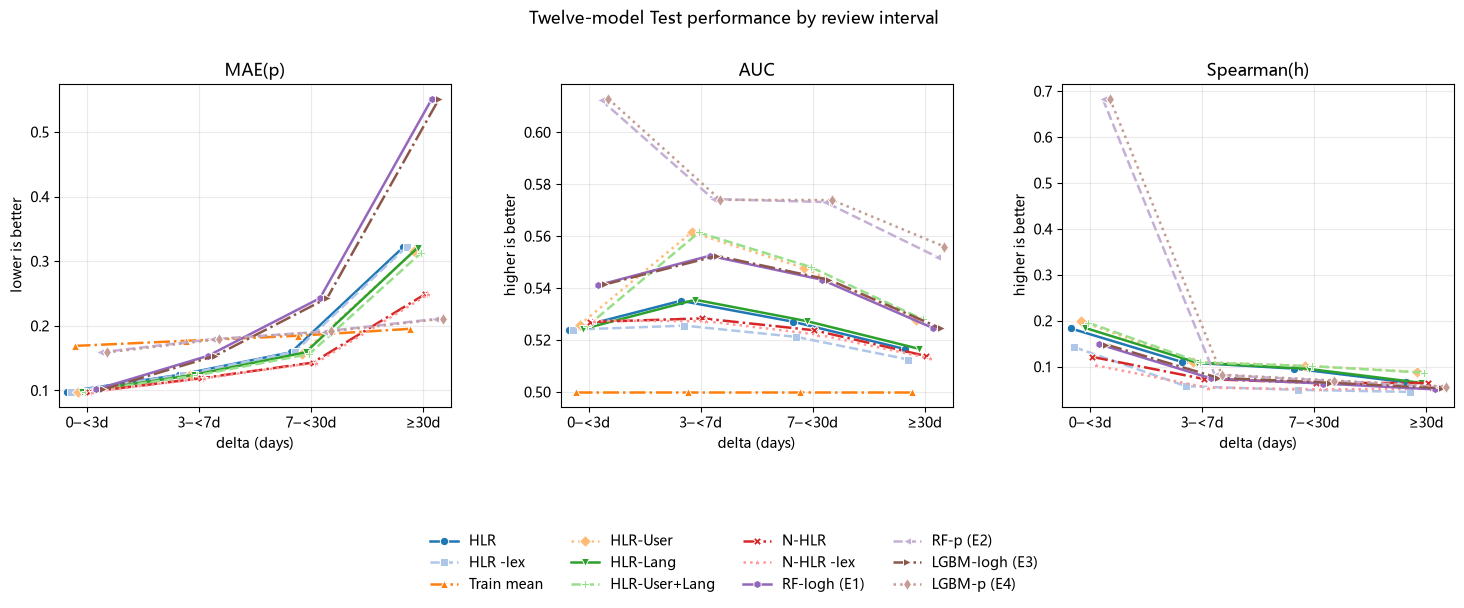

In [45]:
import matplotlib.pyplot as plt

delta_model_order = model_order  # 第 8 节的十二个模型，顺序保持一致
labels = ["[0, 3) 天", "[3, 7) 天", "[7, 30) 天", "[30, +∞) 天"]
test_group_ids = np.searchsorted(np.array([3.0, 7.0, 30.0]),
                                 test_days, side="right")
test_delta_rows = []
for name in delta_model_order:
    p_pred, h_pred = test_predictions[name]
    for group_id, label in enumerate(labels):
        mask = test_group_ids == group_id
        test_delta_rows.append({
            "model": name, "delta 区间": label, "rows": int(mask.sum()),
            "MAE(p)": float(np.abs(p_pred[mask] - test_true_p[mask]).mean()),
            "AUC": auc_fixed(np.rint(test_true_p[mask]), p_pred[mask]),
            "Spearman(h)": (np.nan if name == "Train mean" else
                             spearman_with_ties(test_true_h[mask], h_pred[mask])),
        })
final_test_delta = pd.DataFrame(test_delta_rows)
for name in delta_model_order:
    part = final_test_delta[final_test_delta["model"] == name]
    overall = float(final_summary.loc[
        (final_summary["model"] == name) & (final_summary["split"] == "Test"),
        "MAE(p)",
    ].iloc[0])
    assert part["rows"].sum() == n_test
    assert np.isclose(np.average(part["MAE(p)"], weights=part["rows"]), overall)


delta_order = ["[0, 3) 天", "[3, 7) 天", "[7, 30) 天", "[30, +∞) 天"]
delta_counts = (final_test_delta[final_test_delta["model"] == "HLR"]
                .set_index("delta 区间").loc[delta_order, "rows"])
print("Test 各 delta 区间的样本数；十二个模型共用这些行。")
display(delta_counts.rename("rows").to_frame())

delta_matrices = {}
for metric in ("MAE(p)", "AUC", "Spearman(h)"):
    matrix = (final_test_delta.pivot(index="model", columns="delta 区间",
                                     values=metric)
              .loc[delta_model_order, delta_order])
    assert matrix.shape == (12, 4)
    if metric == "Spearman(h)":
        assert matrix.loc["Train mean"].isna().all()
        assert np.isfinite(matrix.drop(index="Train mean").to_numpy()).all()
    else:
        assert np.isfinite(matrix.to_numpy()).all()
    delta_matrices[metric] = matrix
    print(f"Test {metric}：逐行比较十二个模型；逐列比较同一复习间隔。")
    display(matrix.round(6))

plot_labels = ["0–<3d", "3–<7d", "7–<30d", "≥30d"]
colors = plt.get_cmap("tab20").colors
markers = ["o", "s", "^", "D", "v", "P", "X", "*", "h", "<", ">", "d"]
line_styles = ["-", "--", "-.", ":", "-", "--", "-.", ":", "-", "--", "-.", ":"]
x_centers = np.arange(4)
fig, axes = plt.subplots(1, 3, figsize=(18, 6.2), sharex=True)
for model_index, model_name in enumerate(delta_model_order):
    # 只横向错开绘图位置；每个点的 y 值仍是表中的真实指标。
    x_positions = x_centers + (model_index - 5.5) * 0.032
    for ax, metric in zip(axes, ("MAE(p)", "AUC", "Spearman(h)")):
        if model_name == "Train mean" and metric == "Spearman(h)":
            continue
        ax.plot(x_positions, delta_matrices[metric].loc[model_name].to_numpy(),
                marker=markers[model_index], linestyle=line_styles[model_index],
                linewidth=1.8, markersize=6, markeredgecolor="white",
                markeredgewidth=0.7, color=colors[model_index],
                label=model_name)
for ax, metric in zip(axes, ("MAE(p)", "AUC", "Spearman(h)")):
    ax.set_title(metric)
    ax.set_xticks(x_centers, plot_labels)
    ax.set_xlim(-0.25, 3.25)
    ax.set_xlabel("delta (days)")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("lower is better")
axes[1].set_ylabel("higher is better")
axes[2].set_ylabel("higher is better")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, 0.02), frameon=False)
fig.suptitle('Twelve-model Test performance by review interval')
fig.subplots_adjust(bottom=0.34, wspace=0.28, top=0.86)
plt.show()


**读图说明。**颜色和标记对应十二个模型。接近的曲线在每个 delta 档位沿横轴轻微错开，纵轴指标值不变；精确数值见上方三张表。各组样本数不同，解读趋势时先看样本数表。E2/E4 的半衰期 Spearman 使用反推值。

Train mean 只预测 p，半衰期 Spearman 留空。


# 11. 拓展分析

以下分析检查树模型的逐样本输出，以及概率校准和遗忘风险排序。


## 11.1 RF 与 LightGBM：逐样本预测是否相同

比较同一批 Test 行的 E1（RF-logh）与 E3（LGBM-logh），以及 E2（RF-p）与 E4（LGBM-p）。裁剪后的 `p_hat` 直接使用第 8 节的 `test_predictions`；裁剪前输出通过已训练模型分批重新预测，**不重新训练**。E1/E3 的原始输出为 `log2(h)`，E2/E4 的原始输出为 `p`，两种原始尺度不要互相比大小。

对每一组和每种尺度计算 Pearson、Spearman、`mean(d)`、`mean(|d|)`、`|d|` 的 P50/P90/P99、`|d|<1e-6` 占比和完全相等占比。另列出两模型同时落在相同裁剪边界的占比，并核对原始输出重新换算后的 `p_hat` 与第 8 节保存的逐行预测是否一致。统计和差异直方图使用**全部 Test 行**；散点图固定抽取 20,000 行。运行本节需要原 kernel 中保留第 8 节的模型与 `test_predictions`。

In [46]:
import numpy as np
import pandas as pd
from IPython.display import display

diag_required = [
    "test_predictions", "records", "splits", "RF_BATCH", "MIN_P", "MAX_P",
    "LOG_MIN_H", "LOG_MAX_H", "rf_x_from_records", "rf_p_x_from_records",
    "rf_e1_model", "rf_e2_model", "lgbm_e3_model", "lgbm_e4_model",
    "spearman_with_ties",
]
diag_missing = [name for name in diag_required if name not in globals()]
if diag_missing:
    raise RuntimeError(
        "Missing variables from the current kernel: " + ", ".join(diag_missing)
        + ". This section needs the trained models and section 8 test_predictions."
    )

diag_test_start, diag_test_stop = splits["Test"]
diag_n_test = diag_test_stop - diag_test_start

def diag_metric_row(pair, space, rf_values, lgb_values):
    rf_values = np.asarray(rf_values, dtype=np.float64)
    lgb_values = np.asarray(lgb_values, dtype=np.float64)
    assert rf_values.shape == lgb_values.shape == (diag_n_test,)
    assert np.isfinite(rf_values).all() and np.isfinite(lgb_values).all()
    d = rf_values - lgb_values
    abs_d = np.abs(d)
    p50, p90, p99 = np.quantile(abs_d, [0.50, 0.90, 0.99])
    pearson = (float(np.corrcoef(rf_values, lgb_values)[0, 1])
               if np.std(rf_values) > 0 and np.std(lgb_values) > 0
               else np.nan)
    return {
        "pair": pair, "space": space, "n_test": diag_n_test,
        "Pearson": pearson,
        "Spearman": spearman_with_ties(rf_values, lgb_values),
        "mean_d": float(d.mean()),
        "mean_abs_d": float(abs_d.mean()),
        "P50_abs_d": float(p50), "P90_abs_d": float(p90),
        "P99_abs_d": float(p99),
        "share_abs_lt_1e-6": float(np.mean(abs_d < 1e-6)),
        "share_exact": float(np.mean(d == 0)),
    }

diag_pairs = [
    ("E1 vs E3", "RF-logh (E1)", "LGBM-logh (E3)",
     rf_e1_model, lgbm_e3_model, rf_x_from_records, "raw_log2_h", True),
    ("E2 vs E4", "RF-p (E2)", "LGBM-p (E4)",
     rf_e2_model, lgbm_e4_model, rf_p_x_from_records, "raw_p", False),
]
diag_stat_rows = []
diag_boundary_rows = []
diag_check_rows = []

for pair, rf_name, lgb_name, rf_model, lgb_model, make_x, raw_space, predicts_logh in diag_pairs:
    rf_p = np.asarray(test_predictions[rf_name][0], dtype=np.float64)
    lgb_p = np.asarray(test_predictions[lgb_name][0], dtype=np.float64)
    assert rf_p.shape == lgb_p.shape == (diag_n_test,)
    diag_stat_rows.append(diag_metric_row(pair, "clipped_p", rf_p, lgb_p))

    same_bound = ((rf_p == MIN_P) & (lgb_p == MIN_P)) | (
        (rf_p == MAX_P) & (lgb_p == MAX_P)
    )
    both_interior = ((MIN_P < rf_p) & (rf_p < MAX_P)
                     & (MIN_P < lgb_p) & (lgb_p < MAX_P))
    diag_boundary_rows.append({
        "pair": pair,
        "same_p_bound_share": float(same_bound.mean()),
        "n_both_interior": int(both_interior.sum()),
        "share_abs_lt_1e-6_interior": (
            float(np.mean(np.abs(rf_p[both_interior] - lgb_p[both_interior]) < 1e-6))
            if both_interior.any() else np.nan
        ),
    })

    rf_raw = np.empty(diag_n_test, dtype=np.float64)
    lgb_raw = np.empty(diag_n_test, dtype=np.float64)
    rf_reconstruction_max = 0.0
    lgb_reconstruction_max = 0.0
    for left in range(diag_test_start, diag_test_stop, RF_BATCH):
        right = min(left + RF_BATCH, diag_test_stop)
        batch = records[left:right]
        x = make_x(batch)
        lo, hi = left - diag_test_start, right - diag_test_start
        rf_chunk = rf_model.predict(x)
        lgb_chunk = lgb_model.predict(x, num_iteration=lgb_model.best_iteration_)
        rf_raw[lo:hi] = rf_chunk
        lgb_raw[lo:hi] = lgb_chunk

        if predicts_logh:
            rf_h = np.exp2(np.clip(rf_chunk, LOG_MIN_H, LOG_MAX_H))
            lgb_h = np.exp2(np.clip(lgb_chunk, LOG_MIN_H, LOG_MAX_H))
            rf_rebuilt = np.clip(
                np.exp2(-batch["delta_days"] / rf_h), MIN_P, MAX_P
            )
            lgb_rebuilt = np.clip(
                np.exp2(-batch["delta_days"] / lgb_h), MIN_P, MAX_P
            )
        else:
            rf_rebuilt = np.clip(rf_chunk, MIN_P, MAX_P)
            lgb_rebuilt = np.clip(lgb_chunk, MIN_P, MAX_P)
        rf_reconstruction_max = max(
            rf_reconstruction_max, float(np.max(np.abs(rf_rebuilt - rf_p[lo:hi])))
        )
        lgb_reconstruction_max = max(
            lgb_reconstruction_max, float(np.max(np.abs(lgb_rebuilt - lgb_p[lo:hi])))
        )

    diag_stat_rows.append(diag_metric_row(pair, raw_space, rf_raw, lgb_raw))
    diag_check_rows.append({
        "pair": pair,
        "max_rebuild_error_RF": rf_reconstruction_max,
        "max_rebuild_error_LGBM": lgb_reconstruction_max,
    })
    del rf_raw, lgb_raw, same_bound, both_interior

diag_stats = pd.DataFrame(diag_stat_rows)
diag_boundary = pd.DataFrame(diag_boundary_rows)
diag_reconstruction = pd.DataFrame(diag_check_rows)
assert (diag_reconstruction[["max_rebuild_error_RF",
                             "max_rebuild_error_LGBM"]].to_numpy() < 1e-10).all()
with pd.option_context("display.float_format", lambda value: f"{value:.6g}"):
    display(diag_stats)
    display(diag_boundary)
    display(diag_reconstruction)


,pair,space,n_test,Pearson,Spearman,mean_d,mean_abs_d,P50_abs_d,P90_abs_d,P99_abs_d,share_abs_lt_1e-6,share_exact
0,E1 vs E3,clipped_p,1285415,0.999839,0.999821,5.40839e-05,0.000677724,5.28721e-05,0.00146051,0.00942326,0.290873,0.23349
1,E1 vs E3,raw_log2_h,1285415,0.998481,0.998007,8.83455e-05,0.0158254,0.00819329,0.0279267,0.158902,0,0
2,E2 vs E4,clipped_p,1285415,0.976632,0.984299,7.59294e-06,0.00357975,0.00186114,0.00669609,0.0325417,0.000881427,0
3,E2 vs E4,raw_p,1285415,0.976632,0.984299,7.51957e-06,0.00357982,0.00186114,0.00669609,0.0325453,0.000881427,0


,pair,same_p_bound_share,n_both_interior,share_abs_lt_1e-6_interior
0,E1 vs E3,0.23349,983133,0.0740073
1,E2 vs E4,0,1285378,0.000881453


,pair,max_rebuild_error_RF,max_rebuild_error_LGBM
0,E1 vs E3,8.32667e-16,0
1,E2 vs E4,5.55112e-16,0


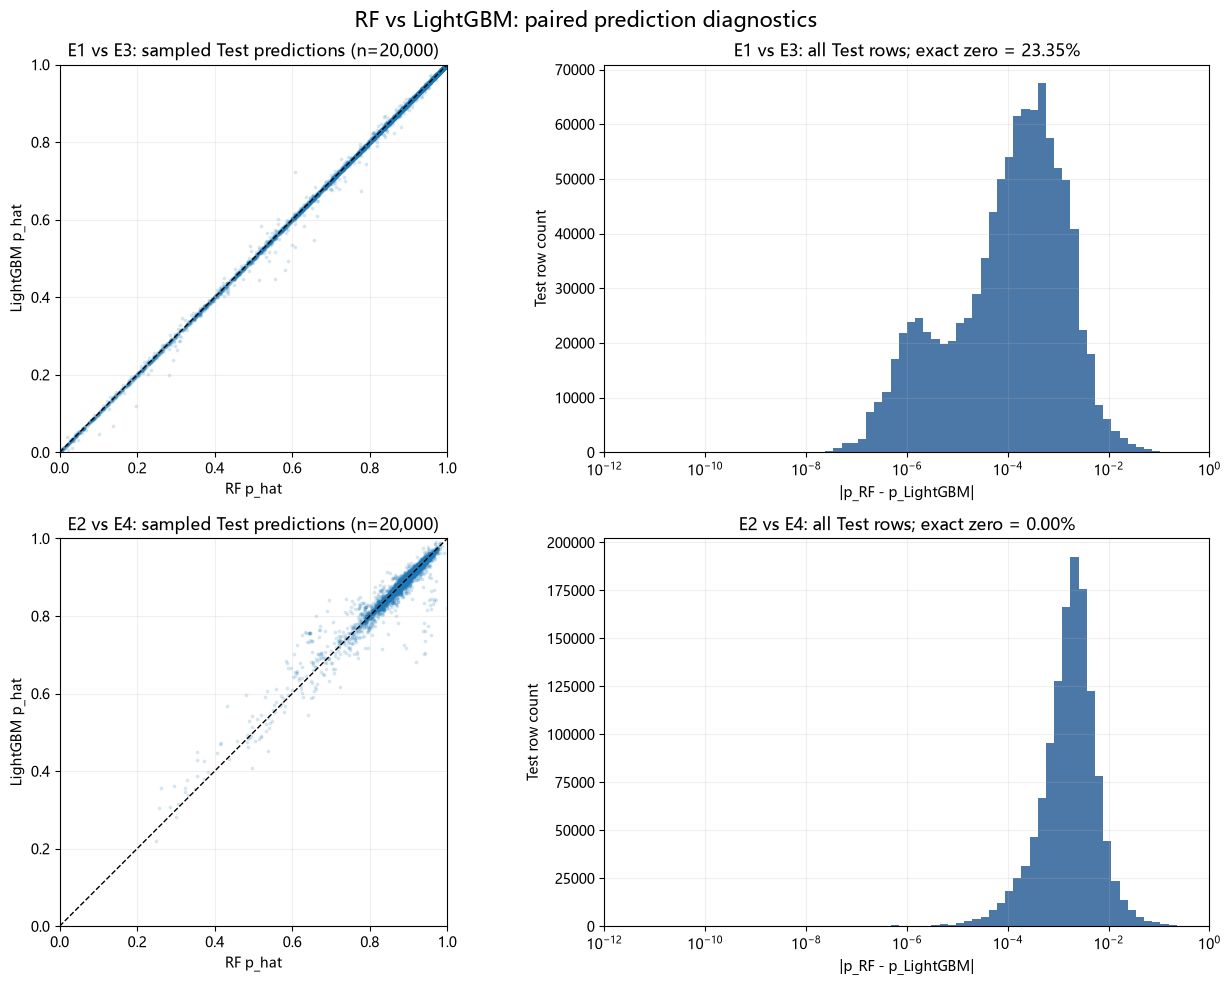

In [47]:
import matplotlib.pyplot as plt

diag_scatter_n = min(20_000, diag_n_test)
diag_sample = np.random.default_rng(20261115).choice(
    diag_n_test, size=diag_scatter_n, replace=False
)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, (pair, rf_name, lgb_name, *_rest) in enumerate(diag_pairs):
    rf_p = test_predictions[rf_name][0]
    lgb_p = test_predictions[lgb_name][0]
    ax_scatter, ax_hist = axes[row]
    ax_scatter.scatter(
        rf_p[diag_sample], lgb_p[diag_sample],
        s=7, alpha=0.18, linewidths=0, rasterized=True,
    )
    ax_scatter.plot([MIN_P, MAX_P], [MIN_P, MAX_P], "k--", linewidth=1)
    ax_scatter.set(xlim=(0, 1), ylim=(0, 1),
                   xlabel="RF p_hat", ylabel="LightGBM p_hat",
                   title=f"{pair}: sampled Test predictions (n={diag_scatter_n:,})")
    ax_scatter.set_aspect("equal", adjustable="box")
    ax_scatter.grid(alpha=0.2)

    abs_d = np.abs(rf_p - lgb_p)
    positive = abs_d[abs_d > 0]
    ax_hist.hist(np.maximum(positive, 1e-12),
                 bins=np.logspace(-12, 0, 75),
                 color="#4C78A8", edgecolor="none")
    ax_hist.set_xscale("log")
    ax_hist.set(xlim=(1e-12, 1), xlabel="|p_RF - p_LightGBM|",
                ylabel="Test row count",
                title=f"{pair}: all Test rows; exact zero = {(abs_d == 0).mean():.2%}")
    ax_hist.grid(alpha=0.2)

fig.suptitle("RF vs LightGBM: paired prediction diagnostics", fontsize=15)
fig.tight_layout()
plt.show()


**读表与读图：**相关系数接近 1 表示排序或线性关系接近，不能单独证明逐条预测相同；要同时看绝对差异及裁剪前结果。`share_*` 列为 0–1 的比例。散点图中虚线是 `y=x`；右侧直方图统计全部 Test 行的正差异，横轴为对数刻度，完全相等的占比写在标题中。小于 `1e-12` 的正差异归入第一个柱。

## 11.2 树模型更适合排序，HLR 更适合概率预测吗？

本节对同一批 Test session 比较 HLR、N-HLR、RF-p (E2)、LGBM-p (E4)，复用第 8 节的 `test_predictions`，不重新训练。实验 A 检查记录级预测 `p_hat` 对裁剪后 `p_target` 的校准；实验 B 检查预测最低的前 K% 记录是否真的有较高的 `1-p_target`。Train 均值常数预测用于校准参照；随机排序的期望 Lift 为 1。

**指标口径：**每条 session 等权。ECE 使用 10 个等宽预测区间，并同时展示每箱行数；MSE 用于补充校准与预测区分度。AUC 沿用第 8 节的 `np.rint(p_target)` 二值标签，Risk@K 则使用连续的 `1-p_target`。二者衡量的排序目标不同。

Test mean p_target = 0.895429; Train mean constant = 0.896182


,model,n_test,mean_pred,std_pred,MAE,MSE,RMSE,ECE10,AUC
0,HLR,1285415,0.962835,0.091981,0.128033,0.084610,0.290877,0.092700,0.537856
1,N-HLR,1285415,0.976572,0.061257,0.118898,0.082553,0.287320,0.091706,0.539874
2,RF-p (E2),1285415,0.894972,0.044565,0.170206,0.071567,0.267520,0.000520,0.604966
3,LGBM-p (E4),1285415,0.894965,0.044095,0.170254,0.071577,0.267539,0.000509,0.605412
4,Train mean,1285415,0.896182,0.000000,0.174210,0.073516,0.271138,0.000753,0.500000


model,HLR,N-HLR,RF-p (E2),LGBM-p (E4),Train mean
pred_bin,,,,,
"[0.0, 0.1)",8,15,0,0,0
"[0.1, 0.2)",288,24,4,0,0
"[0.2, 0.3)",2195,65,170,109,0
"[0.3, 0.4)",5350,261,735,827,0
"[0.4, 0.5)",6321,1950,1546,1574,0
"[0.5, 0.6)",9035,6320,2254,1927,0
"[0.6, 0.7)",15042,8334,4914,3975,0
"[0.7, 0.8)",24522,18681,19819,20675,0
"[0.8, 0.9)",62164,42775,571386,563797,1285415


,model,pred_bin,n_bin,share,mean_pred,mean_true,calibration_gap_true_minus_pred
0,HLR,"[0.0, 0.1)",8,0.000006,0.091406,0.874925,0.783519
1,HLR,"[0.1, 0.2)",288,0.000224,0.167209,0.831415,0.664205
2,HLR,"[0.2, 0.3)",2195,0.001708,0.262470,0.848529,0.586059
3,HLR,"[0.3, 0.4)",5350,0.004162,0.354459,0.854150,0.499691
4,HLR,"[0.4, 0.5)",6321,0.004917,0.449468,0.855668,0.406200
5,HLR,"[0.5, 0.6)",9035,0.007029,0.555538,0.854841,0.299302
6,HLR,"[0.6, 0.7)",15042,0.011702,0.652173,0.868351,0.216178
7,HLR,"[0.7, 0.8)",24522,0.019077,0.756231,0.866500,0.110269
8,HLR,"[0.8, 0.9)",62164,0.048361,0.858280,0.872301,0.014021
9,HLR,"[0.9, 1.0]",1160490,0.902813,0.987128,0.898457,-0.088671


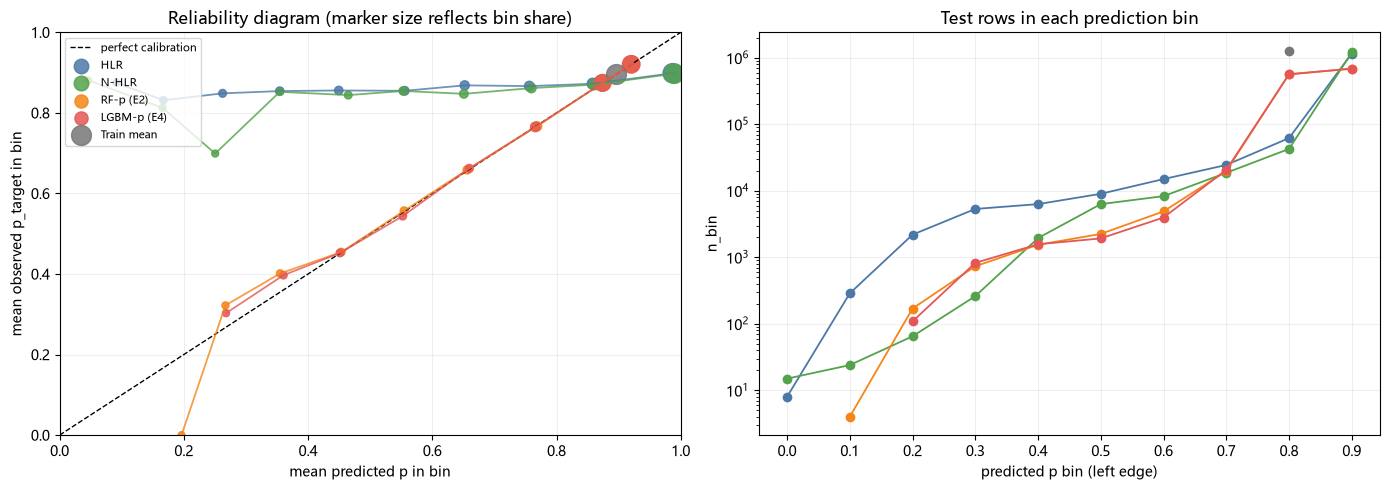

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

task93_needed = [
    "records", "train_end", "test_true_p", "test_days",
    "test_predictions", "auc_fixed", "MIN_P", "MAX_P",
]
task93_missing = [name for name in task93_needed if name not in globals()]
if task93_missing:
    raise RuntimeError(
        "Section 11.2 needs the current kernel's section 8 results: "
        + ", ".join(task93_missing)
    )

task93_model_names = ["HLR", "N-HLR", "RF-p (E2)", "LGBM-p (E4)"]
task93_true = np.asarray(test_true_p, dtype=np.float64)
task93_days = np.asarray(test_days, dtype=np.float64)
task93_n = len(task93_true)
task93_train_mean = float(records["p_target"][:train_end].mean())
task93_predictions = {
    name: np.asarray(test_predictions[name][0], dtype=np.float64)
    for name in task93_model_names
}
task93_predictions["Train mean"] = np.full(
    task93_n, task93_train_mean, dtype=np.float64
)
assert len(task93_days) == task93_n
assert all(len(pred) == task93_n and np.isfinite(pred).all()
           for pred in task93_predictions.values())
assert all(np.all((MIN_P <= pred) & (pred <= MAX_P))
           for pred in task93_predictions.values())

task93_edges = np.linspace(0.0, 1.0, 11)
task93_bin_labels = [
    f"[{task93_edges[b]:.1f}, {task93_edges[b+1]:.1f})"
    if b < 9 else "[0.9, 1.0]"
    for b in range(10)
]
task93_binary_recall = np.rint(task93_true)
task93_cal_rows = []
task93_summary_rows = []
for name, pred in task93_predictions.items():
    bin_id = np.clip(
        np.searchsorted(task93_edges, pred, side="right") - 1, 0, 9
    )
    ece = 0.0
    for b, label in enumerate(task93_bin_labels):
        mask = bin_id == b
        n_bin = int(mask.sum())
        mean_pred = float(pred[mask].mean()) if n_bin else np.nan
        mean_true = float(task93_true[mask].mean()) if n_bin else np.nan
        gap = mean_true - mean_pred if n_bin else np.nan
        if n_bin:
            ece += (n_bin / task93_n) * abs(gap)
        task93_cal_rows.append({
            "model": name, "pred_bin": label, "n_bin": n_bin,
            "share": n_bin / task93_n,
            "mean_pred": mean_pred, "mean_true": mean_true,
            "calibration_gap_true_minus_pred": gap,
        })
    error = pred - task93_true
    mse = float(np.mean(error ** 2))
    task93_summary_rows.append({
        "model": name, "n_test": task93_n,
        "mean_pred": float(pred.mean()), "std_pred": float(pred.std()),
        "MAE": float(np.mean(np.abs(error))),
        "MSE": mse, "RMSE": float(np.sqrt(mse)),
        "ECE10": float(ece),
        "AUC": auc_fixed(task93_binary_recall, pred),
    })

task93_calibration = pd.DataFrame(task93_cal_rows)
task93_summary = pd.DataFrame(task93_summary_rows)
task93_counts = task93_calibration.pivot(
    index="pred_bin", columns="model", values="n_bin"
).loc[task93_bin_labels, list(task93_predictions)]
print(f"Test mean p_target = {task93_true.mean():.6f}; "
      f"Train mean constant = {task93_train_mean:.6f}")
display(task93_summary.round(6))
display(task93_counts)
display(task93_calibration.round(6))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ["#4C78A8", "#54A24B", "#F58518", "#E45756", "#777777"]
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="perfect calibration")
for (name, color) in zip(task93_predictions, colors):
    part = task93_calibration[
        (task93_calibration["model"] == name)
        & (task93_calibration["n_bin"] > 0)
    ]
    axes[0].plot(
        part["mean_pred"], part["mean_true"],
        color=color, linewidth=1.3, alpha=0.8,
    )
    axes[0].scatter(
        part["mean_pred"], part["mean_true"],
        s=24 + 180 * np.sqrt(part["share"]),
        color=color, alpha=0.85, label=name,
    )
    occupied = part["pred_bin"].map(
        {label: i for i, label in enumerate(task93_bin_labels)}
    ).to_numpy()
    axes[1].plot(
        occupied + 0.5, part["n_bin"], marker="o",
        color=color, linewidth=1.3, label=name,
    )
axes[0].set(
    title="Reliability diagram (marker size reflects bin share)",
    xlim=(0, 1), ylim=(0, 1),
    xlabel="mean predicted p in bin",
    ylabel="mean observed p_target in bin",
)
axes[1].set(
    title="Test rows in each prediction bin",
    xticks=np.arange(10) + 0.5,
    xticklabels=[f"{b/10:.1f}" for b in range(10)],
    xlabel="predicted p bin (left edge)", ylabel="n_bin",
)
axes[1].set_yscale("log")
for ax in axes:
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()


### 实验 B：Top-K 回忆失败风险排序

按预测 `p_hat` 从低到高排序，取前 5%、10%、20% 的 Test 行，计算其真实平均风险 `Risk@K=mean(1-p_target)` 和 `Lift@K=Risk@K/mean(1-p_target)`。曲线展示 1%–50%。随机排序基线只给出**期望值**（Risk 等于总体平均风险、Lift=1）；常数预测存在完全并列，不能产生有意义的排序。

另在 `[0,3)`、`[3,7)`、`[7,30)`、`[30,+∞)` 天四个 delta 区间内分别取最低预测的前 10%，以检查总体排序优势是否仅来自复习间隔差异。

Overall Test forgetting risk = 0.104571


,model,K_percent,n_selected,Risk_at_K,Lift_at_K
0,HLR,5,64271,0.137415,1.314078
1,HLR,10,128542,0.132468,1.266774
2,HLR,20,257083,0.125897,1.203932
3,N-HLR,5,64271,0.138100,1.320630
4,N-HLR,10,128542,0.133441,1.276080
5,N-HLR,20,257083,0.127057,1.215027
6,RF-p (E2),5,64271,0.232019,2.218762
7,RF-p (E2),10,128542,0.193133,1.846898
8,RF-p (E2),20,257083,0.163905,1.567400
9,LGBM-p (E4),5,64271,0.232079,2.219340


Train mean has no ranking; its Risk/Lift columns show random-tie expectation.


,model,MAE,MSE,ECE10,AUC,Risk@10%,Lift@10%,Risk@20%,Lift@20%
0,HLR,0.128033,0.084610,0.092700,0.537856,0.132468,1.266774,0.125897,1.203932
1,N-HLR,0.118898,0.082553,0.091706,0.539874,0.133441,1.276080,0.127057,1.215027
2,RF-p (E2),0.170206,0.071567,0.000520,0.604966,0.193133,1.846898,0.163905,1.567400
3,LGBM-p (E4),0.170254,0.071577,0.000509,0.605412,0.193477,1.850192,0.164237,1.570572
4,Train mean,0.174210,0.073516,0.000753,0.500000,0.104571,1.000000,0.104571,1.000000


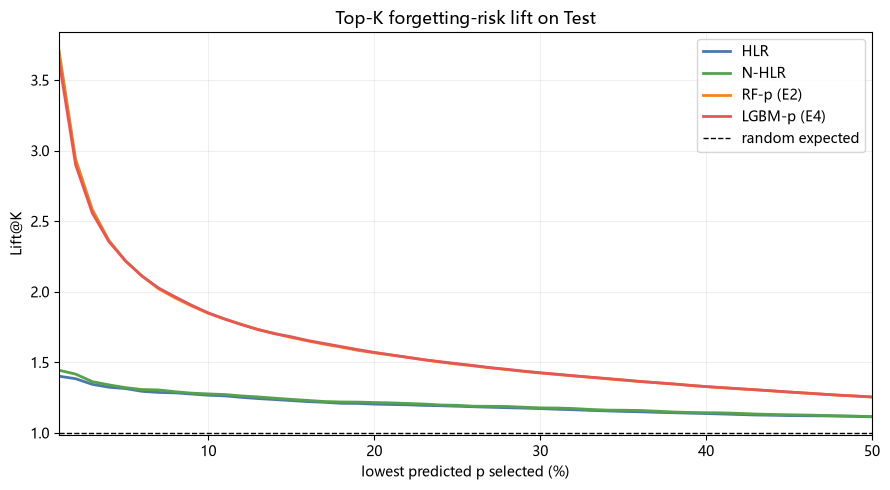

,delta_band,model,n_band,n_selected,band_mean_risk,Risk@10%,Lift@10%
0,"[0, 3) days",HLR,824807,82481,0.096830,0.116172,1.199755
1,"[0, 3) days",N-HLR,824807,82481,0.096830,0.121265,1.252348
2,"[0, 3) days",RF-p (E2),824807,82481,0.096830,0.196383,2.028130
3,"[0, 3) days",LGBM-p (E4),824807,82481,0.096830,0.195563,2.019656
4,"[3, 7) days",HLR,173511,17352,0.110646,0.135243,1.222297
5,"[3, 7) days",N-HLR,173511,17352,0.110646,0.136989,1.238083
6,"[3, 7) days",RF-p (E2),173511,17352,0.110646,0.179057,1.618284
7,"[3, 7) days",LGBM-p (E4),173511,17352,0.110646,0.178921,1.617054
8,"[7, 30) days",HLR,185917,18592,0.118455,0.137608,1.161692
9,"[7, 30) days",N-HLR,185917,18592,0.118455,0.134913,1.138943


In [49]:
task93_risk = 1.0 - task93_true
task93_base_risk = float(task93_risk.mean())
assert task93_base_risk > 0
task93_curve_rows = []
task93_selected_rows = []
task93_curve_percents = np.arange(1, 51)

for name in task93_model_names:
    order = np.argsort(task93_predictions[name], kind="stable")
    cumulative_risk = np.cumsum(task93_risk[order], dtype=np.float64)
    for percent in task93_curve_percents:
        k = int(np.ceil(task93_n * percent / 100))
        selected_risk = float(cumulative_risk[k - 1] / k)
        row = {
            "model": name, "K_percent": int(percent), "n_selected": k,
            "Risk_at_K": selected_risk,
            "Lift_at_K": selected_risk / task93_base_risk,
        }
        task93_curve_rows.append(row)
        if percent in (5, 10, 20):
            task93_selected_rows.append(row)

for percent in (5, 10, 20):
    task93_selected_rows.append({
        "model": "Random expected", "K_percent": percent,
        "n_selected": int(np.ceil(task93_n * percent / 100)),
        "Risk_at_K": task93_base_risk, "Lift_at_K": 1.0,
    })
task93_curve = pd.DataFrame(task93_curve_rows)
task93_selected = pd.DataFrame(task93_selected_rows)
print(f"Overall Test forgetting risk = {task93_base_risk:.6f}")
display(task93_selected.round(6))

task93_joint_rows = []
for _, summary_row in task93_summary.iterrows():
    name = summary_row["model"]
    row = {key: summary_row[key] for key in
           ("model", "MAE", "MSE", "ECE10", "AUC")}
    for percent in (10, 20):
        if name == "Train mean":
            risk_k, lift_k = task93_base_risk, 1.0
        else:
            selected = task93_selected.loc[
                (task93_selected["model"] == name)
                & (task93_selected["K_percent"] == percent)
            ].iloc[0]
            risk_k = float(selected["Risk_at_K"])
            lift_k = float(selected["Lift_at_K"])
        row[f"Risk@{percent}%"] = risk_k
        row[f"Lift@{percent}%"] = lift_k
    task93_joint_rows.append(row)
task93_joint = pd.DataFrame(task93_joint_rows)
print("Train mean has no ranking; its Risk/Lift columns show random-tie expectation.")
display(task93_joint.round(6))

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#4C78A8", "#54A24B", "#F58518", "#E45756"]
for name, color in zip(task93_model_names, colors):
    part = task93_curve[task93_curve["model"] == name]
    ax.plot(
        part["K_percent"], part["Lift_at_K"],
        linewidth=2, label=name, color=color,
    )
ax.axhline(1.0, color="black", linestyle="--", linewidth=1,
           label="random expected")
ax.set(
    title="Top-K forgetting-risk lift on Test",
    xlabel="lowest predicted p selected (%)",
    ylabel="Lift@K", xlim=(1, 50),
)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

task93_delta_names = ["[0, 3) days", "[3, 7) days",
                      "[7, 30) days", "[30, +inf) days"]
task93_delta_id = np.searchsorted(
    np.array([3.0, 7.0, 30.0]), task93_days, side="right"
)
task93_delta_rows = []
for band, band_name in enumerate(task93_delta_names):
    indices = np.flatnonzero(task93_delta_id == band)
    n_band = len(indices)
    base_band_risk = float(task93_risk[indices].mean())
    k = int(np.ceil(n_band * 0.10))
    for name in task93_model_names:
        order = np.argsort(task93_predictions[name][indices], kind="stable")
        selected = indices[order[:k]]
        selected_risk = float(task93_risk[selected].mean())
        task93_delta_rows.append({
            "delta_band": band_name, "model": name, "n_band": n_band,
            "n_selected": k, "band_mean_risk": base_band_risk,
            "Risk@10%": selected_risk,
            "Lift@10%": selected_risk / base_band_risk,
        })
task93_delta_ranking = pd.DataFrame(task93_delta_rows)
display(task93_delta_ranking.round(6))


**如何判断：**若 HLR 的 ECE 较低，还须检查它的 MSE、预测标准差和各箱行数；常数均值可能校准很好却没有排序能力。若 Direct-p 的 AUC 和 Risk/Lift@K 都较高，说明它在**已发生的 Test session** 中更能找出低回忆率记录。delta 分层结果用于判断这项优势在相近间隔内是否仍存在。日志不含每个时刻所有可选词元，本节不能直接衡量实际复习排程收益；当前缓存也没有 `user_id` 或 `session_seen`，因此本节没有做同一学习者内排序或按练习次数加权的校准。